# Bagian B – SigLIP Embedding Probe (Ekstrak Sekali → Train Head Cepat)

**Checkpoint:** `google/siglip-so400m-patch14-384`

## Alur (2 tahap)

```
TAHAP 1 – dijalankan SEKALI (lambat, butuh GPU)
  gambar → [augmentasi] → SigLIP (dibekukan, fp16) → embedding 1152-dim → embeddings_{split}.npz  (di Drive)

TAHAP 2 – bisa diulang berkali-kali (hitungan detik/menit per run)
  embeddings_{split}.npz → load → train head → evaluasi
  (ganti/bandingkan arsitektur: linear, MLP, MLP+norm, MLP 2 tahap, ResMLP, kNN, SVM, LightGBM, ensemble)
```

Kenapa lebih cepat dari notebook sebelumnya: di notebook lama, **setiap epoch** semua gambar dibaca ulang,
diaugmentasi, lalu dilewatkan ke backbone SigLIP (~400M parameter) walaupun backbone dibekukan. Di sini backbone
hanya dipakai **satu kali per gambar**; training head bekerja di atas vektor 1152-dim yang sudah tersimpan.

### Perubahan v2 (metodologi, generalisasi, kebersihan data)

| Area | Perubahan | Alasan |
|---|---|---|
| Class weight | `CLASS_WEIGHT_MODE='effective'`: rumus `N/(C*N_c)` dihitung dari jumlah **baris** train `.npz` | `N_AUG` B3=5 vs 2 sudah oversampling ~2x; bobot json (dari jumlah gambar) membuat B3 dikompensasi dobel |
| Loss | default CrossEntropy + label smoothing 0.05 (Focal opsional, bug `pt` berbobot diperbaiki) | Focal memperbesar bobot sampel sulit = termasuk sampel salah label |
| Regularisasi | Mixup di ruang embedding (`MIXUP_ALPHA`) | batas kelas lebih halus, generalisasi lebih baik |
| Diagnostik data | Cell 12b/12c: OOF `StratifiedGroupKFold` (group `orig_idx`), confident learning + kNN, near-duplicate lintas split, outlier centroid | data cleaning dari **train**, bukan dari test |
| Evaluasi jujur | kolom `macro_F1_nodup` (val tanpa near-duplicate train) + macro F1 OOF | skor val tidak digelembungkan oleh duplikat mirip |
| Test | `mark_test_use()` memperingatkan bila test dipakai > 1 model; error analysis dipindah ke **val** | aturan "test disentuh sekali" |
| SVM | C dipilih dari `SVM_C_GRID` via macro F1 val; ensemble lintas keluarga (MLP seed + kNN + SVM) | |

**Prasyarat:** sudah menjalankan preprocessing (`train.csv`, `val.csv`, `test.csv`, `class_weights.json`) dan upload ke Google Drive.


---
## CELL 1 – Mount Google Drive


In [ ]:
# Mount Google Drive HANYA bila berjalan di Colab. Di lokal (GPU Colab via tunnel ngrok,
# atau GPU sendiri) cell ini dilewati karena data sudah ada di disk lokal.
# try:
#     import google.colab  # noqa: F401
#     _IN_COLAB = True
# except ImportError:
#     _IN_COLAB = False

# if _IN_COLAB:
#     from google.colab import drive
#     drive.mount('/content/drive', force_remount=False)
#     print('[OK] Google Drive berhasil di-mount (Colab).')
# else:
#     print('[SKIP] Bukan Colab -> tidak mount Drive. Pastikan ENV/ROOT_DIR di Cell 2 menunjuk path lokal.')


---
## CELL 2 – Konfigurasi Utama


In [1]:
import os
# ============================================================
# KONFIGURASI
# ------------------------------------------------------------
# ENV menentukan lokasi data. CUKUP GANTI SATU VARIABEL INI:
#   'auto'  -> deteksi otomatis (Colab -> Drive; selain itu -> lokal)
#   'local' -> pakai ROOT_LOCAL (repo di mesin ini / GPU Colab via tunnel ngrok)
#   'colab' -> pakai ROOT_COLAB (Google Drive)
# ============================================================
ENV = 'auto'   # 'auto' | 'local' | 'colab'  (set manual kalau auto salah tebak)

ROOT_LOCAL = r'd:\UGM\Semester 5\Senpro\Project\Senpro'   # path repo di mesin lokal (Windows)
ROOT_COLAB = '/content/drive/MyDrive/Senpro'                   # path di Google Drive

def _has_manifest(root):
    return os.path.exists(os.path.join(root, 'preprocessing_output', 'train.csv'))

# 'auto' memilih berdasarkan DI MANA DATA BERADA (bukan sekadar ada/tidaknya modul google.colab),
# supaya kasus "runtime Colab tapi data di disk lokal" tetap benar.
if ENV == 'auto':
    if _has_manifest(ROOT_LOCAL):
        ENV = 'local'
    elif _has_manifest(ROOT_COLAB):
        ENV = 'colab'
    else:
        try:
            import google.colab  # noqa: F401
            ENV = 'colab'
        except ImportError:
            ENV = 'local'
ROOT_DIR = ROOT_COLAB if ENV == 'colab' else ROOT_LOCAL
print(f'[ENV] {ENV}  |  ROOT_DIR = {ROOT_DIR}')
if not _has_manifest(ROOT_DIR):
    print(f'[!!] train.csv TIDAK ADA di {ROOT_DIR}/preprocessing_output. '
          f'Periksa: (1) ENV benar? (2) ROOT_{"LOCAL" if ENV=="local" else "COLAB"} menunjuk lokasi data '
          f'yang terlihat oleh kernel ini? Kalau kernel = runtime Colab remote (GPU Google via ngrok), '
          f'drive d:\\ milik PC Anda TIDAK terlihat -> data harus diunggah ke mesin itu / Drive.')

DATASET_DIR = os.path.join(ROOT_DIR, 'Dataset')
OUTPUT_DIR  = os.path.join(ROOT_DIR, 'preprocessing_output')

TRAIN_CSV = os.path.join(OUTPUT_DIR, 'train.csv')
VAL_CSV   = os.path.join(OUTPUT_DIR, 'val.csv')
TEST_CSV  = os.path.join(OUTPUT_DIR, 'test.csv')
CW_JSON   = os.path.join(OUTPUT_DIR, 'class_weights.json')

# Label mapping (sama seperti notebook sebelumnya)
LABEL_TO_IDX = {'Recylable': 0, 'Organik': 1, 'B3': 2}
IDX_TO_LABEL = {v: k for k, v in LABEL_TO_IDX.items()}
NUM_CLASSES  = len(LABEL_TO_IDX)

RANDOM_SEED = 42

# ------------------------------------------------------------
# TAHAP 1 – Ekstraksi embedding (SigLIP, dijalankan sekali)
# ------------------------------------------------------------
MODEL_CHECKPOINT = 'google/siglip-so400m-patch14-384'
IMAGE_SIZE       = 384

N_AUG = {'Recylable': 2, 'Organik': 2, 'B3': 5}  # jumlah versi TER-AUGMENTASI per gambar train per kelas
                             # total baris train di .npz = jumlah_gambar x (1 + N_AUG). Set 0 = tanpa augmentasi.
BATCH_SIZE_EKSTRAKSI = 32    # jumlah gambar per batch (tiap gambar diproses (1 + N_AUG) view). Turunkan jika OOM.
NUM_WORKERS_EKSTRAKSI = min(8, (os.cpu_count() or 2) * 2)   # Colab gratis biasanya 2 CPU -> 4 worker
USE_FP16         = True      # backbone dijalankan fp16 (lebih cepat & hemat VRAM), hanya untuk ekstraksi
MAX_SISI_GAMBAR  = 1024      # gambar lebih besar dari ini di-downsize dulu (hemat RAM/CPU)
CHUNK_IMAGES     = 1024      # simpan hasil sementara tiap N gambar -> aman kalau Colab disconnect

# Smoke test: set mis. 30 untuk mencoba seluruh alur dengan sedikit gambar per kelas.
# Hasilnya masuk folder terpisah (suffix _debug) sehingga tidak tercampur dengan hasil asli.
DEBUG_MAX_PER_CLASS = None

MODEL_TAG     = MODEL_CHECKPOINT.split('/')[-1]
n_aug_str = f"{N_AUG['Recylable']}_{N_AUG['Organik']}_{N_AUG['B3']}" if isinstance(N_AUG, dict) else str(N_AUG)

# Tanda versi DATASET. Ganti tiap kali data berubah (dedup/cleaning/split baru) supaya embedding
# & hasil head versi lama TIDAK tertimpa dan TIDAK keliru di-skip oleh logika '[SKIP] sudah ada'.
DATA_VERSION  = 'v3clean'     # v2 lama = '' (folder tanpa suffix). v3 (dHash + cleaning R<->O) = 'v3clean'.
_ver_suffix   = f'_{DATA_VERSION}' if DATA_VERSION else ''
EMBEDDING_DIR = os.path.join(ROOT_DIR, 'embeddings', f'{MODEL_TAG}_naug_{n_aug_str}{_ver_suffix}')
if DEBUG_MAX_PER_CLASS:
    EMBEDDING_DIR += '_debug'

# ------------------------------------------------------------
# TAHAP 2 – Training head di atas embedding
# ------------------------------------------------------------
RUN_NAME          = f'mlp_head_{DATA_VERSION}_ce_ls_mixup' if DATA_VERSION else 'mlp_head_v2_ce_ls_mixup'   # ikut DATA_VERSION -> tak menimpa run lama
HEAD_BATCH_SIZE   = 256
HEAD_EPOCHS       = 60
HEAD_LR           = 1e-3
HEAD_WEIGHT_DECAY = 1e-4
DROPOUT_RATE      = 0.3
INPUT_NORM        = 'standardize'   # 'none' | 'l2' | 'standardize' (statistik dihitung dari train saja)

# Arsitektur head
HEAD_TYPE = 'mlp'            # untuk training SATU head (Cell 13): 'linear' | 'mlp' | 'mlp_norm' | 'mlp2' | 'resmlp'
HEAD_ACT  = 'gelu'           # 'gelu' | 'silu'

# Perbandingan banyak head (Cell 16–19)
HEADS_TO_COMPARE = ['linear', 'mlp', 'mlp_norm', 'mlp2', 'resmlp']
ENSEMBLE_SEEDS   = [42, 43, 44, 45, 46]   # untuk ensemble beberapa seed dari head terbaik
KNN_K, KNN_TEMP  = 15, 0.05               # kNN cosine: jumlah tetangga, temperature bobot
SVM_C_GRID       = [1.0, 3.0, 10.0]       # SVM RBF: C dipilih via macro F1 VAL (tiap C beberapa menit di CPU)
SVM_MAX_ROWS     = None                   # None = semua baris view asli (~jumlah gambar train); isi angka untuk mempercepat
LGBM_MAX_TREES   = 400                    # LightGBM (early stopping pada val)

USE_FOCAL_LOSS  = False           # v2: CE + label smoothing. Focal memperbesar bobot sampel "sulit",
                                  #     termasuk sampel salah label -> rawan menghafal noise. True = Focal Loss.
FOCAL_GAMMA     = 2.0
LABEL_SMOOTHING = 0.05            # 0 = mati. Membuat head tidak terlalu yakin -> lebih tahan label noise

# ── v2: metodologi & generalisasi ──────────────────────────────
CLASS_WEIGHT_MODE = 'effective'   # 'preprocessing' = class_weights.json apa adanya (dari jumlah GAMBAR)
                                  # 'effective'     = rumus sama N/(C*N_c) tetapi dari jumlah BARIS train .npz.
                                  #   N_AUG B3=5 vs 2 sudah oversampling B3 ~2x; tanpa koreksi B3 dikompensasi dobel
                                  #   (risiko B3 over-trigger / precision B3 turun).
MIXUP_ALPHA       = 0.2           # mixup di ruang embedding (0 = mati)

# Data cleaning (Cell 12b/12c). Kandidat hanya DILAPORKAN; keputusan manual.
CV_FOLDS     = 5                  # StratifiedGroupKFold, group = orig_idx (view augmentasi tidak bocor antar fold)
OOF_HEAD     = 'mlp'              # head untuk prediksi out-of-fold
OOF_EPOCHS   = 20
NEAR_DUP_COS = 0.97               # ambang cosine (standardize + L2) near-duplicate lintas split
# CSV hasil REVIEW MANUAL (mis. label_noise_candidates.csv yang kolom 'keputusan'-nya sudah diisi
# 'buang' / 'relabel:<Kelas>'). Hanya membuang baris TRAIN untuk eksperimen cepat; val/test TIDAK
# pernah difilter. Perbaikan permanen tetap di preprocessing_lokal.ipynb + re-ekstrak embedding.
TRAIN_EXCLUDE_CSV = None

EARLY_STOP_PATIENCE = 8             # berhenti jika val_loss tidak turun selama N epoch berturut-turut
SAVE_EVERY_N_EPOCHS = 5             # simpan history JSON ke Drive setiap N epoch (+ setiap best model)

if DEBUG_MAX_PER_CLASS:
    RUN_NAME += '_debug'

# Modifikasi: Simpan output ke folder terpisah per RUN_NAME
HEAD_DIR = os.path.join(ROOT_DIR, 'head_runs', RUN_NAME)

DIAG_DIR = os.path.join(ROOT_DIR, 'data_diagnostics', os.path.basename(EMBEDDING_DIR))

# Cegah hasil lama tertimpa: RUN_NAME yang sudah punya history -> peringatan
if os.path.isdir(HEAD_DIR) and any(f.startswith('history_') for f in os.listdir(HEAD_DIR)):
    print(f'[PERINGATAN] head_runs/{RUN_NAME} sudah berisi hasil. Ganti RUN_NAME untuk eksperimen baru '
          f'(mis. {RUN_NAME}_b) agar history/checkpoint lama tidak tertimpa.')

os.makedirs(EMBEDDING_DIR, exist_ok=True)
os.makedirs(HEAD_DIR,      exist_ok=True)
os.makedirs(DIAG_DIR,      exist_ok=True)

print('=== KONFIGURASI ===')
for name, path in [('ROOT_DIR', ROOT_DIR), ('DATASET_DIR', DATASET_DIR),
                   ('TRAIN_CSV', TRAIN_CSV), ('VAL_CSV', VAL_CSV),
                   ('TEST_CSV', TEST_CSV),   ('CW_JSON', CW_JSON)]:
    status = 'OK' if os.path.exists(path) else 'TIDAK DITEMUKAN'
    print(f'  [{status}] {name}: {path}')
print(f'\n  EMBEDDING_DIR : {EMBEDDING_DIR}')
print(f'  HEAD_DIR      : {HEAD_DIR}\n  DIAG_DIR      : {DIAG_DIR}')
print(f'  N_AUG={N_AUG} | fp16={USE_FP16} | workers={NUM_WORKERS_EKSTRAKSI} | batch ekstraksi={BATCH_SIZE_EKSTRAKSI}')
if DEBUG_MAX_PER_CLASS:
    print(f'  [DEBUG] hanya {DEBUG_MAX_PER_CLASS} gambar per kelas per split')


[ENV] colab  |  ROOT_DIR = /content/drive/MyDrive/Senpro
[PERINGATAN] head_runs/mlp_head_v3clean_ce_ls_mixup sudah berisi hasil. Ganti RUN_NAME untuk eksperimen baru (mis. mlp_head_v3clean_ce_ls_mixup_b) agar history/checkpoint lama tidak tertimpa.
=== KONFIGURASI ===
  [OK] ROOT_DIR: /content/drive/MyDrive/Senpro
  [OK] DATASET_DIR: /content/drive/MyDrive/Senpro/Dataset
  [OK] TRAIN_CSV: /content/drive/MyDrive/Senpro/preprocessing_output/train.csv
  [OK] VAL_CSV: /content/drive/MyDrive/Senpro/preprocessing_output/val.csv
  [OK] TEST_CSV: /content/drive/MyDrive/Senpro/preprocessing_output/test.csv
  [OK] CW_JSON: /content/drive/MyDrive/Senpro/preprocessing_output/class_weights.json

  EMBEDDING_DIR : /content/drive/MyDrive/Senpro/embeddings/siglip-so400m-patch14-384_naug_2_2_5_v3clean
  HEAD_DIR      : /content/drive/MyDrive/Senpro/head_runs/mlp_head_v3clean_ce_ls_mixup
  DIAG_DIR      : /content/drive/MyDrive/Senpro/data_diagnostics/siglip-so400m-patch14-384_naug_2_2_5_v3clean
  N_AUG

---
## CELL 3 – Cek GPU & Install Dependency


In [2]:
import torch

if torch.cuda.is_available():
    device = torch.device('cuda')
    print(f'[OK] GPU: {torch.cuda.get_device_name(0)}')
    print(f'     VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
else:
    device = torch.device('cpu')
    print('[WARN] GPU tidak tersedia! Ekstraksi (Tahap 1) akan sangat lambat.')
    print('  >> Runtime → Change runtime type → GPU → Save')
print(f'\nDevice: {device} | CPU cores: {os.cpu_count()}')


[OK] GPU: NVIDIA A100-SXM4-40GB
     VRAM: 42.4 GB

Device: cuda | CPU cores: 12


In [4]:
# Dependency. Di Colab di-install; di lokal diasumsikan sudah ada.
#
# PENTING (fix ImportError: cannot import name '_Ink' from 'PIL._typing'):
#   Colab terbaru mem-ship Pillow 12 yang menghapus symbol internal yang masih dipakai torchvision.
#   Solusinya pin Pillow < 12. Setelah install, runtime HARUS di-restart bila Pillow sudah terlanjur
#   diimpor dengan versi 12 -> cell ini otomatis me-restart (sekali) lalu Anda jalankan ulang dari Cell 1.
try:
    import google.colab  # noqa: F401
    _IN_COLAB = True
except ImportError:
    _IN_COLAB = False

if _IN_COLAB:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                    'transformers>=4.37.0', 'tqdm', 'pillow>=10,<12'], check=False)

    # cek versi pillow yang AKTIF di proses ini
    try:
        import PIL
        from packaging.version import parse as _vparse
        _pil_bad = _vparse(PIL.__version__).major >= 12
    except Exception:
        _pil_bad = False

    if _pil_bad:
        print(f'[RESTART] Pillow {PIL.__version__} masih aktif di memori -> me-restart runtime sekali. '
              'Setelah restart, JALANKAN ULANG dari Cell 1.')
        import os
        os.kill(os.getpid(), 9)   # Colab otomatis menghidupkan ulang kernel
    else:
        import PIL
        print(f'[OK] Instalasi selesai (Colab). Pillow {PIL.__version__} (< 12, kompatibel torchvision).')
else:
    # Lokal: jangan install, tapi tetap peringatkan bila Pillow 12 terdeteksi (akan error di torchvision).
    try:
        import PIL
        from packaging.version import parse as _vparse
        if _vparse(PIL.__version__).major >= 12:
            print(f'[WARN] Pillow {PIL.__version__} (>=12) bisa memicu ImportError _Ink di torchvision. '
                  'Jalankan di terminal env Anda:  pip install "pillow>=10,<12"  lalu restart kernel.')
        else:
            print(f'[SKIP] Lokal -> lewati pip install. Pillow {PIL.__version__} OK. '
                  'Pastikan transformers>=4.37, torch, torchvision, tqdm sudah ada.')
    except Exception:
        print('[SKIP] Lokal -> lewati pip install. Pastikan transformers>=4.37, torch, torchvision, '
              'pillow(<12), tqdm sudah ada.')


[OK] Instalasi selesai (Colab). Pillow 11.3.0 (< 12, kompatibel torchvision).


---
## CELL 4 – Import & Reproducibility


In [3]:
import gc
import json
import random
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

import matplotlib.pyplot as plt   # backend inline bawaan Colab (JANGAN pakai 'Agg' -> plot tidak tampil)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)

def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark     = False

set_seed(RANDOM_SEED)
print(f'[OK] Seed: {RANDOM_SEED} | Semua library berhasil diimport.')


[OK] Seed: 42 | Semua library berhasil diimport.


---
## CELL 5 – Muat Manifest & Class Weights


In [5]:
def load_manifest(csv_path: str, dataset_dir: str, max_per_class: int = None) -> pd.DataFrame:
    """
    Baca CSV manifest, bentuk abs_path, verifikasi file ada.
    File yang tidak ditemukan di Drive akan dibuang + dilaporkan.
    max_per_class (opsional) -> ambil sebagian kecil per kelas untuk smoke test.
    """
    df = pd.read_csv(csv_path)
    df['abs_path'] = df['rel_path'].apply(
        lambda p: os.path.join(dataset_dir, p.replace('/', os.sep))
    )
    missing = df[~df['abs_path'].apply(os.path.exists)]
    if len(missing):
        print(f'  [WARN] {len(missing)} file tidak ditemukan → dibuang dari manifest.')
    df = df[df['abs_path'].apply(os.path.exists)].copy().reset_index(drop=True)
    if max_per_class:
        df = df.groupby('label', group_keys=False).head(max_per_class).reset_index(drop=True)
    return df


df_train = load_manifest(TRAIN_CSV, DATASET_DIR, DEBUG_MAX_PER_CLASS)
df_val   = load_manifest(VAL_CSV,   DATASET_DIR, DEBUG_MAX_PER_CLASS)
df_test  = load_manifest(TEST_CSV,  DATASET_DIR, DEBUG_MAX_PER_CLASS)

print('=== VERIFIKASI MANIFEST ===')
for name, df_s in [('Train', df_train), ('Val', df_val), ('Test', df_test)]:
    print(f'\n  {name}: {len(df_s)} sampel')
    for lbl, cnt in sorted(df_s['label'].value_counts().items()):
        print(f'    {lbl}: {cnt}')


=== VERIFIKASI MANIFEST ===

  Train: 20275 sampel
    B3: 2226
    Organik: 9450
    Recylable: 8599

  Val: 4345 sampel
    B3: 477
    Organik: 2025
    Recylable: 1843

  Test: 4345 sampel
    B3: 477
    Organik: 2025
    Recylable: 1843


In [10]:
# Cek total jumlah data setelah augmentasi
total_train_setelah_aug = sum(1 + (N_AUG.get(lbl, 0) if isinstance(N_AUG, dict) else N_AUG) for lbl in df_train['label'])
print(f'Total data train asli: {len(df_train)}')
print(f'Jumlah augmentasi per gambar (N_AUG): {N_AUG}')
print(f'Total data train setelah augmentasi: {total_train_setelah_aug}')


Total data train asli: 20275
Jumlah augmentasi per gambar (N_AUG): {'Recylable': 2, 'Organik': 2, 'B3': 5}
Total data train setelah augmentasi: 67503


---
## CELL 6 – Augmentasi & Pembaca Gambar


In [6]:
def build_aug(split: str, label: str = None) -> transforms.Compose:
    """
    Pipeline augmentasi PIL→PIL.
    split != 'train' -> hanya resize (versi "asli" / bersih).
    split == 'train' -> augmentasi acak; kelas B3 mendapat augmentasi lebih agresif.
    """
    if split != 'train':
        return transforms.Compose([
            transforms.Resize((IMAGE_SIZE, IMAGE_SIZE),
                              interpolation=transforms.InterpolationMode.BICUBIC),
        ])

    if label == 'B3':
        return transforms.Compose([
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomVerticalFlip(p=0.3),
            transforms.RandomRotation(degrees=30),
            transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.2, hue=0.1),
            transforms.RandomResizedCrop(
                size=(IMAGE_SIZE, IMAGE_SIZE), scale=(0.7, 1.0),
                interpolation=transforms.InterpolationMode.BICUBIC),
            transforms.RandomGrayscale(p=0.05),
        ])

    # Umum (Recylable, Organik)
    return transforms.Compose([
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.2),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, hue=0.05),
        transforms.RandomResizedCrop(
            size=(IMAGE_SIZE, IMAGE_SIZE), scale=(0.8, 1.0),
            interpolation=transforms.InterpolationMode.BICUBIC),
    ])


def load_image(path: str) -> Image.Image:
    """Buka gambar RGB; gambar sangat besar di-downsize dulu. File rusak -> gambar hitam + warning."""
    try:
        img = Image.open(path)
        img.thumbnail((MAX_SISI_GAMBAR, MAX_SISI_GAMBAR))   # hanya mengecilkan, aspek rasio tetap
        return img.convert('RGB')
    except Exception as e:
        warnings.warn(f'[WARN] Gagal buka {path}: {e}')
        return Image.new('RGB', (IMAGE_SIZE, IMAGE_SIZE), color=0)

print('[OK] build_aug dan load_image berhasil didefinisikan.')


[OK] build_aug dan load_image berhasil didefinisikan.


---
## CELL 7 – Sanity Check Visualisasi Augmentasi

Jalankan **sebelum** ekstraksi (Tahap 1) untuk memastikan augmentasi tidak merusak gambar.


[OK] Visualisasi disimpan: /content/drive/MyDrive/Senpro/head_runs/mlp_head_v3clean_ce_ls_mixup/augmentation_sanity_check.png


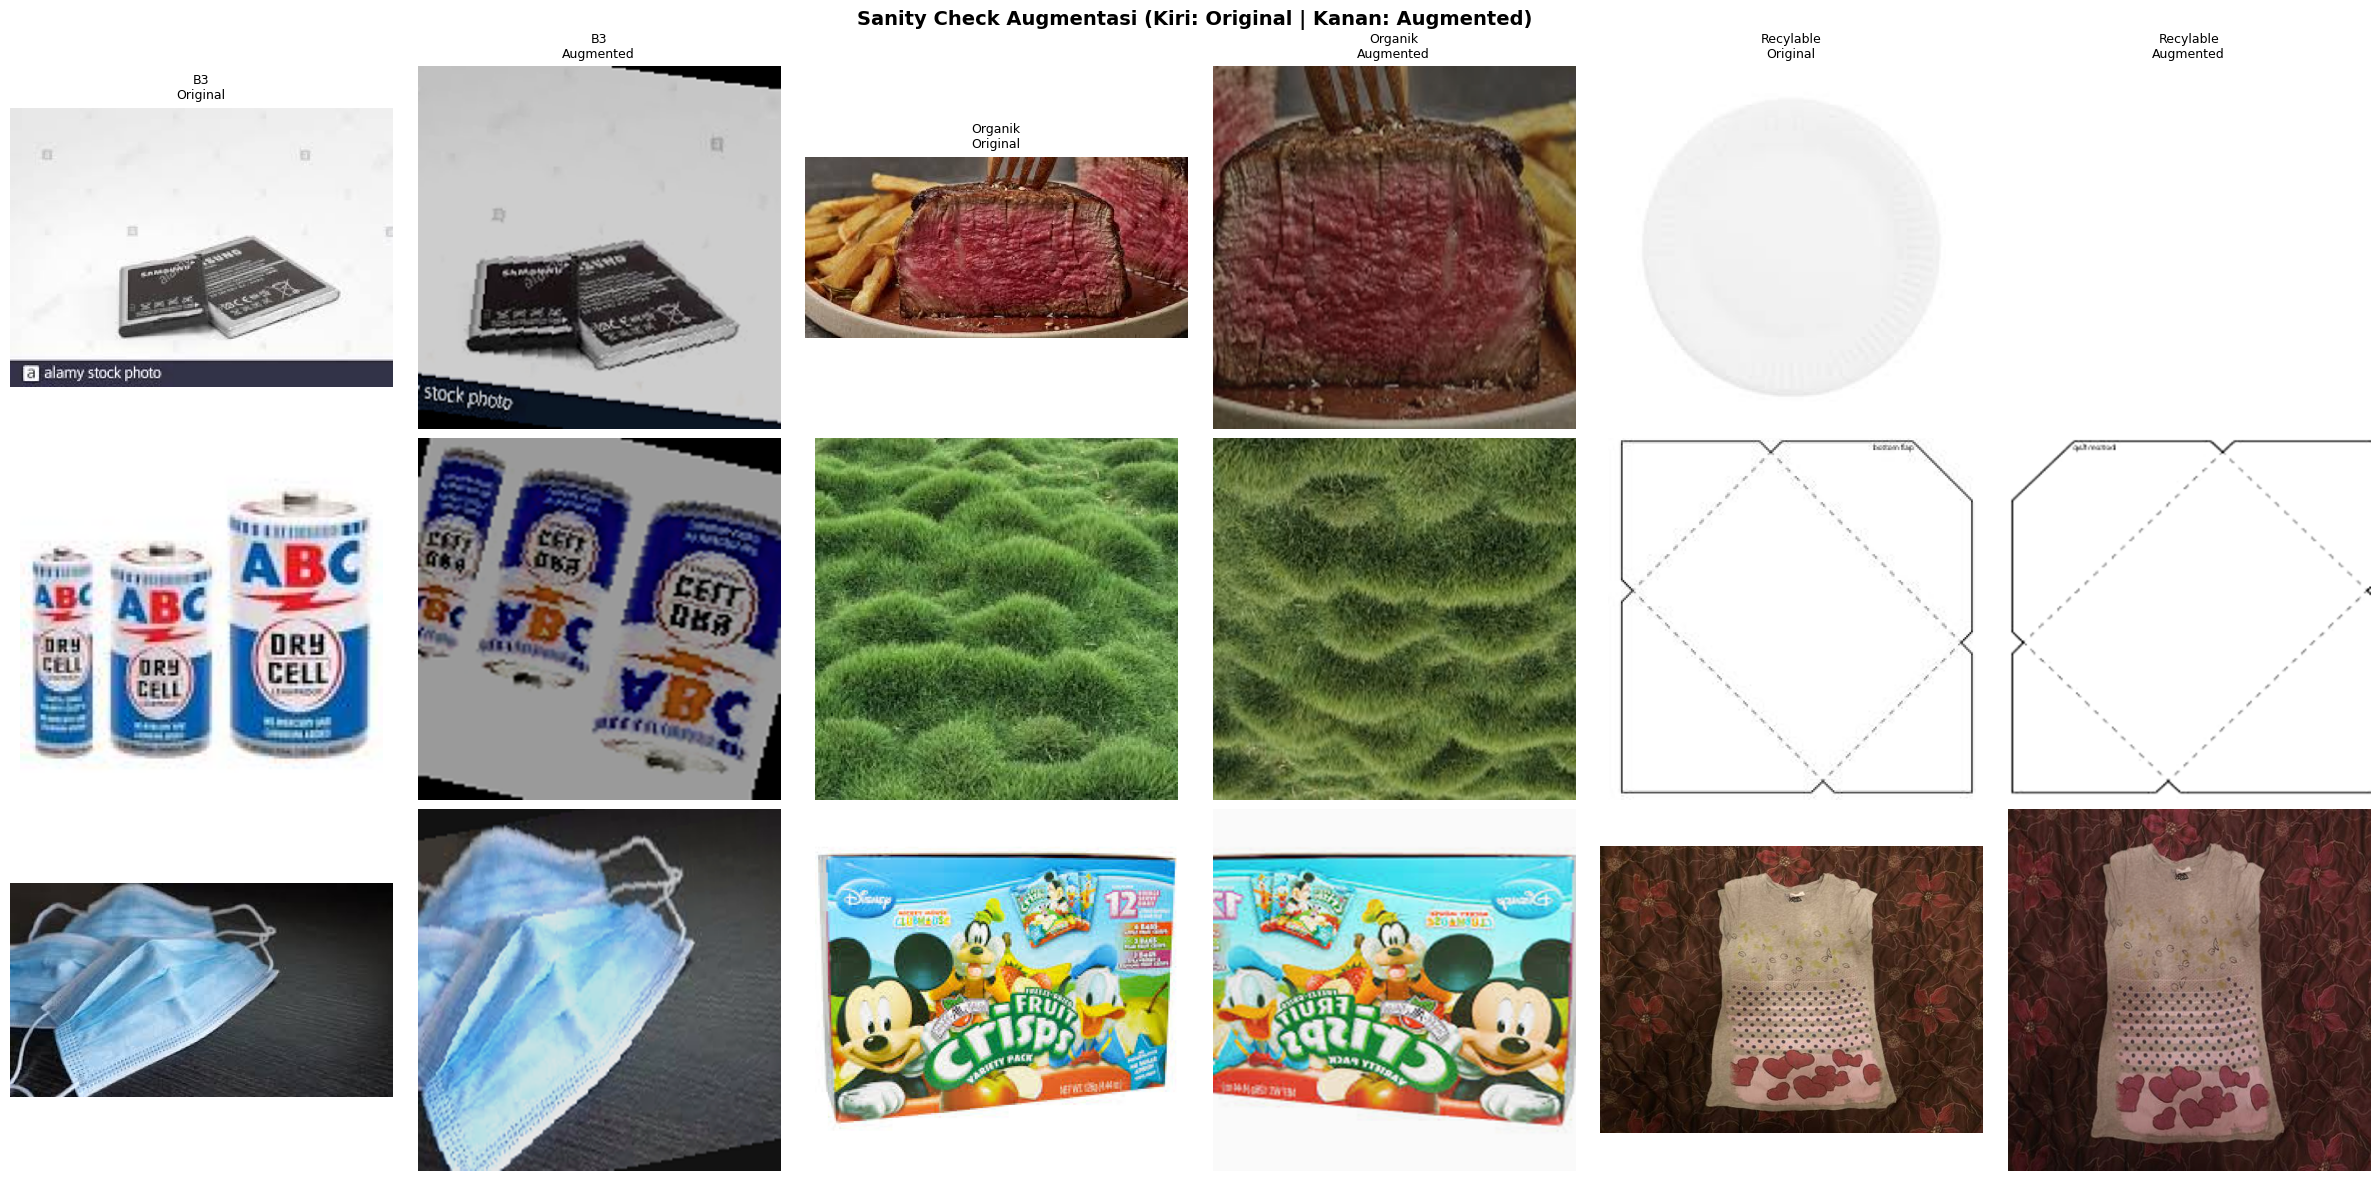

In [7]:
def visualize_augmentations(df: pd.DataFrame, n_per_class: int = 3, save_path: str = None):
    """
    Plot contoh gambar per kelas:
    - Kolom kiri : gambar ASLI (versi bersih yang akan jadi view 0)
    - Kolom kanan: gambar setelah augmentasi train (seperti view 1..N_AUG)
    """
    classes = sorted(df['label'].unique())
    n_cols  = 2 * len(classes)
    fig, axes = plt.subplots(n_per_class, n_cols,
                             figsize=(4 * n_cols, 4 * n_per_class), squeeze=False)
    fig.suptitle('Sanity Check Augmentasi (Kiri: Original | Kanan: Augmented)',
                 fontsize=14, fontweight='bold')

    for col_offset, cls in enumerate(classes):
        pool   = df[df['label'] == cls]
        subset = pool.sample(n=min(n_per_class, len(pool)), random_state=RANDOM_SEED)
        aug_transform = build_aug('train', label=cls)

        for row_idx, (_, sample) in enumerate(subset.iterrows()):
            orig = load_image(sample['abs_path'])
            aug  = aug_transform(orig)

            ax_orig = axes[row_idx][col_offset * 2]
            ax_aug  = axes[row_idx][col_offset * 2 + 1]
            ax_orig.imshow(orig)
            ax_aug.imshow(aug)
            if row_idx == 0:
                ax_orig.set_title(f'{cls}\nOriginal', fontsize=9)
                ax_aug.set_title(f'{cls}\nAugmented', fontsize=9)
            for ax in (ax_orig, ax_aug):
                ax.axis('off')

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=100, bbox_inches='tight')
        print(f'[OK] Visualisasi disimpan: {save_path}')
    plt.show()


visualize_augmentations(df_train, n_per_class=3,
                        save_path=os.path.join(HEAD_DIR, 'augmentation_sanity_check.png'))


---
# TAHAP 1 – Ekstraksi Embedding (dijalankan sekali)

Tiap gambar dibaca **sekali**, lalu dijadikan `1 + N_AUG` view:
view 0 = versi asli (hanya resize), view 1..N_AUG = versi teraugmentasi (hanya untuk split `train`;
kelas B3 memakai augmentasi yang lebih agresif). Val dan test hanya view 0.

Hasil per split disimpan di `EMBEDDING_DIR/embeddings_{split}.npz`:

| key | isi |
|---|---|
| `embeddings` | `float32 [M, 1152]` (pooler_output vision encoder) |
| `labels` | `int32 [M]` |
| `label_names` | `str [M]` |
| `paths` | `str [M]` (path absolut gambar asli) |
| `orig_idx` | `int32 [M]` (indeks baris di CSV; view dari gambar yang sama punya `orig_idx` sama → penting untuk CV agar tidak bocor) |
| `view_idx` | `int8 [M]` (0 = asli, ≥1 = augmentasi) |

Proses ini **aman terhadap disconnect**: hasil disimpan per potongan (`CHUNK_IMAGES` gambar). Kalau sesi putus,
jalankan ulang cell yang sama dan proses melanjutkan dari potongan terakhir. Split yang sudah selesai otomatis dilewati.


## CELL 8 – Definisi: Encoder, Dataset Multi-View, Fungsi Ekstraksi


In [8]:
from transformers import SiglipVisionModel, SiglipImageProcessor

# Hanya butuh mean/std dari processor; resize sudah dilakukan build_aug (selalu keluar 384x384).
_proc = SiglipImageProcessor.from_pretrained(MODEL_CHECKPOINT)
to_tensor_norm = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=_proc.image_mean, std=_proc.image_std),   # SigLIP: mean=std=0.5 -> range [-1, 1]
])
print(f'[OK] Processor: size={_proc.size} | mean={_proc.image_mean} | std={_proc.image_std}')


def load_vision_encoder() -> nn.Module:
    """SigLIP vision tower saja (tanpa text tower), dibekukan, fp16 jika USE_FP16 dan ada GPU."""
    dtype = torch.float16 if (USE_FP16 and device.type == 'cuda') else torch.float32
    m = SiglipVisionModel.from_pretrained(MODEL_CHECKPOINT)
    m = m.to(device=device, dtype=dtype).eval()
    for p in m.parameters():
        p.requires_grad = False
    print(f'[OK] Vision encoder dimuat | dtype={dtype} | device={device}')
    return m


class MultiViewDataset(Dataset):
    """
    Satu gambar dibaca sekali -> (1 + n_aug) view.
    view 0 = asli (resize saja); view 1.. = augmentasi train sesuai kelas.
    Return: (pixel_values [V, 3, H, W], label_idx, index_di_df)
    """
    def __init__(self, df: pd.DataFrame, n_aug: int, label_to_idx: dict):
        self.paths        = df['abs_path'].tolist()
        self.labels       = df['label'].tolist()
        self.n_aug        = n_aug
        self.label_to_idx = label_to_idx
        self.clean_tf     = build_aug('val')

    def __len__(self) -> int:
        return len(self.paths)

    def __getitem__(self, i: int):
        img   = load_image(self.paths[i])
        label = self.labels[i]
        views = [self.clean_tf(img)]
        current_n_aug = self.n_aug.get(label, 0) if isinstance(self.n_aug, dict) else self.n_aug
        if current_n_aug > 0:
            aug_tf = build_aug('train', label=label)
            views += [aug_tf(img) for _ in range(current_n_aug)]
        pv = torch.stack([to_tensor_norm(v) for v in views], dim=0)   # [V_i, 3, H, W]
        return pv, self.label_to_idx[label], i


def custom_collate_fn(batch):
    return batch


# ── Penyimpanan potongan (part) untuk resume ─────────────────
def save_part(parts_dir: str, start: int, emb, orig, view, n_images: int) -> None:
    tmp   = os.path.join(parts_dir, 'tmp_part.npz')       # tulis dulu ke file sementara ...
    final = os.path.join(parts_dir, f'part_{start:07d}.npz')
    np.savez(tmp, embeddings=emb, orig_idx=orig, view_idx=view, n_images=n_images)
    os.replace(tmp, final)                                 # ... lalu ganti nama (atomik) -> tidak ada part setengah jadi


def scan_parts(parts_dir: str, n_total: int) -> int:
    """Hitung berapa gambar asli yang sudah selesai dari part yang ada. Part tidak konsisten -> mulai ulang."""
    part_files = sorted(Path(parts_dir).glob('part_*.npz'))
    n_done = 0
    for pf in part_files:
        start = int(pf.stem.split('_')[1])
        try:
            with np.load(pf) as z:
                n_img = int(z['n_images'])
        except Exception:
            n_img = -1
        if start != n_done or n_img <= 0:
            print('  [WARN] Part tidak konsisten → split ini diproses ulang dari awal.')
            for p in part_files:
                p.unlink()
            return 0
        n_done += n_img
    if n_done > n_total:
        print('  [WARN] Jumlah part melebihi jumlah data (manifest berubah?) → proses ulang dari awal.')
        for p in part_files:
            p.unlink()
        return 0
    return n_done


def assemble_parts(parts_dir: str):
    E, O, V = [], [], []
    for pf in sorted(Path(parts_dir).glob('part_*.npz')):
        with np.load(pf) as z:
            E.append(z['embeddings']); O.append(z['orig_idx']); V.append(z['view_idx'])
    return np.concatenate(E), np.concatenate(O), np.concatenate(V)


def extract_split(df: pd.DataFrame, split_name: str, n_aug, vision_model: nn.Module) -> str:
    """Ekstrak embedding satu split -> EMBEDDING_DIR/embeddings_{split}.npz. Lewati jika sudah ada."""
    out_path = os.path.join(EMBEDDING_DIR, f'embeddings_{split_name}.npz')
    if os.path.exists(out_path):
        print(f'[SKIP] {split_name}: sudah ada → {out_path}')
        return out_path

    df        = df.reset_index(drop=True)
    N         = len(df)

    if isinstance(n_aug, dict):
        total_views_split = sum(1 + n_aug.get(lbl, 0) for lbl in df['label'])
    else:
        total_views_split = N * (1 + n_aug)

    parts_dir = os.path.join(EMBEDDING_DIR, f'_parts_{split_name}')
    os.makedirs(parts_dir, exist_ok=True)

    n_done = scan_parts(parts_dir, N)
    if n_done:
        print(f'[RESUME] {split_name}: {n_done}/{N} gambar sudah diproses, melanjutkan...')

    if n_done < N:
        ds     = MultiViewDataset(df.iloc[n_done:].reset_index(drop=True), n_aug, LABEL_TO_IDX)
        loader = DataLoader(
            ds, batch_size=BATCH_SIZE_EKSTRAKSI, shuffle=False,
            num_workers=NUM_WORKERS_EKSTRAKSI, pin_memory=(device.type == 'cuda'),
            prefetch_factor=(2 if NUM_WORKERS_EKSTRAKSI > 0 else None),
            collate_fn=custom_collate_fn
        )
        buf_e, buf_o, buf_v, buf_n = [], [], [], 0
        chunk_start = n_done

        def flush():
            nonlocal buf_e, buf_o, buf_v, buf_n, chunk_start
            if buf_n == 0:
                return
            save_part(parts_dir, chunk_start,
                      np.concatenate(buf_e), np.concatenate(buf_o), np.concatenate(buf_v), buf_n)
            chunk_start += buf_n
            buf_e, buf_o, buf_v, buf_n = [], [], [], 0

        for batch in tqdm(loader, desc=f'Ekstrak [{split_name}]', unit='batch'):
            all_pvs = torch.cat([item[0] for item in batch], dim=0)
            all_origs = []
            all_views = []
            for pv, _, idx in batch:
                v_i = pv.shape[0]
                all_origs.extend([idx] * v_i)
                all_views.extend(list(range(v_i)))

            chunk_size = BATCH_SIZE_EKSTRAKSI
            emb_list = []
            with torch.no_grad():
                for i in range(0, all_pvs.shape[0], chunk_size):
                    x = all_pvs[i:i+chunk_size].to(device=device, dtype=vision_model.dtype, non_blocking=True)
                    emb = vision_model(pixel_values=x).pooler_output
                    emb_list.append(emb.float().cpu())

            batch_emb = torch.cat(emb_list, dim=0).numpy()
            orig = np.array(all_origs, dtype=np.int32) + n_done

            buf_e.append(batch_emb)
            buf_o.append(orig)
            buf_v.append(np.array(all_views, dtype=np.int8))
            buf_n += len(batch)

            if buf_n >= CHUNK_IMAGES:
                flush()
        flush()

    E, O, Vw = assemble_parts(parts_dir)
    assert len(E) == total_views_split, f'Jumlah baris {len(E)} != {total_views_split} (Total views)'

    labels      = df['label'].map(LABEL_TO_IDX).to_numpy()[O]
    label_names = df['label'].to_numpy()[O]
    paths       = df['abs_path'].to_numpy()[O]
    np.savez_compressed(
        out_path,
        embeddings  = E.astype(np.float32),
        labels      = labels.astype(np.int32),
        label_names = label_names.astype(str),
        paths       = paths.astype(str),
        orig_idx    = O.astype(np.int32),
        view_idx    = Vw.astype(np.int8),
    )
    for p in Path(parts_dir).glob('*.npz'):
        p.unlink()
    Path(parts_dir).rmdir()
    print(f'[OK] embeddings_{split_name}.npz → shape={E.shape} ({N} gambar, total {total_views_split} views)')
    return out_path

print('[OK] Fungsi ekstraksi berhasil didefinisikan.')


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


preprocessor_config.json:   0%|          | 0.00/368 [00:00<?, ?B/s]

[OK] Processor: size=SizeDict(height=384, width=384, longest_edge=None, shortest_edge=None, max_height=None, max_width=None, min_pixels=None, max_pixels=None) | mean=(0.5, 0.5, 0.5) | std=(0.5, 0.5, 0.5)
[OK] Fungsi ekstraksi berhasil didefinisikan.


## CELL 9 – Jalankan Ekstraksi (train → val → test)

Ini bagian yang lama, tetapi hanya perlu dijalankan **sekali**. Kalau sesi terputus, jalankan ulang cell ini
(mount Drive + Cell 2–8 dulu); ekstraksi akan melanjutkan.


In [9]:
vision_model = load_vision_encoder()

for split_name, df_split, n_aug in [
    ('train', df_train, N_AUG),
    ('val',   df_val,   0),
    ('test',  df_test,  0),
]:
    extract_split(df_split, split_name, n_aug, vision_model)

# Catat metadata supaya jelas embedding ini dibuat dengan pengaturan apa
meta = {
    'model_checkpoint': MODEL_CHECKPOINT, 'image_size': IMAGE_SIZE, 'n_aug': N_AUG,
    'fp16': bool(USE_FP16 and device.type == 'cuda'), 'pooling': 'pooler_output',
    'label_to_idx': LABEL_TO_IDX,
    'n_images': {'train': len(df_train), 'val': len(df_val), 'test': len(df_test)},
}
with open(os.path.join(EMBEDDING_DIR, 'meta.json'), 'w') as f:
    json.dump(meta, f, indent=2)

# Backbone tidak dibutuhkan lagi -> bebaskan VRAM
del vision_model
gc.collect()
if device.type == 'cuda':
    torch.cuda.empty_cache()
print('\n[OK] Tahap 1 selesai. Embedding tersimpan di:', EMBEDDING_DIR)


config.json:   0%|          | 0.00/576 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.51GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/448 [00:00<?, ?it/s]

[transformers] SiglipVisionModel LOAD REPORT from: google/siglip-so400m-patch14-384
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...26}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.self_attn.k_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.self_attn.out_proj.weight | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.self_attn.v_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.self_attn.k_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.mlp.fc2.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.layer_norm1.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.s

[OK] Vision encoder dimuat | dtype=torch.float16 | device=cuda
[SKIP] train: sudah ada → /content/drive/MyDrive/Senpro/embeddings/siglip-so400m-patch14-384_naug_2_2_5_v3clean/embeddings_train.npz
[SKIP] val: sudah ada → /content/drive/MyDrive/Senpro/embeddings/siglip-so400m-patch14-384_naug_2_2_5_v3clean/embeddings_val.npz
[SKIP] test: sudah ada → /content/drive/MyDrive/Senpro/embeddings/siglip-so400m-patch14-384_naug_2_2_5_v3clean/embeddings_test.npz

[OK] Tahap 1 selesai. Embedding tersimpan di: /content/drive/MyDrive/Senpro/embeddings/siglip-so400m-patch14-384_naug_2_2_5_v3clean


---
# TAHAP 2 – Train Classifier (Head) di Atas Embedding

Bagian ini **tidak memanggil SigLIP sama sekali**. Di sesi baru cukup jalankan Cell 1–4 (mount Drive, config, GPU, import),
lalu cell-cell di bawah (Cell 5–9 tidak perlu).

| Cell | Isi |
|---|---|
| 10 | Load embedding `.npz` |
| 11–12 | Arsitektur head, loss, fungsi training/evaluasi (definisi saja) |
| 12b–12c | Diagnostik data: OOF (group `orig_idx`), label noise, near-duplicate, outlier |
| 13–15 | Train **satu** head sesuai `HEAD_TYPE` → kurva → evaluasi test |
| 16 | Bandingkan head neural (`HEADS_TO_COMPARE`) + kNN cosine |
| 17 | (lambat, opsional) SVM RBF dan LightGBM |
| 18 | Ensemble |
| 19 | Tabel perbandingan (metrik **val**, + val tanpa near-duplicate) + evaluasi test untuk pemenang |
| 20 | Error analysis di **val** (bukan test) + tetangga terdekat |

Pilih model berdasarkan metrik **val**. Test dipakai sekali di akhir untuk model yang sudah dipilih.


## CELL 10 – Load Embedding `.npz`

- `load_embeddings(split)` → dict: `embeddings`, `labels`, `label_names`, `paths`, `orig_idx`, `view_idx`
- `load_all_embeddings()` → `{'train': {...}, 'val': {...}, 'test': {...}}`
- `normalize=True` → L2-normalize (opsional, untuk cosine similarity / kNN / UMAP)


In [11]:
def _read_npz(path: str, allow_pickle: bool) -> dict:
    with np.load(path, allow_pickle=allow_pickle) as data:
        return {k: data[k] for k in data.files}


def load_embeddings(split: str, embedding_dir: str = None, normalize: bool = False) -> dict:
    """Muat embeddings_{split}.npz dari embedding_dir (default: EMBEDDING_DIR)."""
    embedding_dir = embedding_dir or EMBEDDING_DIR
    path = os.path.join(embedding_dir, f'embeddings_{split}.npz')
    if not os.path.exists(path):
        raise FileNotFoundError(f'{path} tidak ditemukan. Jalankan Tahap 1 (Cell 9) terlebih dulu.')

    try:
        out = _read_npz(path, allow_pickle=False)
    except ValueError:                        # file format lama (object array)
        out = _read_npz(path, allow_pickle=True)
        for k in ('label_names', 'paths'):
            out[k] = out[k].astype(str)

    emb = out['embeddings'].astype(np.float32)
    n   = len(emb)
    assert all(len(out[k]) == n for k in ('labels', 'label_names', 'paths')), \
        f'Panjang array tidak konsisten di {path}'

    if normalize:
        emb = emb / np.clip(np.linalg.norm(emb, axis=1, keepdims=True), 1e-12, None)
    out['embeddings'] = emb
    return out


def load_all_embeddings(splits=('train', 'val', 'test'), **kwargs) -> dict:
    return {s: load_embeddings(s, **kwargs) for s in splits}


emb_data = load_all_embeddings()

print('=== VERIFIKASI EMBEDDING ===')
for split, d in emb_data.items():
    dist = Counter(d['label_names'].tolist())
    n_img = len(np.unique(d['orig_idx'])) if 'orig_idx' in d else '?'
    print(f'\n  [{split}] embeddings={d["embeddings"].shape} dtype={d["embeddings"].dtype}'
          f' | gambar asli={n_img}')
    print(f'    distribusi baris : {dict(sorted(dist.items()))}')
    if 'view_idx' in d:
        print(f'    view             : {dict(sorted(Counter(d["view_idx"].tolist()).items()))}')


=== VERIFIKASI EMBEDDING ===

  [train] embeddings=(67503, 1152) dtype=float32 | gambar asli=20275
    distribusi baris : {'B3': 13356, 'Organik': 28350, 'Recylable': 25797}
    view             : {0: 20275, 1: 20275, 2: 20275, 3: 2226, 4: 2226, 5: 2226}

  [val] embeddings=(4345, 1152) dtype=float32 | gambar asli=4345
    distribusi baris : {'B3': 477, 'Organik': 2025, 'Recylable': 1843}
    view             : {0: 4345}

  [test] embeddings=(4345, 1152) dtype=float32 | gambar asli=4345
    distribusi baris : {'B3': 477, 'Organik': 2025, 'Recylable': 1843}
    view             : {0: 4345}


---
## CELL 11 – Class Weights & Arsitektur Head

`HEAD_TYPE` / `HEADS_TO_COMPARE` menerima:

| nama | bentuk |
|---|---|
| `linear` | 1152 → 3 (linear probe, baseline) |
| `mlp` | 1152 → 576 → 3, aktivasi + Dropout |
| `mlp_norm` | 1152 → 576 → **RMSNorm** → aktivasi → Dropout → 3 |
| `mlp2` | 1152 → 512 → 128 → 3 (2 tahap / bottleneck, tiap tahap: RMSNorm + aktivasi + Dropout) |
| `resmlp` | proyeksi 256 + 2 blok residual pre-norm (RMSNorm → Linear → aktivasi → Dropout → Linear) → 3 |

Aktivasi diatur `HEAD_ACT` (`gelu` atau `silu`).


In [12]:
import time

# ── Class weights (dari preprocessing) ────────────────────────
with open(CW_JSON) as f:
    class_weights_dict = json.load(f)

cw_tensor = torch.tensor(
    [class_weights_dict[lbl] for lbl in sorted(LABEL_TO_IDX, key=LABEL_TO_IDX.get)],
    dtype=torch.float32,
).to(device)
print('=== CLASS WEIGHTS ===')
for lbl, w in class_weights_dict.items():
    print(f'  {lbl}: {w:.4f}')
print(f'  Tensor (Recylable, Organik, B3): {cw_tensor.tolist()}\n')


# ── Blok arsitektur ────────────────────────────────────────────
class RMSNorm(nn.Module):
    def __init__(self, dim: int, eps: float = 1e-6):
        super().__init__()
        self.eps    = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight


def make_act(name: str) -> nn.Module:
    return nn.SiLU() if name == 'silu' else nn.GELU()


class ResBlock(nn.Module):
    """Pre-norm residual: x + Linear(Dropout(act(Linear(RMSNorm(x)))))"""
    def __init__(self, width: int, dropout: float, act: str):
        super().__init__()
        self.norm = RMSNorm(width)
        self.fc1  = nn.Linear(width, 2 * width)
        self.act  = make_act(act)
        self.drop = nn.Dropout(dropout)
        self.fc2  = nn.Linear(2 * width, width)

    def forward(self, x):
        return x + self.fc2(self.drop(self.act(self.fc1(self.norm(x)))))


class ResMLPHead(nn.Module):
    def __init__(self, in_dim, num_classes, dropout=0.3, act='gelu', width=256, n_blocks=2):
        super().__init__()
        self.proj   = nn.Linear(in_dim, width)
        self.blocks = nn.Sequential(*[ResBlock(width, dropout, act) for _ in range(n_blocks)])
        self.norm   = RMSNorm(width)
        self.out    = nn.Linear(width, num_classes)

    def forward(self, x):
        return self.out(self.norm(self.blocks(self.proj(x))))


HEAD_TYPES = ('linear', 'mlp', 'mlp_norm', 'mlp2', 'resmlp')


def build_head(head_type: str, in_dim: int, num_classes: int,
               dropout: float = 0.3, act: str = 'gelu') -> nn.Module:
    if head_type == 'linear':
        m = nn.Linear(in_dim, num_classes)
    elif head_type == 'mlp':
        h = in_dim // 2
        m = nn.Sequential(nn.Linear(in_dim, h), make_act(act), nn.Dropout(dropout),
                          nn.Linear(h, num_classes))
    elif head_type == 'mlp_norm':
        h = in_dim // 2
        m = nn.Sequential(nn.Linear(in_dim, h), RMSNorm(h), make_act(act), nn.Dropout(dropout),
                          nn.Linear(h, num_classes))
    elif head_type == 'mlp2':
        m = nn.Sequential(nn.Linear(in_dim, 512), RMSNorm(512), make_act(act), nn.Dropout(dropout),
                          nn.Linear(512, 128),    RMSNorm(128), make_act(act), nn.Dropout(dropout),
                          nn.Linear(128, num_classes))
    elif head_type == 'resmlp':
        m = ResMLPHead(in_dim, num_classes, dropout, act)
    else:
        raise ValueError(f'head_type tidak dikenal: {head_type!r}. Pilih salah satu dari {HEAD_TYPES}')

    for mod in m.modules():
        if isinstance(mod, nn.Linear):
            nn.init.xavier_uniform_(mod.weight)
            nn.init.zeros_(mod.bias)
    return m


class FocalLoss(nn.Module):
    """FL(pt) = -alpha_t * (1 - pt)^gamma * log(pt). Alternatif CrossEntropy.
    v2: pt dihitung dari CE TANPA bobot (versi lama exp(-w*ce) bukan probabilitas kelas benar
    untuk kelas berbobot != 1, sehingga modulasi B3 salah)."""
    def __init__(self, weight: torch.Tensor = None, gamma: float = 2.0, label_smoothing: float = 0.0):
        super().__init__()
        self.gamma, self.weight, self.ls = gamma, weight, label_smoothing

    def forward(self, logits, targets):
        ce = F.cross_entropy(logits, targets, weight=self.weight, reduction='none',
                             label_smoothing=self.ls)
        pt = torch.exp(-F.cross_entropy(logits, targets, reduction='none'))
        return ((1 - pt) ** self.gamma * ce).mean()


def make_criterion(weight=None) -> nn.Module:
    # weight=None -> cw_tensor dibaca saat dipanggil (perilaku 3-kelas lama, ikut
    # CLASS_WEIGHT_MODE yang diterapkan di Cell 12). Sub_Head meneruskan ctx['class_weight'].
    w = cw_tensor if weight is None else weight
    return (FocalLoss(weight=w, gamma=FOCAL_GAMMA, label_smoothing=LABEL_SMOOTHING) if USE_FOCAL_LOSS
            else nn.CrossEntropyLoss(weight=w, label_smoothing=LABEL_SMOOTHING))


# ── Normalisasi input (statistik dihitung dari TRAIN saja) ────
def fit_input_norm(X_train: np.ndarray, mode: str) -> dict:
    if mode == 'standardize':
        return {'mode': mode,
                'mu': X_train.mean(0).astype(np.float32),
                'sd': (X_train.std(0) + 1e-6).astype(np.float32)}
    return {'mode': mode}


def apply_input_norm(X: np.ndarray, norm: dict) -> np.ndarray:
    X = X.astype(np.float32)
    if norm['mode'] == 'l2':
        X = X / np.clip(np.linalg.norm(X, axis=1, keepdims=True), 1e-12, None)
    elif norm['mode'] == 'standardize':
        X = (X - norm['mu']) / norm['sd']
    return X


print(f'[OK] Arsitektur head: {HEAD_TYPES} | aktivasi: {HEAD_ACT}')


=== CLASS WEIGHTS ===
  Organik: 0.7152
  Recylable: 0.7859
  B3: 3.0362
  Tensor (Recylable, Organik, B3): [0.7859179973602295, 0.7151849865913391, 3.0361640453338623]

[OK] Arsitektur head: ('linear', 'mlp', 'mlp_norm', 'mlp2', 'resmlp') | aktivasi: gelu


---
## CELL 12 – Data ke GPU, Fungsi Training/Evaluasi, Registry Hasil


In [13]:
set_seed(RANDOM_SEED)

# ── (Opsional) buang baris TRAIN hasil review manual ──────────
def _path_key(p) -> str:
    """Kunci pencocokan = '<folder_kelas>/<nama_file>' (tahan beda root / separator)."""
    parts = str(p).replace('\\', '/').split('/')
    return '/'.join(parts[-2:])


def apply_train_exclusion(d: dict, csv_path: str):
    """Buang semua view dari gambar yang tercantum di csv_path. Hanya untuk TRAIN.
    Bila CSV punya kolom 'keputusan', hanya baris 'buang' / 'relabel:*' yang dipakai (wajib review manual)."""
    if not csv_path:
        return d, 0
    ex = pd.read_csv(csv_path)
    col = 'path' if 'path' in ex.columns else ex.columns[0]
    if 'keputusan' in ex.columns:
        kep = ex['keputusan'].fillna('').astype(str).str.strip().str.lower()
        ex  = ex[kep.str.startswith('buang') | kep.str.startswith('relabel')]
        if ex.empty:
            print('  [WARN] Kolom keputusan kosong semua -> tidak ada yang dibuang. Isi dulu hasil review.')
    keys  = set(ex[col].map(_path_key))
    drop  = np.isin(np.array([_path_key(p) for p in d['paths']]), list(keys))
    n_img = len(np.unique(d['orig_idx'][drop])) if drop.any() else 0
    n     = len(drop)
    out   = {k: (v[~drop] if isinstance(v, np.ndarray) and v.ndim >= 1 and len(v) == n else v)
             for k, v in d.items()}
    return out, n_img


emb_data.setdefault('_train_full', emb_data['train'])        # simpan train lengkap (idempoten saat cell diulang)
emb_data['train'], n_excl = apply_train_exclusion(emb_data['_train_full'], TRAIN_EXCLUDE_CSV)
if TRAIN_EXCLUDE_CSV:
    print(f'[INFO] TRAIN_EXCLUDE_CSV: {n_excl} gambar train dibuang ({len(emb_data["_train_full"]["labels"]) - len(emb_data["train"]["labels"])} baris). Val/test tidak disentuh.')

# ── Class weight: 'effective' = N/(C*N_c) dari jumlah BARIS train (setelah oversampling N_AUG) ──
if CLASS_WEIGHT_MODE == 'effective':
    _cnt = np.bincount(emb_data['train']['labels'], minlength=NUM_CLASSES).astype(np.float64)
    cw_tensor = torch.tensor(_cnt.sum() / (NUM_CLASSES * np.clip(_cnt, 1, None)),
                             dtype=torch.float32, device=device)
print(f'[INFO] class weight ({CLASS_WEIGHT_MODE}) Recylable/Organik/B3: '
      f'{[round(w, 4) for w in cw_tensor.tolist()]}')

# ── Data: normalisasi lalu pindahkan ke GPU ────────────────────
norm = fit_input_norm(emb_data['train']['embeddings'], INPUT_NORM)

def to_dev(split):
    X = torch.from_numpy(apply_input_norm(emb_data[split]['embeddings'], norm)).to(device)
    y = torch.from_numpy(emb_data[split]['labels'].astype(np.int64)).to(device)
    return X, y

X_tr, y_tr = to_dev('train')
X_va, y_va = to_dev('val')
X_te, y_te = to_dev('test')
D = X_tr.shape[1]
print(f'[INFO] Train {tuple(X_tr.shape)} | Val {tuple(X_va.shape)} | Test {tuple(X_te.shape)} | input_norm={INPUT_NORM}')

# Catat konfigurasi run -> hasil bisa direproduksi & dibandingkan antar RUN_NAME
with open(os.path.join(HEAD_DIR, f'run_config_{RUN_NAME}.json'), 'w') as f:
    json.dump({
        'run_name': RUN_NAME, 'embedding_dir': EMBEDDING_DIR, 'input_norm': INPUT_NORM,
        'class_weight_mode': CLASS_WEIGHT_MODE, 'class_weights': cw_tensor.tolist(),
        'loss': 'focal' if USE_FOCAL_LOSS else 'ce', 'focal_gamma': FOCAL_GAMMA,
        'label_smoothing': LABEL_SMOOTHING, 'mixup_alpha': MIXUP_ALPHA,
        'lr': HEAD_LR, 'weight_decay': HEAD_WEIGHT_DECAY, 'dropout': DROPOUT_RATE,
        'batch_size': HEAD_BATCH_SIZE, 'epochs': HEAD_EPOCHS, 'patience': EARLY_STOP_PATIENCE,
        'train_exclude_csv': TRAIN_EXCLUDE_CSV, 'n_train_rows': int(len(X_tr)), 'seed': RANDOM_SEED,
    }, f, indent=2)


# ── Penjaga aturan "test disentuh sekali" ──────────────────────
_TEST_REPORTED = globals().get('_TEST_REPORTED', [])

def mark_test_use(name: str, tracker=None) -> None:
    # tracker=None -> _TEST_REPORTED 3-kelas (perilaku lama). Sub_Head memakai
    # _SUB_TEST_REPORTED agar test yang sudah dipakai model 3-kelas tidak memicu
    # peringatan palsu (Req 14.6 hanya peduli model sub-label lain).
    track = _TEST_REPORTED if tracker is None else tracker
    if track and name not in track:
        print(f'[PERINGATAN METODOLOGI] Test sudah dipakai untuk {track}. Melihat test untuk '
              f'model lain lalu memilih yang terbaik = seleksi model via test (hasil tidak sahih).')
    if name not in track:
        track.append(name)


# ── Path history / checkpoint per run ──────────────────────────
def head_paths(run_name: str, head_dir=None):
    hd = HEAD_DIR if head_dir is None else head_dir   # None -> HEAD_DIR 3-kelas (lama)
    return (os.path.join(hd, f'history_{run_name}.json'),
            os.path.join(hd, f'best_head_{run_name}.pt'))

def save_history(history: dict, path: str) -> None:
    with open(path, 'w') as f:
        json.dump(history, f, indent=2)

def load_history(path: str) -> dict:
    with open(path) as f:
        return json.load(f)

def save_head(model, path: str, head_type: str, ctx=None) -> None:
    # ctx=None -> metadata 3-kelas dari global (D, NUM_CLASSES, LABEL_TO_IDX, norm).
    # Sub_Head memberi ctx dengan in_dim/num_classes/label_to_idx/norm Kategori-nya.
    in_dim       = D           if ctx is None else ctx['in_dim']
    num_classes  = NUM_CLASSES if ctx is None else ctx['num_classes']
    label_to_idx = LABEL_TO_IDX if ctx is None else ctx['label_to_idx']
    nrm          = norm        if ctx is None else ctx['norm']
    torch.save({
        'state_dict': model.state_dict(),
        'head_type': head_type, 'in_dim': in_dim, 'num_classes': num_classes,
        'dropout': DROPOUT_RATE, 'act': HEAD_ACT,
        'input_norm': {k: (torch.from_numpy(v) if isinstance(v, np.ndarray) else v) for k, v in nrm.items()},
        'label_to_idx': label_to_idx, 'model_checkpoint': MODEL_CHECKPOINT,
    }, path)

def load_head(path: str):
    """Muat head dari file .pt (arsitektur dibangun ulang dari metadata). Return (model, ckpt)."""
    ckpt = torch.load(path, map_location=device)
    m = build_head(ckpt['head_type'], ckpt['in_dim'], ckpt['num_classes'],
                   ckpt['dropout'], ckpt['act']).to(device)
    m.load_state_dict(ckpt['state_dict'])
    return m.eval(), ckpt


# ── Metrik ─────────────────────────────────────────────────────
def metrics_from_preds(y_true: np.ndarray, y_pred: np.ndarray,
                       num_classes=None, idx_to_label=None) -> dict:
    # num_classes/idx_to_label None -> global 3-kelas (NUM_CLASSES, IDX_TO_LABEL),
    # hasil identik dengan versi lama. Sub_Head/Flat_Head meneruskan C dan nama kelasnya.
    C   = NUM_CLASSES  if num_classes is None else num_classes
    i2l = IDX_TO_LABEL if idx_to_label is None else idx_to_label
    p, r, f, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=list(range(C)), zero_division=0)
    out = {'acc': float((y_true == y_pred).mean()), 'macro_f1': float(f.mean())}
    for i in range(C):
        n = i2l[i]
        out[f'precision_{n}'], out[f'recall_{n}'], out[f'f1_{n}'] = float(p[i]), float(r[i]), float(f[i])
    return out


@torch.no_grad()
def predict_proba(model, X, batch_size: int = 4096) -> np.ndarray:
    model.eval()
    return torch.cat([torch.softmax(model(X[i:i + batch_size]), -1)
                      for i in range(0, len(X), batch_size)]).cpu().numpy()


@torch.no_grad()
def evaluate_head(model, X, y, criterion, batch_size=2048, return_preds=False,
                  num_classes=None, idx_to_label=None):
    """loss + accuracy + precision/recall/F1 per kelas (dipakai untuk early stopping & history).
    num_classes/idx_to_label None -> global 3-kelas (perilaku lama)."""
    C   = NUM_CLASSES  if num_classes is None else num_classes
    i2l = IDX_TO_LABEL if idx_to_label is None else idx_to_label
    model.eval()
    total_loss, all_preds = 0.0, []
    for i in range(0, len(X), batch_size):
        xb, yb = X[i:i + batch_size], y[i:i + batch_size]
        logits = model(xb)
        total_loss += criterion(logits, yb).item() * len(xb)
        all_preds.append(logits.argmax(-1).cpu())
    preds  = torch.cat(all_preds).numpy()
    labels = y.cpu().numpy()

    m = metrics_from_preds(labels, preds, num_classes=C, idx_to_label=i2l)
    metrics = {'loss': total_loss / len(X), 'accuracy': m['acc']}
    for i in range(C):
        n = i2l[i]
        metrics[f'precision_{n}'] = round(m[f'precision_{n}'], 4)
        metrics[f'recall_{n}']    = round(m[f'recall_{n}'],    4)
        metrics[f'f1_{n}']        = round(m[f'f1_{n}'],        4)
    return (metrics, preds, labels) if return_preds else metrics


# ── Training ───────────────────────────────────────────────────
def train_one_epoch_head(model, X, y, optimizer, criterion, batch_size, mixup_alpha: float = 0.0):
    """Satu epoch. mixup_alpha > 0 -> mixup di ruang embedding (train_acc jadi perkiraan berbobot lambda)."""
    model.train()
    perm       = torch.randperm(len(X), device=X.device)
    total_loss = torch.zeros((), device=X.device)
    correct    = torch.zeros((), device=X.device)
    for i in range(0, len(X), batch_size):
        idx    = perm[i:i + batch_size]
        xb, yb = X[idx], y[idx]
        optimizer.zero_grad(set_to_none=True)
        if mixup_alpha > 0:
            lam    = float(np.random.beta(mixup_alpha, mixup_alpha))
            j      = torch.randperm(len(idx), device=X.device)
            logits = model(lam * xb + (1 - lam) * xb[j])
            loss   = lam * criterion(logits, yb) + (1 - lam) * criterion(logits, yb[j])
            pred   = logits.argmax(-1)
            correct += lam * (pred == yb).sum() + (1 - lam) * (pred == yb[j]).sum()
        else:
            logits = model(xb)
            loss   = criterion(logits, yb)
            correct += (logits.argmax(-1) == yb).sum()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.detach() * len(idx)
    return total_loss.item() / len(X), correct.item() / len(X)


def _default_ctx():
    """Konteks training 3-kelas default; dibangun SAAT dipanggil supaya mengikuti global
    terbaru (X_tr/y_tr/..., cw_tensor setelah CLASS_WEIGHT_MODE, norm, HEAD_DIR). Sub_Head
    membangun ctx-nya sendiri per Kategori (in_dim/num_classes/idx_to_label/.../head_dir)."""
    return dict(X_tr=X_tr, y_tr=y_tr, X_va=X_va, y_va=y_va, in_dim=D,
                num_classes=NUM_CLASSES, idx_to_label=IDX_TO_LABEL, label_to_idx=LABEL_TO_IDX,
                class_weight=cw_tensor, head_dir=HEAD_DIR, norm=norm)


def train_head(head_type: str, run_name: str, seed: int = None, verbose: bool = True, ctx=None) -> dict:
    """
    Train satu head dengan early stopping (val loss) + history JSON + simpan best head.
    Return dict: model (bobot terbaik), history, best_epoch, best_val_loss, params, seconds.

    ctx=None -> _default_ctx() 3-kelas: perilaku, history, dan baris log identik versi lama.
    history untuk ctx default adalah SUPERSET key lama (menambah precision/f1 Recylable &
    Organik) sehingga Cell 14 (plot) tetap bekerja.
    """
    is_default = ctx is None
    ctx = _default_ctx() if ctx is None else ctx
    X_tr_, y_tr_ = ctx['X_tr'], ctx['y_tr']
    X_va_, y_va_ = ctx['X_va'], ctx['y_va']
    in_dim, C    = ctx['in_dim'], ctx['num_classes']
    i2l          = ctx['idx_to_label']
    names        = [i2l[i] for i in range(C)]

    seed = RANDOM_SEED if seed is None else seed
    set_seed(seed)
    t0 = time.time()

    model     = build_head(head_type, in_dim, C, DROPOUT_RATE, HEAD_ACT).to(device)
    criterion = make_criterion(weight=ctx['class_weight'])
    optimizer = torch.optim.AdamW(model.parameters(), lr=HEAD_LR, weight_decay=HEAD_WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=HEAD_EPOCHS, eta_min=1e-6)
    n_params  = sum(p.numel() for p in model.parameters())
    hist_path, best_path = head_paths(run_name, ctx['head_dir'])

    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [],
               **{f'val_{m}_{n}': [] for n in names for m in ('recall', 'precision', 'f1')}}
    best_val_loss, best_epoch, no_improve = float('inf'), -1, 0

    if verbose:
        print(f'Head: {head_type} | act={HEAD_ACT} | params={n_params:,} | max {HEAD_EPOCHS} epoch | '
              f'batch={HEAD_BATCH_SIZE} | patience={EARLY_STOP_PATIENCE} | '
              f'loss={"focal" if USE_FOCAL_LOSS else "ce"} ls={LABEL_SMOOTHING} mixup={MIXUP_ALPHA}')
        print('=' * 78)

    for epoch in range(HEAD_EPOCHS):
        tr_loss, tr_acc = train_one_epoch_head(model, X_tr_, y_tr_, optimizer, criterion, HEAD_BATCH_SIZE, MIXUP_ALPHA)
        vm = evaluate_head(model, X_va_, y_va_, criterion, num_classes=C, idx_to_label=i2l)
        scheduler.step()

        history['train_loss'].append(round(tr_loss, 6));  history['train_acc'].append(round(tr_acc, 6))
        history['val_loss'].append(round(vm['loss'], 6)); history['val_acc'].append(round(vm['accuracy'], 6))
        for n in names:
            history[f'val_recall_{n}'].append(vm[f'recall_{n}'])
            history[f'val_precision_{n}'].append(vm[f'precision_{n}'])
            history[f'val_f1_{n}'].append(vm[f'f1_{n}'])

        improved = vm['loss'] < best_val_loss
        if verbose:
            if is_default:
                print(f'Ep {epoch+1:02d}/{HEAD_EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc*100:5.2f}% | '
                      f'val loss {vm["loss"]:.4f} acc {vm["accuracy"]*100:5.2f}% | '
                      f'recall R/O/B3 {vm["recall_Recylable"]:.3f}/{vm["recall_Organik"]:.3f}/{vm["recall_B3"]:.3f}'
                      f'{"  ★" if improved else ""}')
            else:
                rec = '/'.join(f'{vm["recall_"+n]:.3f}' for n in names)
                print(f'Ep {epoch+1:02d}/{HEAD_EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc*100:5.2f}% | '
                      f'val loss {vm["loss"]:.4f} acc {vm["accuracy"]*100:5.2f}% | '
                      f'recall {rec}{"  ★" if improved else ""}')

        if improved:
            best_val_loss, best_epoch, no_improve = vm['loss'], epoch + 1, 0
            save_head(model, best_path, head_type, ctx)
            save_history(history, hist_path)
        else:
            no_improve += 1
            if no_improve >= EARLY_STOP_PATIENCE:
                if verbose:
                    print(f'\n[EARLY STOP] val_loss tidak turun selama {EARLY_STOP_PATIENCE} epoch → berhenti di epoch {epoch+1}.')
                break
        if (epoch + 1) % SAVE_EVERY_N_EPOCHS == 0:
            save_history(history, hist_path)

    save_history(history, hist_path)
    model.load_state_dict(torch.load(best_path, map_location=device)['state_dict'])   # kembali ke bobot terbaik
    model.eval()
    seconds = time.time() - t0
    if verbose:
        print(f'\n[OK] Selesai ({seconds:.0f}s). Best val_loss {best_val_loss:.4f} di epoch {best_epoch}')
        print(f'[OK] History : {hist_path}\n[OK] Best head: {best_path}')
    return {'model': model, 'history': history, 'best_epoch': best_epoch,
            'best_val_loss': best_val_loss, 'params': n_params, 'seconds': seconds}


# ── Registry hasil untuk perbandingan (metrik VAL) ─────────────
results = {}

def register_result(name, kind, val_probs=None, test_probs=None,
                    val_pred=None, test_pred=None, seconds=0.0, note='',
                    registry=None, y_val=None, num_classes=None, idx_to_label=None):
    # registry=None -> `results` 3-kelas (Sub_Head memakai SUB_REGISTRY agar terpisah,
    # Req 13.10). y_val=None -> y_va 3-kelas. num_classes/idx_to_label diteruskan ke
    # metrics_from_preds (None = 3-kelas). Perilaku default identik versi lama.
    reg = results if registry is None else registry
    yv  = (y_va.cpu().numpy() if y_val is None
           else (y_val.cpu().numpy() if hasattr(y_val, 'cpu') else np.asarray(y_val)))
    if val_probs  is not None: val_pred  = val_probs.argmax(1)
    if test_probs is not None: test_pred = test_probs.argmax(1)
    reg[name] = {
        'kind': kind, 'val_probs': val_probs, 'test_probs': test_probs,
        'val_pred': val_pred, 'test_pred': test_pred, 'seconds': seconds, 'note': note,
        'val_metrics': metrics_from_preds(yv, val_pred,
                                          num_classes=num_classes, idx_to_label=idx_to_label),
    }

def fmt_params(n: int) -> str:
    return f'{n/1e6:.2f}M' if n >= 1e6 else f'{n/1e3:.1f}K'

def register_neural(name, out, registry=None, y_val=None, num_classes=None, idx_to_label=None,
                    X_val=None, X_test=None):
    # X_val/X_test None -> X_va/X_te 3-kelas (perilaku lama). Bila X_test is None secara
    # eksplisit (Sub_Head), probabilitas test TIDAK dihitung (Req 8.7/14.6).
    m  = out['model']
    Xv = X_va if X_val is None else X_val
    note = f'{fmt_params(out["params"])} param, best ep {out["best_epoch"]}'
    if X_val is None and X_test is None:
        test_probs = predict_proba(m, X_te)   # jalur 3-kelas lama: hitung test
    else:
        test_probs = None if X_test is None else predict_proba(m, X_test)
    register_result(name, 'neural', predict_proba(m, Xv), test_probs,
                    seconds=out['seconds'], note=note,
                    registry=registry, y_val=y_val,
                    num_classes=num_classes, idx_to_label=idx_to_label)

print('[OK] Fungsi training, evaluasi, dan registry hasil siap.')


[INFO] class weight (effective) Recylable/Organik/B3: [0.8722, 0.7937, 1.6847]
[INFO] Train (67503, 1152) | Val (4345, 1152) | Test (4345, 1152) | input_norm=standardize
[OK] Fungsi training, evaluasi, dan registry hasil siap.


---
## CELL 12b – Diagnostik Data di Ruang Embedding (data cleaning)

Semua head sudah ~99%, jadi kenaikan berikutnya datang dari **data**. Cell ini hanya membaca embedding
(tanpa SigLIP) dan menulis CSV kandidat ke `DIAG_DIR`. Tidak ada gambar yang dihapus/direlabel otomatis.

1. **Near-duplicate lintas split** (train↔val, train↔test, val↔test; cosine setelah standardize+L2, statistik
   train). Dedup preprocessing hanya pixel-exact; duplikat "mirip" membuat skor val/test terlalu optimis.
   Hasil: `VAL_NODUP_MASK` (dipakai kolom `_nodup` di Cell 19). Pasangan dengan **label berbeda** = kandidat
   label noise yang kuat.
2. **Prediksi out-of-fold (OOF) di train**: `StratifiedGroupKFold` dengan group `orig_idx` (semua view
   augmentasi satu gambar selalu di fold yang sama → tidak bocor). Standardisasi dihitung per fold-train.
   Prediksi hanya untuk view 0. Hasil `oof_metrics` = estimasi generalisasi kedua selain val.
3. **Label noise (confident learning + kNN)**: gambar train yang OOF-nya yakin kelas lain
   (`p_pred ≥ rata-rata self-confidence kelas itu`). `bukti='OOF+kNN'` bila mayoritas kNN juga setuju → prioritas.
4. **Ambigu** (margin top-2 OOF kecil) dan **outlier centroid** kelas.

Alur tindak lanjut:
1. Buka `label_noise_candidates.csv`, tinjau gambarnya (Cell 12c), isi kolom `keputusan`: `buang`,
   `relabel:<Kelas>`, atau `ok`.
2. Eksperimen cepat: set `TRAIN_EXCLUDE_CSV` ke CSV itu + **ganti `RUN_NAME`**, jalankan ulang dari Cell 12.
   Bandingkan val (dan `_nodup`) sebelum/sesudah.
3. Bila membaik: terapkan permanen di `preprocessing_lokal.ipynb` (relabel / pindah ke `Dataset/duplicates_removed/`,
   termasuk near-duplicate lintas split), re-ekstrak ke `EMBEDDING_DIR` baru, update `documentation.md`.

Rerun aman: bila `label_noise_candidates.csv` sudah berisi keputusan, hasil baru ditulis ke `*_baru.csv`.


In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

LBL_NAMES = np.array([IDX_TO_LABEL[i] for i in range(NUM_CLASSES)])
full_tr   = emb_data['_train_full']                         # train lengkap (sebelum TRAIN_EXCLUDE_CSV)
E_all     = full_tr['embeddings'].astype(np.float32)
y_all     = full_tr['labels'].astype(np.int64)
g_all     = full_tr['orig_idx']
v_all     = full_tr['view_idx'] if 'view_idx' in full_tr else np.zeros(len(y_all), np.int8)
p_all     = full_tr['paths'].astype(str)
m0        = v_all == 0
i0        = np.where(m0)[0]                                  # 1 baris view 0 = 1 gambar
mu0, sd0  = E_all[m0].mean(0), E_all[m0].std(0) + 1e-6       # statistik dari TRAIN saja


def std_l2(X, mu=mu0, sd=sd0):
    Z = (X.astype(np.float32) - mu) / sd
    return Z / np.clip(np.linalg.norm(Z, axis=1, keepdims=True), 1e-12, None)


@torch.no_grad()
def top_neighbors(Q, DB, k=1, exclude_self=False, chunk=2048):
    """Q, DB: numpy L2-normalized. Return (sim [Nq,k], idx [Nq,k]). exclude_self: Q identik dgn DB."""
    db, S, I = torch.from_numpy(DB).to(device), [], []
    for i in range(0, len(Q), chunk):
        s = torch.from_numpy(Q[i:i + chunk]).to(device) @ db.T
        if exclude_self:
            r = torch.arange(len(s), device=device)
            s[r, r + i] = -2.0
        ts, ti = s.topk(min(k, db.shape[0]), dim=1)
        S.append(ts.cpu()); I.append(ti.cpu())
    del db
    return torch.cat(S).numpy(), torch.cat(I).numpy()


def safe_write_csv(df: pd.DataFrame, name: str) -> str:
    """Jangan menimpa CSV yang sudah berisi keputusan review manual."""
    path = os.path.join(DIAG_DIR, name)
    if os.path.exists(path) and 'keputusan' in df.columns:
        old = pd.read_csv(path)
        if 'keputusan' in old.columns and old['keputusan'].fillna('').astype(str).str.strip().ne('').any():
            path = path.replace('.csv', '_baru.csv')
            print(f'  [INFO] {name} sudah berisi keputusan review -> hasil baru ke {os.path.basename(path)}')
    df.to_csv(path, index=False)
    return path


Z_tr0, y_tr0, p_tr0 = std_l2(E_all[i0]), y_all[i0], p_all[i0]
Z_sp = {s: std_l2(emb_data[s]['embeddings']) for s in ('val', 'test')}
y_sp = {s: emb_data[s]['labels'].astype(np.int64) for s in ('val', 'test')}
p_sp = {s: emb_data[s]['paths'].astype(str) for s in ('val', 'test')}
Z_sp['train'], y_sp['train'], p_sp['train'] = Z_tr0, y_tr0, p_tr0

# ── 1. Near-duplicate lintas split ────────────────────────────
dup_rows, nearest = [], {}
for q, d in [('val', 'train'), ('test', 'train'), ('test', 'val')]:
    s, ix = top_neighbors(Z_sp[q], Z_sp[d], k=1)
    s, ix = s[:, 0], ix[:, 0]
    nearest[(q, d)] = s
    for j in np.where(s >= NEAR_DUP_COS)[0]:
        t = ix[j]
        dup_rows.append({'split': q, 'label': LBL_NAMES[y_sp[q][j]], 'path': p_sp[q][j],
                         'match_split': d, 'match_label': LBL_NAMES[y_sp[d][t]], 'match_path': p_sp[d][t],
                         'cosine': round(float(s[j]), 4), 'label_konflik': bool(y_sp[q][j] != y_sp[d][t])})
    qs = np.quantile(s, [0.5, 0.9, 0.99])
    print(f'[near-dup] {q:4s} vs {d:5s}: {int((s >= NEAR_DUP_COS).sum()):4d} gambar >= {NEAR_DUP_COS} '
          f'| cos terdekat p50/p90/p99 = {qs[0]:.3f}/{qs[1]:.3f}/{qs[2]:.3f}')
df_dup = pd.DataFrame(dup_rows, columns=['split', 'label', 'path', 'match_split', 'match_label',
                                         'match_path', 'cosine', 'label_konflik'])
df_dup = df_dup.sort_values(['label_konflik', 'cosine'], ascending=[False, False])
df_dup.to_csv(os.path.join(DIAG_DIR, 'cross_split_near_duplicates.csv'), index=False)
VAL_NODUP_MASK = nearest[('val', 'train')] < NEAR_DUP_COS
print(f'  label berbeda di pasangan near-dup: {int(df_dup["label_konflik"].sum())}  <- kandidat label noise kuat')
print(f'  VAL_NODUP_MASK: {int(VAL_NODUP_MASK.sum())}/{len(VAL_NODUP_MASK)} gambar val dipakai untuk kolom _nodup')

# ── 2. OOF di train (StratifiedGroupKFold, group = orig_idx) ──
def fit_fold_head(X, y, seed):
    set_seed(seed)
    cnt   = np.bincount(y.cpu().numpy(), minlength=NUM_CLASSES).astype(np.float64)
    w     = torch.tensor(cnt.sum() / (NUM_CLASSES * np.clip(cnt, 1, None)), dtype=torch.float32, device=device)
    model = build_head(OOF_HEAD, X.shape[1], NUM_CLASSES, DROPOUT_RATE, HEAD_ACT).to(device)
    crit  = nn.CrossEntropyLoss(weight=w, label_smoothing=LABEL_SMOOTHING)
    opt   = torch.optim.AdamW(model.parameters(), lr=HEAD_LR, weight_decay=HEAD_WEIGHT_DECAY)
    sch   = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=OOF_EPOCHS, eta_min=1e-6)
    for _ in range(OOF_EPOCHS):
        train_one_epoch_head(model, X, y, opt, crit, HEAD_BATCH_SIZE, MIXUP_ALPHA)
        sch.step()
    return model.eval()


oof  = np.full((len(y_all), NUM_CLASSES), np.nan, np.float32)
sgkf = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_SEED)
t0   = time.time()
for f, (tr_rows, ho_rows) in enumerate(sgkf.split(E_all, y_all, groups=g_all)):
    assert not (set(g_all[tr_rows]) & set(g_all[ho_rows])), 'Leakage: orig_idx muncul di dua fold'
    mu_f = E_all[tr_rows].mean(0); sd_f = E_all[tr_rows].std(0) + 1e-6      # statistik fold-train saja
    Xf   = torch.from_numpy((E_all[tr_rows] - mu_f) / sd_f).to(device)
    yf   = torch.from_numpy(y_all[tr_rows]).to(device)
    mdl  = fit_fold_head(Xf, yf, seed=RANDOM_SEED + f)
    ho0  = ho_rows[m0[ho_rows]]
    oof[ho0] = predict_proba(mdl, torch.from_numpy((E_all[ho0] - mu_f) / sd_f).to(device))
    del Xf, yf, mdl
    print(f'[OOF] fold {f + 1}/{CV_FOLDS}: train {len(tr_rows)} baris | prediksi {len(ho0)} gambar | {time.time() - t0:.0f}s')
if device.type == 'cuda':
    torch.cuda.empty_cache()

P = oof[i0]
assert not np.isnan(P).any(), 'Ada gambar train tanpa prediksi OOF'
pred0       = P.argmax(1)
oof_metrics = metrics_from_preds(y_tr0, pred0)
print(f'\n[OOF] macro F1 {oof_metrics["macro_f1"]:.4f} | acc {oof_metrics["acc"]:.4f} | '
      f'recall B3 {oof_metrics["recall_B3"]:.4f} | prec B3 {oof_metrics["precision_B3"]:.4f}')
cm_oof = pd.DataFrame(confusion_matrix(y_tr0, pred0, labels=list(range(NUM_CLASSES))),
                      index=LBL_NAMES, columns=LBL_NAMES)
print(cm_oof)
cm_oof.to_csv(os.path.join(DIAG_DIR, 'oof_confusion.csv'))
pd.DataFrame({'path': p_tr0, 'label': LBL_NAMES[y_tr0],
              **{f'p_{LBL_NAMES[c]}': P[:, c].round(4) for c in range(NUM_CLASSES)}}
             ).to_csv(os.path.join(DIAG_DIR, 'oof_predictions_train.csv'), index=False)

# ── 3. Label noise: confident learning + kNN leave-one-out ────
thr    = np.array([P[y_tr0 == c, c].mean() for c in range(NUM_CLASSES)])   # self-confidence per kelas
p_lab  = P[np.arange(len(P)), y_tr0]
p_pred = P.max(1)
flag   = (pred0 != y_tr0) & (p_pred >= thr[pred0])

knn_s, knn_i = top_neighbors(Z_tr0, Z_tr0, k=KNN_K, exclude_self=True)
neigh        = y_tr0[knn_i]
frac_same    = (neigh == y_tr0[:, None]).mean(1)
knn_major    = np.stack([(neigh == c).sum(1) for c in range(NUM_CLASSES)], 1).argmax(1)
dup_in_train = knn_s[:, 0] >= NEAR_DUP_COS

df_all = pd.DataFrame({
    'path': p_tr0, 'label': LBL_NAMES[y_tr0], 'pred_oof': LBL_NAMES[pred0],
    'p_label': p_lab.round(4), 'p_pred': p_pred.round(4), 'skor': (p_pred - p_lab).round(4),
    'knn_frac_sama': frac_same.round(3), 'knn_mayoritas': LBL_NAMES[knn_major],
    'nn1_cos': knn_s[:, 0].round(4), 'nn1_label': LBL_NAMES[y_tr0[knn_i[:, 0]]],
})
df_noise = df_all[flag].copy()
df_noise['bukti'] = np.where(knn_major[flag] == pred0[flag], 'OOF+kNN', 'OOF saja')
df_noise = df_noise.sort_values(['bukti', 'skor'], ascending=[True, False])
df_noise['keputusan'] = ''                                    # isi manual: buang | relabel:<Kelas> | ok
noise_csv = safe_write_csv(df_noise, 'label_noise_candidates.csv')

# ── 4. Ambigu (margin kecil, tidak termasuk kandidat noise) & outlier centroid ──
Ps     = np.sort(P, 1)
margin = Ps[:, -1] - Ps[:, -2]
df_amb = df_all.assign(margin=margin.round(4))[~flag].sort_values('margin').head(200)
df_amb.to_csv(os.path.join(DIAG_DIR, 'ambiguous_samples.csv'), index=False)

out_rows = []
for c in range(NUM_CLASSES):
    idx_c = np.where(y_tr0 == c)[0]
    cen   = Z_tr0[idx_c].mean(0); cen /= np.linalg.norm(cen) + 1e-12
    cs    = Z_tr0[idx_c] @ cen
    for j in idx_c[np.argsort(cs)[:max(5, len(idx_c) // 100)]]:          # 1% terjauh per kelas
        out_rows.append({'path': p_tr0[j], 'label': LBL_NAMES[c], 'cos_ke_centroid': round(float(Z_tr0[j] @ cen), 4),
                         'pred_oof': LBL_NAMES[pred0[j]], 'p_label': round(float(p_lab[j]), 4)})
df_out = pd.DataFrame(out_rows).sort_values('cos_ke_centroid')
df_out.to_csv(os.path.join(DIAG_DIR, 'centroid_outliers.csv'), index=False)

# ── Ringkasan ─────────────────────────────────────────────────
print('\n================ RINGKASAN DIAGNOSTIK DATA ================')
print(f'Kandidat label noise train : {len(df_noise)} '
      f'(OOF+kNN: {int((df_noise["bukti"] == "OOF+kNN").sum())}) -> {os.path.basename(noise_csv)}')
print(df_noise.groupby(['label', 'pred_oof']).size().rename('jumlah').to_string())
print(f'  label asli B3 di kandidat: {int((df_noise["label"] == "B3").sum())}  <- prioritas review (Recall B3)')
print(f'Near-duplicate di dalam train (nn1 >= {NEAR_DUP_COS}): {int(dup_in_train.sum())} gambar '
      f'(label beda: {int((dup_in_train & (y_tr0[knn_i[:, 0]] != y_tr0)).sum())})')
print(f'Near-duplicate lintas split : {len(df_dup)} -> cross_split_near_duplicates.csv')
print(f'Sampel ambigu               : {len(df_amb)} -> ambiguous_samples.csv')
print(f'Outlier centroid            : {len(df_out)} -> centroid_outliers.csv')
print(f'\nSemua CSV di: {DIAG_DIR}')
print('Tindak lanjut: review Cell 12c -> isi kolom keputusan -> TRAIN_EXCLUDE_CSV + RUN_NAME baru -> bandingkan val.')


## CELL 12c – Tinjau Visual Kandidat Label Noise

Tiap baris: gambar kandidat (label asli → prediksi OOF) + `TOP_K` tetangga terdekat di train (view 0, label
tetangga ditampilkan). Gunakan untuk mengisi kolom `keputusan` di `label_noise_candidates.csv`.
`FILTER_LABEL='B3'` untuk memprioritaskan kelas B3.


In [ ]:
from PIL import Image

N_SHOW_NOISE = 12
TOP_K_NOISE  = 4
FILTER_LABEL = None          # mis. 'B3' untuk review kelas B3 dulu


def _show_img(ax, path, title, color):
    try:
        img = Image.open(path); img.thumbnail((384, 384)); ax.imshow(img.convert('RGB'))
    except Exception:
        ax.text(0.5, 0.5, 'N/A', ha='center', va='center', transform=ax.transAxes)
    ax.set_title(title, fontsize=7, color=color); ax.axis('off')


sub = df_noise if FILTER_LABEL is None else df_noise[df_noise['label'] == FILTER_LABEL]
sub = sub.head(N_SHOW_NOISE)
if sub.empty:
    print('Tidak ada kandidat untuk ditampilkan.')
else:
    fig, axes = plt.subplots(len(sub), 1 + TOP_K_NOISE, figsize=(3.2 * (1 + TOP_K_NOISE), 3.3 * len(sub)),
                             squeeze=False)
    for row, (pos, r) in enumerate(sub.iterrows()):          # index df = posisi di array view 0
        _show_img(axes[row, 0], r['path'],
                  f"[KANDIDAT] {r['label']} -> {r['pred_oof']}\np={r['p_pred']:.2f} | {r['bukti']}\n"
                  f"{os.path.basename(r['path'])}", 'red')
        for col in range(TOP_K_NOISE):
            j = knn_i[pos, col]
            _show_img(axes[row, col + 1], p_tr0[j],
                      f'tetangga #{col + 1}: {LBL_NAMES[y_tr0[j]]}\ncos={knn_s[pos, col]:.3f}', 'green'
                      if y_tr0[j] == y_tr0[pos] else 'darkorange')
    plt.suptitle('Kandidat label noise (OOF) + tetangga terdekat train', fontsize=11, y=1.002)
    plt.tight_layout()
    fp = os.path.join(DIAG_DIR, f'label_noise_review{"_" + FILTER_LABEL if FILTER_LABEL else ""}.png')
    plt.savefig(fp, dpi=110, bbox_inches='tight'); plt.show()
    print(f'[OK] {fp}')


---
## CELL 13 – Train **Satu** Head (sesuai `HEAD_TYPE`)

Kalau langsung mau membandingkan semua arsitektur, lewati ke Cell 16.


In [ ]:
HISTORY_PATH, BEST_PATH = head_paths(RUN_NAME)

out     = train_head(HEAD_TYPE, RUN_NAME, seed=RANDOM_SEED, verbose=True)
model   = out['model']
history = out['history']


---
## CELL 14 – Plot Kurva Training (dari History JSON)


In [ ]:
# Membaca dari file JSON di Drive -> bisa dijalankan kapan saja, walau sesi sudah terputus.
# (butuh Cell 2, 4, 11, 12 dijalankan lebih dulu; RUN_NAME menentukan file mana yang dibaca)
HISTORY_PATH, BEST_PATH = head_paths(RUN_NAME)
history = load_history(HISTORY_PATH)
x = range(1, len(history['train_loss']) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(x, history['train_loss'], label='Train Loss', marker='o', markersize=3)
axes[0].plot(x, history['val_loss'],   label='Val Loss',   marker='s', markersize=3)
axes[0].set_title('Loss'); axes[0].set_xlabel('Epoch'); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(x, [a*100 for a in history['train_acc']], label='Train Acc', marker='o', markersize=3)
axes[1].plot(x, [a*100 for a in history['val_acc']],   label='Val Acc',   marker='s', markersize=3)
axes[1].set_title('Accuracy (%)'); axes[1].set_xlabel('Epoch'); axes[1].legend(); axes[1].grid(True, alpha=0.3)

axes[2].plot(x, history['val_recall_B3'],        label='B3 Recall',       marker='^', markersize=4, color='red')
axes[2].plot(x, history['val_recall_Recylable'], label='Recylable Recall', marker='o', markersize=3, color='blue')
axes[2].plot(x, history['val_recall_Organik'],   label='Organik Recall',   marker='s', markersize=3, color='green')
axes[2].set_title('Val Recall per Kelas'); axes[2].set_xlabel('Epoch'); axes[2].set_ylim(0, 1.05)
axes[2].legend(); axes[2].grid(True, alpha=0.3)

plt.suptitle(f'Training History – {RUN_NAME}', fontsize=14, fontweight='bold')
plt.tight_layout()
curve_path = os.path.join(HEAD_DIR, f'training_curves_{RUN_NAME}.png')
plt.savefig(curve_path, dpi=120, bbox_inches='tight')
plt.show()
print(f'[OK] Kurva disimpan: {curve_path}')


---
## CELL 15 – Evaluasi Test Set untuk Head dari Cell 13

Jalankan **hanya** bila head ini sudah dipilih sebagai model final berdasarkan val. Kalau masih membandingkan head (Cell 16–19), lewati cell ini; test cukup dilihat sekali di Cell 19.


In [ ]:
# CELL 15 opsional: evaluasi test untuk SATU head (dari Cell 13). Saat membandingkan banyak head
# (Cell 16-19), BIARKAN False agar test tidak tersentuh dua kali (Run All aman). Set True hanya
# bila head tunggal ini memang model final.
RUN_SINGLE_HEAD_TEST = False
if not RUN_SINGLE_HEAD_TEST:
    print('[SKIP] CELL 15 dilewati (eval test head tunggal). Test dievaluasi SEKALI di Cell 19 '
          'untuk model final. Set RUN_SINGLE_HEAD_TEST=True hanya bila head tunggal ini final.')
else:
    mark_test_use(f'single_{HEAD_TYPE}_{RUN_NAME}')
    model, ckpt = load_head(BEST_PATH)
    print(f'[OK] Best head ({ckpt["head_type"]}) dimuat dari: {BEST_PATH}')

    criterion = make_criterion()
    test_metrics, test_preds, test_labels = evaluate_head(model, X_te, y_te, criterion, return_preds=True)
    label_names = [IDX_TO_LABEL[i] for i in range(NUM_CLASSES)]

    print('\n=== EVALUASI TEST SET ===')
    print(f'  Loss    : {test_metrics["loss"]:.4f}')
    print(f'  Accuracy: {test_metrics["accuracy"]*100:.2f}%')
    print('\n  Per kelas:')
    for lname in label_names:
        print(f'    {lname:10s} | P={test_metrics[f"precision_{lname}"]:.4f} '
              f'| R={test_metrics[f"recall_{lname}"]:.4f} '
              f'| F1={test_metrics[f"f1_{lname}"]:.4f}')

    print('\n=== CLASSIFICATION REPORT ===')
    print(classification_report(test_labels, test_preds, target_names=label_names, zero_division=0))

    print('=== CONFUSION MATRIX ===')
    print(pd.DataFrame(confusion_matrix(test_labels, test_preds, labels=list(range(NUM_CLASSES))),
                       index=label_names, columns=label_names))

---
# Perbandingan Arsitektur Head

Semua model di bawah dilatih/dinilai di embedding yang sama. Tabel perbandingan (Cell 19) memakai metrik **val**.
Probabilitas test disimpan di belakang layar, tetapi tidak dipakai untuk memilih model.

## CELL 16 – Head Neural (`HEADS_TO_COMPARE`) + kNN Cosine

Tiap head dilatih dengan early stopping yang sama. kNN cosine dijalankan di GPU: vote tetangga terdekat
berbobot softmax(similarity / `KNN_TEMP`), lalu dikali class weight supaya kelas minoritas tidak kalah suara.


In [ ]:
# ── Head neural ────────────────────────────────────────────────
for ht in HEADS_TO_COMPARE:
    print(f'[{ht:9s}] training...', end=' ', flush=True)
    out = train_head(ht, f'{RUN_NAME}__{ht}', seed=RANDOM_SEED, verbose=False)
    register_neural(ht, out)
    m = results[ht]['val_metrics']
    print(f'{out["seconds"]:4.0f}s | best ep {out["best_epoch"]:2d} | '
          f'val macroF1 {m["macro_f1"]:.4f} | recall B3 {m["recall_B3"]:.4f}')


# ── kNN cosine (GPU) ───────────────────────────────────────────
@torch.no_grad()
def knn_probs(Xq, Xdb, ydb, k, temp, class_mult=None, chunk=1024, num_classes=None):
    """Xq, Xdb sudah L2-normalized (tensor di device). Return prob numpy [Nq, C].
    num_classes=None -> perilaku 3-kelas lama (pakai global NUM_CLASSES); Sub_Head
    meneruskan C Kategori-nya."""
    C = NUM_CLASSES if num_classes is None else num_classes
    k = min(k, len(Xdb))
    parts = []
    for i in range(0, len(Xq), chunk):
        sim = Xq[i:i + chunk] @ Xdb.T                              # cosine similarity
        top_s, top_i = sim.topk(k, dim=1)
        w = torch.softmax(top_s / temp, dim=1)                     # bobot tetangga
        votes = torch.zeros(len(top_s), C, device=Xq.device)
        votes.scatter_add_(1, ydb[top_i], w)
        parts.append(votes)
    p = torch.cat(parts)
    if class_mult is not None:
        p = p * class_mult
    return (p / p.sum(1, keepdim=True)).cpu().numpy()

def _l2(split):
    x = torch.from_numpy(emb_data[split]['embeddings']).to(device)
    return x / x.norm(dim=1, keepdim=True).clamp_min(1e-12)

t0 = time.time()
Xdb = _l2('train')
register_result(
    'knn_cosine', 'knn',
    val_probs =knn_probs(_l2('val'),  Xdb, y_tr, KNN_K, KNN_TEMP, cw_tensor),
    test_probs=knn_probs(_l2('test'), Xdb, y_tr, KNN_K, KNN_TEMP, cw_tensor),
    seconds=time.time() - t0, note=f'k={KNN_K}, T={KNN_TEMP}, vote x class weight')
del Xdb
if device.type == 'cuda':
    torch.cuda.empty_cache()
m = results['knn_cosine']['val_metrics']
print(f'[knn_cosine] {results["knn_cosine"]["seconds"]:4.0f}s | val macroF1 {m["macro_f1"]:.4f} | recall B3 {m["recall_B3"]:.4f}')


---
## CELL 17 – (Lambat, Opsional) SVM RBF dan LightGBM

Berjalan di **CPU** (Colab gratis: 2 core), jadi paling lama di antara semua model. Matikan salah satunya dengan
`RUN_SVM = False` / `RUN_LGBM = False`.

- **SVM RBF** dilatih hanya pada baris *view asli* (tanpa augmentasi), karena SVM RBF melambat drastis seiring jumlah baris.
  `C` dipilih dari `SVM_C_GRID` berdasarkan macro F1 **val** (bukan test).
  Kalau masih terlalu lama, isi `SVM_MAX_ROWS` di Cell 2 (mis. 8000).
- **LightGBM** memakai semua baris, early stopping pada val, `class_weight='balanced'`. Karena val dipakai untuk early stopping, skor val LightGBM sedikit optimis.


In [ ]:
RUN_SVM  = True
RUN_LGBM = True

ytr_np, yva_np = emb_data['train']['labels'], emb_data['val']['labels']

# ── SVM RBF ────────────────────────────────────────────────────
if RUN_SVM:
    try:
        from sklearn.svm import SVC
        from sklearn.model_selection import train_test_split

        view  = emb_data['train'].get('view_idx')
        mask0 = (view == 0) if view is not None else np.ones(len(ytr_np), dtype=bool)
        Xs = apply_input_norm(emb_data['train']['embeddings'][mask0], norm)
        ys = ytr_np[mask0]
        if SVM_MAX_ROWS and len(Xs) > SVM_MAX_ROWS:
            Xs, _, ys, _ = train_test_split(Xs, ys, train_size=SVM_MAX_ROWS,
                                            stratify=ys, random_state=RANDOM_SEED)
        Xva_s = apply_input_norm(emb_data['val']['embeddings'],  norm)
        Xte_s = apply_input_norm(emb_data['test']['embeddings'], norm)
        best_svm, t_all = None, time.time()
        for C in SVM_C_GRID:                                   # seleksi C via VAL
            print(f'[svm_rbf] C={C} | training pada {len(Xs)} baris... (bisa lama)', flush=True)
            svm = SVC(kernel='rbf', C=C, gamma='scale', class_weight='balanced').fit(Xs, ys)
            pv  = svm.predict(Xva_s)
            f1  = metrics_from_preds(yva_np, pv)['macro_f1']
            print(f'          val macroF1 {f1:.4f}')
            if best_svm is None or f1 > best_svm[0]:
                best_svm = (f1, C, svm, pv)
        _, C_best, svm, pv = best_svm
        register_result(
            'svm_rbf', 'sklearn', val_pred=pv, test_pred=svm.predict(Xte_s),
            seconds=time.time() - t_all,
            note=f'C={C_best} (grid {SVM_C_GRID} via val), {len(Xs)} baris view asli')
        m = results['svm_rbf']['val_metrics']
        print(f'[svm_rbf] C terbaik={C_best} | {results["svm_rbf"]["seconds"]:.0f}s | val macroF1 {m["macro_f1"]:.4f} | recall B3 {m["recall_B3"]:.4f}')
        del Xs, ys, svm, best_svm, Xva_s, Xte_s
    except Exception as e:
        print(f'[svm_rbf] GAGAL: {type(e).__name__}: {e}')

# ── LightGBM ───────────────────────────────────────────────────
if RUN_LGBM:
    try:
        try:
            import lightgbm as lgb
        except ImportError:
            import subprocess, sys
            subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'lightgbm'], check=True)
            import lightgbm as lgb

        Xtr_raw, Xva_raw, Xte_raw = (emb_data[s]['embeddings'] for s in ('train', 'val', 'test'))
        print(f'[lightgbm] training pada {len(Xtr_raw)} baris... (bisa lama)', flush=True)
        t0  = time.time()
        clf = lgb.LGBMClassifier(
            n_estimators=LGBM_MAX_TREES, learning_rate=0.05, num_leaves=31,
            colsample_bytree=0.3, subsample=0.8, subsample_freq=1,
            class_weight='balanced', n_jobs=-1, verbose=-1, random_state=RANDOM_SEED)
        clf.fit(Xtr_raw, ytr_np, eval_set=[(Xva_raw, yva_np)],
                callbacks=[lgb.early_stopping(30, verbose=False)])
        register_result(
            'lightgbm', 'sklearn',
            val_probs=clf.predict_proba(Xva_raw), test_probs=clf.predict_proba(Xte_raw),
            seconds=time.time() - t0, note=f'{getattr(clf, "best_iteration_", None)} pohon (early stop di val -> val sedikit optimis)')
        m = results['lightgbm']['val_metrics']
        print(f'[lightgbm] {results["lightgbm"]["seconds"]:.0f}s | val macroF1 {m["macro_f1"]:.4f} | recall B3 {m["recall_B3"]:.4f}')
        del clf
    except Exception as e:
        print(f'[lightgbm] GAGAL: {type(e).__name__}: {e}')


---
## CELL 18 – Ensemble

Rata-rata **probabilitas (softmax)**, bukan logit mentah, supaya head yang skalanya berbeda tetap sebanding.

- `ens_semua_head` : rata-rata semua head neural dari Cell 16.
- `ens_seed_<head>` : head neural terbaik (macro F1 val) dilatih ulang dengan beberapa seed (`ENSEMBLE_SEEDS`), lalu dirata-rata.
- `ens_lintas_model` : rata-rata `ens_seed_<head>` + kNN cosine + one-hot prediksi SVM (bila ada). Keluarga model berbeda membuat kesalahan berbeda, jadi rata-ratanya biasanya lebih stabil di data baru.


In [ ]:
neural = [n for n in HEADS_TO_COMPARE if n in results and results[n]['kind'] == 'neural']
assert neural, 'Belum ada head neural di registry. Jalankan Cell 16 dulu.'

# (a) rata-rata semua head neural
register_result(
    'ens_semua_head', 'ensemble',
    val_probs =np.mean([results[n]['val_probs']  for n in neural], axis=0),
    test_probs=np.mean([results[n]['test_probs'] for n in neural], axis=0),
    note=f'rata-rata prob {len(neural)} head')

# (b) beberapa seed dari head neural terbaik
best_type = max(neural, key=lambda n: results[n]['val_metrics']['macro_f1'])
mem_val, mem_test, t0 = [results[best_type]['val_probs']], [results[best_type]['test_probs']], time.time()
print(f'[ens_seed] head terbaik: {best_type}')
for s in ENSEMBLE_SEEDS:
    if s == RANDOM_SEED:          # seed ini sudah dilatih di Cell 16
        continue
    print(f'  seed {s}...', end=' ', flush=True)
    out = train_head(best_type, f'{RUN_NAME}__{best_type}_s{s}', seed=s, verbose=False)
    mem_val.append(predict_proba(out['model'], X_va)); mem_test.append(predict_proba(out['model'], X_te))
    print(f'{out["seconds"]:.0f}s')

register_result(f'ens_seed_{best_type}', 'ensemble',
                val_probs=np.mean(mem_val, axis=0), test_probs=np.mean(mem_test, axis=0),
                seconds=time.time() - t0, note=f'{len(mem_val)} seed')
# (c) lintas keluarga model: MLP multi-seed + kNN + SVM (one-hot, SVC tidak punya prob tanpa CV mahal)
def _onehot(pred):
    return np.eye(NUM_CLASSES, dtype=np.float32)[pred]

fam_val, fam_test, fam_names = [results[f'ens_seed_{best_type}']['val_probs']], \
                               [results[f'ens_seed_{best_type}']['test_probs']], [f'ens_seed_{best_type}']
if 'knn_cosine' in results:
    fam_val.append(results['knn_cosine']['val_probs']); fam_test.append(results['knn_cosine']['test_probs'])
    fam_names.append('knn_cosine')
if 'svm_rbf' in results:
    fam_val.append(_onehot(results['svm_rbf']['val_pred'])); fam_test.append(_onehot(results['svm_rbf']['test_pred']))
    fam_names.append('svm_rbf')
if len(fam_names) > 1:
    register_result('ens_lintas_model', 'ensemble',
                    val_probs=np.mean(fam_val, axis=0), test_probs=np.mean(fam_test, axis=0),
                    note=' + '.join(fam_names))

for n in [x for x in ('ens_semua_head', f'ens_seed_{best_type}', 'ens_lintas_model') if x in results]:
    m = results[n]['val_metrics']
    print(f'[{n}] val macroF1 {m["macro_f1"]:.4f} | recall B3 {m["recall_B3"]:.4f}')


---
## CELL 19 – Tabel Perbandingan (Val) + Evaluasi Test untuk Pemenang

Kolom: akurasi, macro F1, recall tiap kelas, precision dan F1 B3, waktu (detik). Urut dari macro F1 val tertinggi.
Kalau recall B3 lebih penting bagi Anda daripada macro F1, pilih dari kolom `recall_B3` (cek juga `prec_B3`, supaya
recall tinggi tidak dibeli dengan banyak salah alarm).

Kolom `macro_F1_nodup` / `recall_B3_nodup` = metrik val setelah membuang gambar val yang near-duplicate dengan train (Cell 12b). Selisih besar antara `macro_F1` dan `macro_F1_nodup` = skor val digelembungkan duplikat; pilih model yang tetap kuat di kolom `_nodup` karena itu lebih mewakili data baru.

Setelah memilih, jalankan `report_test('nama_model')` sekali untuk melihat hasil di test.


In [ ]:
from IPython.display import display

def comparison_table() -> pd.DataFrame:
    nodup = globals().get('VAL_NODUP_MASK')               # dari Cell 12b (opsional)
    yv    = y_va.cpu().numpy()
    rows  = []
    for name, r in results.items():
        m = r['val_metrics']
        row = {
            'model': name, 'tipe': r['kind'],
            'acc': m['acc'], 'macro_F1': m['macro_f1'],
            'recall_Recylable': m['recall_Recylable'], 'recall_Organik': m['recall_Organik'],
            'recall_B3': m['recall_B3'], 'prec_B3': m['precision_B3'], 'F1_B3': m['f1_B3'],
        }
        if nodup is not None and len(nodup) == len(yv):
            mn = metrics_from_preds(yv[nodup], np.asarray(r['val_pred'])[nodup])
            row.update({'macro_F1_nodup': mn['macro_f1'], 'recall_B3_nodup': mn['recall_B3']})
        row.update({'detik': round(r['seconds']), 'catatan': r['note']})
        rows.append(row)
    return pd.DataFrame(rows).sort_values('macro_F1', ascending=False).reset_index(drop=True)


def report_test(name: str) -> None:
    mark_test_use(name)
    r, y = results[name], y_te.cpu().numpy()
    names = [IDX_TO_LABEL[i] for i in range(NUM_CLASSES)]
    print(f'=== TEST: {name} ===')
    print(classification_report(y, r['test_pred'], target_names=names, zero_division=0))
    print(pd.DataFrame(confusion_matrix(y, r['test_pred'], labels=list(range(NUM_CLASSES))),
                       index=names, columns=names))


df_cmp = comparison_table()
display(df_cmp.round(4))
if 'oof_metrics' in globals():
    print(f"[INFO] Estimasi generalisasi dari OOF train ({OOF_HEAD}, {CV_FOLDS}-fold group orig_idx): "
          f"macro F1 {oof_metrics['macro_f1']:.4f} | recall B3 {oof_metrics['recall_B3']:.4f} | "
          f"prec B3 {oof_metrics['precision_B3']:.4f}")
csv_path = os.path.join(HEAD_DIR, f'perbandingan_head_{RUN_NAME}.csv')
df_cmp.to_csv(csv_path, index=False)
print(f'[OK] Tabel disimpan: {csv_path}')

best_f1 = df_cmp.iloc[0]['model']
best_b3 = df_cmp.loc[df_cmp['recall_B3'].idxmax(), 'model']
print(f'\nmacro F1 val tertinggi : {best_f1}')
print(f'recall B3 val tertinggi: {best_b3}')

# ── Model FINAL yang dipilih (keputusan manusia, dari metrik VAL) ──────────────
# ens_lintas_model (MLP multi-seed + kNN + SVM): macro F1 val setara pemenang, tetapi
# precision B3 lebih tinggi (false alarm B3 lebih sedikit) dan ensembling lintas keluarga
# lebih stabil di data baru. Fallback ke pemenang macro F1 bila ensemble lintas model belum ada.
FINAL_MODEL = 'ens_lintas_model' if 'ens_lintas_model' in results else best_f1
print(f'model FINAL dipilih    : {FINAL_MODEL}'
      + ('' if FINAL_MODEL == 'ens_lintas_model' else '  (ens_lintas_model belum ada -> fallback)'))

# Grafik: macro F1 vs recall B3 (val)
fig, ax = plt.subplots(figsize=(10, 0.6 * len(df_cmp) + 1.8))
ypos, h = np.arange(len(df_cmp)), 0.38
ax.barh(ypos - h/2, df_cmp['macro_F1'],  h, label='macro F1 (val)')
ax.barh(ypos + h/2, df_cmp['recall_B3'], h, label='recall B3 (val)', color='red')
ax.set_yticks(ypos); ax.set_yticklabels(df_cmp['model']); ax.invert_yaxis()
ax.set_xlim(0, 1.05); ax.grid(axis='x', alpha=0.3); ax.legend(loc='lower right')
ax.set_title('Perbandingan head (data validasi)')
plt.tight_layout()
plt.savefig(os.path.join(HEAD_DIR, f'perbandingan_head_{RUN_NAME}.png'), dpi=120, bbox_inches='tight')
plt.show()

# Evaluasi test SEKALI untuk model FINAL terpilih (aturan: test disentuh sekali).
report_test(FINAL_MODEL)


---
## CELL 20 – Error Analysis di **Val** + Tetangga Terdekat (Train)

Versi lama menganalisis kesalahan di **test** lalu memakainya untuk membersihkan data. Itu membuat test ikut
"dilihat" saat mengambil keputusan, jadi test tidak lagi independen. Sekarang analisis memakai **val**
(dan untuk train, pakai kandidat OOF dari Cell 12b). Untuk tiap pasangan (label asli → prediksi) ditampilkan
gambar yang salah + `TOP_K` gambar train (view 0) terdekat dari kelas prediksi. Kesalahan disimpan ke
`val_errors_<model>.csv` di `HEAD_DIR`.

Catatan: perbaiki label val hanya bila jelas salah; jangan membuang sampel val yang "sulit" karena itu
menggelembungkan skor.


In [ ]:
from PIL import Image

ERR_MODEL  = globals().get('FINAL_MODEL') or globals().get('best_f1') or next(iter(results))   # default: model final (Cell 19)
ERR_PAIRS  = [('Recylable', 'Organik'), ('Organik', 'Recylable'), ('B3', 'Recylable'), ('B3', 'Organik')]
TOP_K      = 3
N_SHOW     = 10


def _l2n(X):
    return X / np.clip(np.linalg.norm(X, axis=1, keepdims=True), 1e-12, None)


def _show(ax, path, title, color):
    try:
        img = Image.open(path); img.thumbnail((384, 384)); ax.imshow(img.convert('RGB'))
    except Exception:
        ax.text(0.5, 0.5, 'N/A', ha='center', va='center', transform=ax.transAxes)
    ax.set_title(title, fontsize=7, color=color); ax.axis('off')


def error_analysis_val(model_name: str, true_lbl: str, pred_lbl: str, top_k=TOP_K, n_show=N_SHOW):
    r      = results[model_name]
    yv     = emb_data['val']['labels']
    pv     = np.asarray(r['val_pred'])
    pvpath = emb_data['val']['paths']
    miss   = np.where((yv == LABEL_TO_IDX[true_lbl]) & (pv == LABEL_TO_IDX[pred_lbl]))[0]
    print(f'[{model_name}] val {true_lbl} -> {pred_lbl}: {len(miss)} gambar')
    if len(miss) == 0:
        return

    tr     = emb_data['train']
    v0     = tr['view_idx'] == 0 if 'view_idx' in tr else np.ones(len(tr['labels']), bool)
    db_idx = np.where(v0 & (tr['labels'] == LABEL_TO_IDX[pred_lbl]))[0]
    db     = _l2n(apply_input_norm(tr['embeddings'][db_idx], norm))   # statistik norm dari train
    q      = _l2n(apply_input_norm(emb_data['val']['embeddings'][miss], norm))
    sim    = q @ db.T

    n_show = min(n_show, len(miss))
    fig, axes = plt.subplots(n_show, 1 + top_k, figsize=(3.2 * (1 + top_k), 3.2 * n_show), squeeze=False)
    for row in range(n_show):
        i = miss[row]
        _show(axes[row, 0], pvpath[i], f'[VAL] {true_lbl} -> {pred_lbl}\n{os.path.basename(pvpath[i])}', 'red')
        for col, j in enumerate(np.argsort(-sim[row])[:top_k], start=1):
            p = tr['paths'][db_idx[j]]
            _show(axes[row, col], p, f'train {pred_lbl} #{col}\nsim={sim[row, j]:.3f}\n{os.path.basename(p)}', 'green')
    plt.suptitle(f'Error analysis VAL – {model_name}: {true_lbl} -> {pred_lbl}', fontsize=11, y=1.002)
    plt.tight_layout()
    fp = os.path.join(HEAD_DIR, f'error_analysis_val_{model_name}_{true_lbl}_to_{pred_lbl}.png')
    plt.savefig(fp, dpi=110, bbox_inches='tight'); plt.show()
    print(f'  [OK] {fp}')


# Daftar semua kesalahan val untuk model terpilih
_r  = results[ERR_MODEL]
_yv = emb_data['val']['labels']; _pv = np.asarray(_r['val_pred'])
_err = np.where(_yv != _pv)[0]
df_err = pd.DataFrame({
    'path': emb_data['val']['paths'][_err],
    'label': [IDX_TO_LABEL[int(i)] for i in _yv[_err]],
    'pred':  [IDX_TO_LABEL[int(i)] for i in _pv[_err]],
})
if _r['val_probs'] is not None:
    df_err['p_pred'] = _r['val_probs'][_err, _pv[_err]].round(4)
df_err.to_csv(os.path.join(HEAD_DIR, f'val_errors_{ERR_MODEL}.csv'), index=False)
print(f'[OK] {len(df_err)} kesalahan val ({ERR_MODEL}) -> val_errors_{ERR_MODEL}.csv')
print(df_err.groupby(['label', 'pred']).size().rename('jumlah').to_string(), '\n')

for t, p in ERR_PAIRS:
    error_analysis_val(ERR_MODEL, t, p)


---
## CELL 21 – (P2) Kalibrasi Bias Per Kelas dari Val  —  **DIMATIKAN (opsional)**

> **Hasil di run `mlp_head_v2_ce_ls_mixup`: P2 TIDAK membantu.** Bias terpilih (R,O,B3)=(-0.3, 0.05, 0).
> VAL macro F1 0.9913 -> 0.9922 (+0.0009, dalam batas noise), tetapi **TEST turun** 0.9936 -> 0.9928
> (-0.0007) dan **precision B3 turun** 0.9961 -> 0.9923. P2 hanya *memindahkan* error R<->O, bukan
> menguranginya -> model sudah terkalibrasi. **Keputusan: pakai baseline `ens_lintas_model` tanpa bias.**
>
> Cell ini dinonaktifkan (guard `P2_ENABLED = False`) agar tidak terpakai ulang tanpa sengaja. Set
> `P2_ENABLED = True` hanya kalau ingin mencoba lagi pada embedding/run yang **baru** (mis. setelah
> data cleaning v3), dan tetap putuskan dari VAL — bukan dari TEST.

<details><summary>Deskripsi asli P2 (klik)</summary>

Error residual terpusat di **Recylable↔Organik** dan hampir simetris, tanda batas keputusan sedikit
bias. Cell ini **tidak melatih ulang apa pun** dan tidak memanggil SigLIP: ia hanya menambahkan vektor
bias `b = (b_Recylable, b_Organik, b_B3)` ke **log-probabilitas** model terpilih, lalu `argmax` lagi:

```
pred = argmax( log(prob) + b )
```

`b` dicari dengan grid search **murni di VAL** (macro F1 val sebagai objektif; recall/precision B3 sebagai
rambu agar B3 tidak rusak). `b = 0` selalu termasuk kandidat, jadi hasil tidak mungkin lebih buruk dari
baseline di val. Test dievaluasi **sekali** dengan bias terpilih.

Catatan metodologi: bias dipilih dari val, bukan test (tidak melanggar "test sekali"). Ini kalibrasi
keputusan, bukan seleksi model. Kalau `b* = 0`, berarti model sudah terkalibrasi dan P2 tidak membantu —
itu hasil yang sah, lanjut ke jalur data (P1).

</details>


In [ ]:
# ──────────────────────────────────────────────────────────────────────────────
# P2 DIMATIKAN. Hasil run v2: val +0.0009 tapi TEST -0.0007 (lihat markdown di atas).
# Model sudah terkalibrasi -> tetap pakai baseline ens_lintas_model TANPA bias.
# Set P2_ENABLED = True hanya untuk eksperimen di embedding/run BARU.
P2_ENABLED = False
if not P2_ENABLED:
    print('[P2] dinonaktifkan (P2_ENABLED=False). Pada run v2 P2 tidak membantu: '
          'val +0.0009 tapi test -0.0007. Pakai baseline ens_lintas_model tanpa bias.')
else:
    # Model yang dikalibrasi = FINAL_MODEL (default ens_lintas_model). Butuh val_probs & test_probs.
    P2_MODEL = globals().get('FINAL_MODEL') or df_cmp.iloc[0]['model']
    assert results[P2_MODEL].get('val_probs') is not None, \
        f'{P2_MODEL} tidak punya val_probs (perlu probabilitas, bukan hanya prediksi). Pilih model berbasis prob.'

    yv = y_va.cpu().numpy()
    yt = y_te.cpu().numpy()
    log_pv = np.log(np.clip(results[P2_MODEL]['val_probs'],  1e-9, None))
    log_pt = np.log(np.clip(results[P2_MODEL]['test_probs'], 1e-9, None))

    # Grid bias per kelas (B3 dikunci 0 secara default -> B3 sudah sangat baik, hindari merusaknya).
    # Set TUNE_B3=True kalau mau ikut menggeser ambang B3.
    TUNE_B3   = False
    GRID      = np.round(np.arange(-0.30, 0.3001, 0.05), 3)   # langkah 0.05
    grid_b3   = GRID if TUNE_B3 else np.array([0.0])

    base = metrics_from_preds(yv, log_pv.argmax(1))
    best = {'b': np.zeros(3), 'f1': base['macro_f1'], 'm': base}
    for bR in GRID:
        for bO in GRID:
            for bB in grid_b3:
                b = np.array([bR, bO, bB])
                m = metrics_from_preds(yv, (log_pv + b).argmax(1))
                # syarat: macro F1 val naik DAN recall B3 tidak turun dari baseline (rambu false-negatif B3)
                if m['macro_f1'] > best['f1'] + 1e-6 and m['recall_B3'] >= base['recall_B3'] - 1e-9:
                    best = {'b': b, 'f1': m['macro_f1'], 'm': m}

    b_star = best['b']
    print(f'[P2] model dikalibrasi : {P2_MODEL}')
    print(f'[P2] bias terpilih (R,O,B3) = {b_star.tolist()}  (dicari dari VAL)')
    print(f'[P2] VAL  macro F1 : {base["macro_f1"]:.4f} -> {best["f1"]:.4f} '
          f'(Δ {best["f1"] - base["macro_f1"]:+.4f})')
    print(f'     VAL  recall  R/O/B3 : {base["recall_Recylable"]:.4f}/{base["recall_Organik"]:.4f}/{base["recall_B3"]:.4f}'
          f'  ->  {best["m"]["recall_Recylable"]:.4f}/{best["m"]["recall_Organik"]:.4f}/{best["m"]["recall_B3"]:.4f}')
    print(f'     VAL  prec B3        : {base["precision_B3"]:.4f} -> {best["m"]["precision_B3"]:.4f}')

    if np.allclose(b_star, 0):
        print('\n[P2] b* = 0 -> model sudah terkalibrasi; P2 tidak menambah apa pun di val. '
              'Lanjut ke jalur data (P1).')
    else:
        # ── Evaluasi TEST sekali dengan bias terpilih ──
        mark_test_use(f'{P2_MODEL}_P2bias')
        names = [IDX_TO_LABEL[i] for i in range(NUM_CLASSES)]
        pred_t0 = log_pt.argmax(1)
        pred_t  = (log_pt + b_star).argmax(1)
        mt0 = metrics_from_preds(yt, pred_t0)
        mt  = metrics_from_preds(yt, pred_t)
        print('\n=== TEST (sekali) – efek kalibrasi P2 ===')
        print(f'  macro F1 : {mt0["macro_f1"]:.4f} -> {mt["macro_f1"]:.4f} (Δ {mt["macro_f1"] - mt0["macro_f1"]:+.4f})')
        print(f'  recall R/O/B3 : {mt0["recall_Recylable"]:.4f}/{mt0["recall_Organik"]:.4f}/{mt0["recall_B3"]:.4f}'
              f'  ->  {mt["recall_Recylable"]:.4f}/{mt["recall_Organik"]:.4f}/{mt["recall_B3"]:.4f}')
        print(f'  prec B3  : {mt0["precision_B3"]:.4f} -> {mt["precision_B3"]:.4f}')
        print('\n  Confusion matrix (setelah P2):')
        print(pd.DataFrame(confusion_matrix(yt, pred_t, labels=list(range(NUM_CLASSES))),
                           index=names, columns=names))

        # simpan hasil kalibrasi
        import json as _json
        with open(os.path.join(HEAD_DIR, f'p2_bias_{RUN_NAME}.json'), 'w') as f:
            _json.dump({'model': P2_MODEL, 'bias_R_O_B3': b_star.tolist(),
                        'val_macro_f1_base': base['macro_f1'], 'val_macro_f1_p2': best['f1'],
                        'test_macro_f1_base': mt0['macro_f1'], 'test_macro_f1_p2': mt['macro_f1'],
                        'tune_b3': bool(TUNE_B3)}, f, indent=2)
        print(f'\n[OK] Bias disimpan: {os.path.join(HEAD_DIR, f"p2_bias_{RUN_NAME}.json")}')


# Bagian C: Auto-Labeling Sub-Label

Bagian ini menambahkan **13 Sub_Label** di bawah 3 Kategori (`Recylable`, `Organik`,
`B3`) supaya fitur panduan daur ulang dapat menampilkan *tindakan konsumen pra-buang*
dan *rute penyaluran/pengolahan* yang spesifik. Seluruh komputasi memakai ulang loader,
fungsi training head, dan embedding `.npz` yang sudah ada; gambar tidak diproses ulang.

## Ringkasan alur (S0-S6)

| Tahap | Isi |
|---|---|
| **S0** | Konfigurasi: `TAXONOMY_SPEC`, `SL_PARAMS`, helper bersama (`sl_*`), parameterisasi fungsi 3-kelas. Menulis `taxonomy.json`. |
| **S1** | Pemetaan Manifest↔`.npz`, label awal dari nama file (Filename_Heuristic), Source_Group, Spot_Check, Gold_Set. |
| **S2** | Clustering k-means per Kategori untuk meninjau taksonomi dan memberi seed label. |
| **S3** | Zero-shot (text tower `so400m` di atas embedding `.npz`), keputusan constrained + cek kategori global, kalibrasi τ di Gold_Set. |
| **S4** | Active learning dengan verifikasi manusia + Eval_Set_Terverifikasi untuk val/test. |
| **S5** | Tulis `sublabels.csv` + kebijakan Kelas_Kecil. |
| **S6** | Sub_Head / Flat_Head hierarkis, evaluasi, seleksi via val, test disentuh sekali. |

## Prasyarat

- **Jalankan Cell 1-12 saja** (sampai definisi `train_head` dan utilitas training).
  Cell 12b-21 (diagnostik, perbandingan head 3-kelas, kalibrasi bias) **tidak** diperlukan.
  Cell 2 menyediakan `ROOT_DIR`, `OUTPUT_DIR`, `DATASET_DIR`, `EMBEDDING_DIR`,
  `DATA_VERSION`, `MODEL_CHECKPOINT`, `RANDOM_SEED`, `NEAR_DUP_COS`; Cell 4 `set_seed`;
  Cell 5 `load_manifest`; Cell 8 `load_vision_encoder`/`to_tensor_norm`;
  Cell 10 `load_embeddings`; Cell 11 `build_head`/`fit_input_norm`/`apply_input_norm`;
  Cell 12 `train_head` dan utilitas terkait.
- Di Colab: Drive ter-mount dan `EMBEDDING_DIR` versi `v3clean` tersedia.

## Lokasi output (`Output_Dir`)

Semua artefak tahap ditulis ke
`ROOT_DIR/preprocessing_output/sublabel_<TAXONOMY_VERSION>/` (lihat `SL_DIR` di S0a).
**Tidak ada** penulisan ke `Dataset/` atau `Archive/`; file di sana hanya dibaca untuk
ditampilkan. Setiap perubahan Sub_Label / prompt / pola nama file / teks tindakan-rute
menaikkan `TAXONOMY_VERSION` sehingga `Output_Dir` versi lama tetap utuh.

## Keputusan manual yang dibutuhkan di S0

- Mengisi teks **verbatim** `tindakan_konsumen_pra_buang` dan `rute_penyaluran_pengolahan`
  per Sub_Label (dan per Kategori untuk `lainnya`) menggantikan placeholder
  `<<ISI DARI USER>>`. Selama placeholder masih ada, `build_taxonomy()` **sengaja gagal
  validasi** (lihat sel SV-S0a) dan `taxonomy.json` tidak ditulis.

In [14]:
# ── S0a · Taksonomi, parameter, dan Taxonomy_Config (taxonomy.json) ───────────
# Prasyarat: Cell 1-12 sudah dijalankan (butuh ROOT_DIR, OUTPUT_DIR, DATASET_DIR,
# EMBEDDING_DIR, DATA_VERSION, MODEL_CHECKPOINT, RANDOM_SEED, NEAR_DUP_COS).
import os, json, hashlib, copy

# --- Versi & lokasi -----------------------------------------------------------
TAXONOMY_VERSION = 'v2'                       # naikkan bila Sub_Label/prompt/pola/teks berubah
SL_DIR       = os.path.join(OUTPUT_DIR, f'sublabel_{TAXONOMY_VERSION}')   # Output_Dir
ARCHIVE_DIR  = os.path.join(ROOT_DIR, 'Archive')
SUB_RUN_NAME = f'sublabel_head_{TAXONOMY_VERSION}_{DATA_VERSION}_r1'      # ganti tiap eksperimen (beda dari mlp_head_* 3-kelas)
SUB_HEAD_DIR = os.path.join(ROOT_DIR, 'head_runs', SUB_RUN_NAME)

PLACEHOLDER = '<<ISI DARI USER>>'   # teks tindakan/rute yang WAJIB diganti user (jangan dikarang)

# --- Parameter Bagian_Sublabel (design §A) -----------------------------------
TAU_DEFAULT        = 0.10
TAU_GLOBAL_DEFAULT = 0.50
SL_PARAMS = dict(
    SPOTCHECK_N=50, GOLD_MIN_PRECISION=0.95,
    K_CLUSTER={'Recylable': 40, 'Organik': 30, 'B3': 30}, SEED_TOP_N=16,
    TAU_GRID=(0.0, 0.5, 0.01), TARGET_PRECISION=0.90,
    TAU_DEFAULT=TAU_DEFAULT, TAU_GLOBAL_DEFAULT=TAU_GLOBAL_DEFAULT,
    AL_N_UNCERTAIN=20, AL_N_RANDOM=20, AL_N_FALLBACK=20, AL_MAX_ROUNDS=3,
    AL_MIN_RANDOM_PRECISION=0.90, AL_MIN_RANDOM_N=20, AL_FALLBACK_STABLE=0.05,
    PROBE_TYPE='logreg',            # 'logreg' | 'knn'
    PROBE_USE_ZS_FEATURES=False,
    EVAL_N_PER_SUBLABEL=50, MIN_TRAIN_SUBHEAD=30, MIN_EVAL_SUBLABEL=20,
    NEAR_DUP_COS=NEAR_DUP_COS,      # dari Cell 2 (0.97)
    SUB_HEADS_TO_COMPARE=['linear', 'mlp', 'mlp2'],
    SEED=RANDOM_SEED,
)

# Prioritas sumber label final (paling awal = menang) dan token flag yang sah.
SUMBER_PRIORITAS = ['manual', 'filename_gold', 'cluster', 'probe',
                    'zeroshot', 'filename_prior', 'filename_sisa']
FLAG_TOKENS = {'review', 'cek_kategori', 'kelas_kecil', 'lintas_split_sumber',
               'near_dup', 'tolak_gold', 'beda_prior'}

# --- Taksonomi final: 13 Sub_Label + 3 entri `lainnya` per Kategori ----------
# Teks tindakan/rute diisi placeholder; HARUS diganti verbatim oleh user.
# Prompt bahasa Inggris (draf v2, ditinjau ulang setelah clustering).
# filename_patterns dari tabel Filename_Heuristic (design §Data Models 2).
TAXONOMY_SPEC = {
    'taxonomy_version': TAXONOMY_VERSION,
    'model_checkpoint': MODEL_CHECKPOINT,
    'embedding_dir_name': os.path.basename(EMBEDDING_DIR.rstrip('/\\')),
    'data_version': DATA_VERSION,
    'params': {
        'SPOTCHECK_N': SL_PARAMS['SPOTCHECK_N'],
        'GOLD_MIN_PRECISION': SL_PARAMS['GOLD_MIN_PRECISION'],
        'TARGET_PRECISION': SL_PARAMS['TARGET_PRECISION'],
        'SEED_TOP_N': SL_PARAMS['SEED_TOP_N'],
        'AL_N_UNCERTAIN': SL_PARAMS['AL_N_UNCERTAIN'],
        'AL_N_RANDOM': SL_PARAMS['AL_N_RANDOM'],
        'AL_N_FALLBACK': SL_PARAMS['AL_N_FALLBACK'],
        'AL_MAX_ROUNDS': SL_PARAMS['AL_MAX_ROUNDS'],
        'EVAL_N_PER_SUBLABEL': SL_PARAMS['EVAL_N_PER_SUBLABEL'],
        'MIN_TRAIN_SUBHEAD': SL_PARAMS['MIN_TRAIN_SUBHEAD'],
        'MIN_EVAL_SUBLABEL': SL_PARAMS['MIN_EVAL_SUBLABEL'],
        'NEAR_DUP_COS': SL_PARAMS['NEAR_DUP_COS'],
        'SEED': SL_PARAMS['SEED'],
    },
    'tau_global': {'nilai': TAU_GLOBAL_DEFAULT, 'status': 'default'},
    'kategori': {
        'Recylable': {
            'idx': 0, 'k_cluster': SL_PARAMS['K_CLUSTER']['Recylable'],
            'urutan_heuristik': ['Tekstil', 'Kertas_Karton', 'Minyak_Jelantah',
                                 'Plastik_Kemasan', 'Plastik_Campuran', 'Anorganik_Lainnya'],
            'tau_constrained': {'nilai': TAU_DEFAULT, 'status': 'default', 'alasan': '',
                                'precision': None, 'coverage': None, 'cakupan_gold': None},
            'fallback': {'nama': 'lainnya', 'dari_user': False,
                         'tindakan_konsumen_pra_buang': 'Belum dapat ditentukan secara spesifik; pisahkan dan simpan sementara dengan aman untuk ditinjau manual.',
                         'rute_penyaluran_pengolahan': 'Review manual oleh petugas bank sampah / Dinas Lingkungan Hidup untuk penentuan rute yang tepat.'},
        },
        'Organik': {
            'idx': 1, 'k_cluster': SL_PARAMS['K_CLUSTER']['Organik'],
            'urutan_heuristik': ['Limbah_Biologis', 'Sisa_Makanan', 'Sampah_Kebun'],
            'tau_constrained': {'nilai': TAU_DEFAULT, 'status': 'default', 'alasan': '',
                                'precision': None, 'coverage': None, 'cakupan_gold': None},
            'fallback': {'nama': 'lainnya', 'dari_user': False,
                         'tindakan_konsumen_pra_buang': 'Belum dapat ditentukan secara spesifik; pisahkan dan simpan sementara dengan aman untuk ditinjau manual.',
                         'rute_penyaluran_pengolahan': 'Review manual oleh petugas bank sampah / Dinas Lingkungan Hidup untuk penentuan rute yang tepat.'},
        },
        'B3': {
            'idx': 2, 'k_cluster': SL_PARAMS['K_CLUSTER']['B3'],
            'urutan_heuristik': ['Baterai', 'Medis_Farmasi',
                                 'Aerosol_Elektronik', 'B3_Rumah_Tangga'],
            'tau_constrained': {'nilai': TAU_DEFAULT, 'status': 'default', 'alasan': '',
                                'precision': None, 'coverage': None, 'cakupan_gold': None},
            'fallback': {'nama': 'lainnya', 'dari_user': False,
                         'tindakan_konsumen_pra_buang': 'Belum dapat ditentukan secara spesifik; pisahkan dan simpan sementara dengan aman untuk ditinjau manual.',
                         'rute_penyaluran_pengolahan': 'Review manual oleh petugas bank sampah / Dinas Lingkungan Hidup untuk penentuan rute yang tepat.'},
        },
    },
    'sub_labels': [
        # ---- Recylable ------------------------------------------------------
        {'nama': 'Tekstil', 'kategori': 'Recylable',
         'metode_identifikasi_utama': 'Eksplisit (clothes*)', 'jumlah_sampel_user': 2556,
         'penampung_sisa': False,
         'tindakan_konsumen_pra_buang': 'Cuci dan keringkan. Pilah pakaian layak untuk donasi, pakaian/kain rusak dikumpulkan terpisah.',
         'rute_penyaluran_pengolahan': 'Bank Sampah Tekstil / Daur ulang mekanik serat kain (kain majun & peredam suara)',
         'prompts': ['a photo of old clothes', 'a photo of a pile of clothing',
                     'a photo of fabric textile'],
         'filename_patterns': [{'id': 'rec_tekstil', 'regex': '^clothes', 'flags': '', 'sumber': 'gold'}],
         'kelas_kecil_policy': 'latih'},
        {'nama': 'Kertas_Karton', 'kategori': 'Recylable',
         'metode_identifikasi_utama': 'Eksplisit (cardboard*)', 'jumlah_sampel_user': 75,
         'penampung_sisa': False,
         'tindakan_konsumen_pra_buang': 'Pastikan kering, bersihkan dari selotip/lem berlebih, lipat/pipihkan untuk menghemat ruang.',
         'rute_penyaluran_pengolahan': 'Bank Sampah / Pabrik bubur kertas (pulping) untuk dicetak ulang menjadi karton/boks',
         'prompts': ['a photo of a cardboard box', 'a photo of waste paper',
                     'a photo of old newspapers'],
         'filename_patterns': [{'id': 'rec_kertas_karton', 'regex': '^cardboard', 'flags': '', 'sumber': 'gold'}],
         'kelas_kecil_policy': 'latih'},
        {'nama': 'Minyak_Jelantah', 'kategori': 'Recylable',
         'metode_identifikasi_utama': 'Eksplisit (nama file minyak goreng)', 'jumlah_sampel_user': 14,
         'penampung_sisa': False,
         'tindakan_konsumen_pra_buang': 'Dinginkan minyak, saring ampas sisa makanan, tampung dalam botol plastik/jeriken tertutup rapat.',
         'rute_penyaluran_pengolahan': 'Bank Minyak Jelantah / Drop-point konversi biodiesel dan energi terbarukan',
         'prompts': ['a photo of used cooking oil', 'a photo of dirty frying oil in a pan'],
         'filename_patterns': [{'id': 'rec_minyak_jelantah', 'regex': '(cooking-oil|^Dau_an|-oil-)',
                                'flags': 'i', 'sumber': 'gold'}],
         'kelas_kecil_policy': 'rule_only'},
        {'nama': 'Plastik_Kemasan', 'kategori': 'Recylable',
         'metode_identifikasi_utama': 'Kaggle Recyclable standard', 'jumlah_sampel_user': 9384,
         'penampung_sisa': False,
         'tindakan_konsumen_pra_buang': 'Kosongkan cairan, bilas dengan air, lepaskan segel/tutup, dan pipihkan.',
         'rute_penyaluran_pengolahan': 'Bank Sampah / Daur ulang anorganik (peleburan plastik, kaca, atau kaleng logam)',
         'prompts': ['a photo of plastic packaging', 'a photo of a plastic bottle',
                     'a photo of a plastic bag', 'a photo of a plastic cup'],
         'filename_patterns': [{'id': 'rec_plastik_kemasan_R', 'regex': '^R_', 'flags': '', 'sumber': 'prior'}],
         'kelas_kecil_policy': 'latih'},
        {'nama': 'Plastik_Campuran', 'kategori': 'Recylable',
         'metode_identifikasi_utama': 'Dataset Image anorganik', 'jumlah_sampel_user': 222,
         'penampung_sisa': False,
         'tindakan_konsumen_pra_buang': 'Bilas bersih dari sisa isi, kosongkan cairan, dan remas/pipihkan wadah.',
         'rute_penyaluran_pengolahan': 'Bank Sampah / TPS 3R untuk pemilahan dan pencacahan biji plastik',
         'prompts': ['a photo of mixed plastic waste', 'a photo of assorted plastic items',
                     'a photo of a plastic container'],
         'filename_patterns': [{'id': 'rec_plastik_campuran', 'regex': '^(Image_|images)',
                                'flags': '', 'sumber': 'prior'}],
         'kelas_kecil_policy': 'latih'},
        {'nama': 'Anorganik_Lainnya', 'kategori': 'Recylable',
         'metode_identifikasi_utama': 'Anorganik generic', 'jumlah_sampel_user': 34,
         'penampung_sisa': True,
         'tindakan_konsumen_pra_buang': 'Bersihkan dan kelompokkan sesuai jenis material (plastik, kaca, atau logam).',
         'rute_penyaluran_pengolahan': 'Bank Sampah terdekat atau TPS 3R anorganik',
         'prompts': ['a photo of miscellaneous inorganic trash', 'a photo of a glass bottle',
                     'a photo of a metal can'],
         'filename_patterns': [],
         'kelas_kecil_policy': 'merge:Plastik_Kemasan'},
        # ---- Organik --------------------------------------------------------
        {'nama': 'Limbah_Biologis', 'kategori': 'Organik',
         'metode_identifikasi_utama': 'Eksplisit (biological*)', 'jumlah_sampel_user': 933,
         'penampung_sisa': False,
         'tindakan_konsumen_pra_buang': 'Kumpulkan secara terpisah dari sampah rumah tangga, hindari kontak langsung bila berpotensi patogen.',
         'rute_penyaluran_pengolahan': 'Kompos taman terkontrol / Lubang resapan biopori anaerobik',
         'prompts': ['a photo of biological waste', 'a photo of rotting fruit and vegetables',
                     'a photo of moldy food'],
         'filename_patterns': [{'id': 'org_limbah_biologis', 'regex': '^biological', 'flags': '', 'sumber': 'gold'}],
         'kelas_kecil_policy': 'latih'},
        {'nama': 'Sisa_Makanan', 'kategori': 'Organik',
         'metode_identifikasi_utama': 'Kaggle Organic standard', 'jumlah_sampel_user': 12550,
         'penampung_sisa': False,
         'tindakan_konsumen_pra_buang': 'Tiriskan kuah/air sisa makanan, pisahkan dari bungkus plastik/tusuk gigi.',
         'rute_penyaluran_pengolahan': 'Pengomposan aerobik / Pakan maggot BSF / Kompos rumah tangga',
         'prompts': ['a photo of leftover food', 'a photo of food scraps',
                     'a photo of fruit and vegetable peels'],
         'filename_patterns': [{'id': 'org_sisa_makanan', 'regex': '^(O_|Image_)', 'flags': '', 'sumber': 'prior'}],
         'kelas_kecil_policy': 'latih'},
        {'nama': 'Sampah_Kebun', 'kategori': 'Organik',
         'metode_identifikasi_utama': 'Organik serasah/kebun', 'jumlah_sampel_user': 17,
         'penampung_sisa': True,
         'tindakan_konsumen_pra_buang': 'Cacah kasar ranting dan kumpulkan daun kering dalam karung berventilasi.',
         'rute_penyaluran_pengolahan': 'Komposter taman aerobik atau timbun di lubang biopori',
         'prompts': ['a photo of garden waste', 'a photo of fallen leaves',
                     'a photo of dry leaves and branches'],
         'filename_patterns': [],
         'kelas_kecil_policy': 'merge:Sisa_Makanan'},
        # ---- B3 -------------------------------------------------------------
        {'nama': 'Baterai', 'kategori': 'B3',
         'metode_identifikasi_utama': 'Eksplisit (battery*/baterai*)', 'jumlah_sampel_user': 1292,
         'penampung_sisa': False,
         'tindakan_konsumen_pra_buang': 'Tutup kedua kutub baterai (+/-) dengan selotip isolasi bening untuk mencegah korsleting dan percikan api.',
         'rute_penyaluran_pengolahan': 'Dropbox E-Waste / Kotak limbah B3 kelurahan untuk pemulihan logam berat (hidrometalurgi)',
         'prompts': ['a photo of a battery', 'a photo of used batteries'],
         'filename_patterns': [{'id': 'b3_baterai', 'regex': '^(battery|baterai)', 'flags': '', 'sumber': 'gold'}],
         'kelas_kecil_policy': 'latih'},
        {'nama': 'Medis_Farmasi', 'kategori': 'B3',
         'metode_identifikasi_utama': 'Eksplisit (tabletcapsule*)', 'jumlah_sampel_user': 497,
         'penampung_sisa': False,
         'tindakan_konsumen_pra_buang': 'Keluarkan tablet/kapsul dari blister, hancurkan/larutkan sesuai panduan BPOM, rusak kemasannya.',
         'rute_penyaluran_pengolahan': 'Program Drug Take-Back apotek/puskesmas atau drop-box limbah medis berizin (insinerasi)',
         'prompts': ['a photo of medicine pills', 'a photo of tablets and capsules'],
         'filename_patterns': [{'id': 'b3_medis_farmasi', 'regex': '^tabletcapsule', 'flags': '', 'sumber': 'gold'}],
         'kelas_kecil_policy': 'latih'},
        {'nama': 'Aerosol_Elektronik', 'kategori': 'B3',
         'metode_identifikasi_utama': 'Eksplisit/Indikasi (trash*/Image*)', 'jumlah_sampel_user': 1103,
         'penampung_sisa': False,
         'tindakan_konsumen_pra_buang': 'Pastikan gas habis di tempat terbuka, jangan ditusuk atau dibakar, bungkus lampu/kabel rapi.',
         'rute_penyaluran_pengolahan': 'Dropbox limbah B3 / Fasilitas penanganan E-Waste kota',
         'prompts': ['a photo of an aerosol spray can', 'a photo of an electronic device',
                     'a photo of a phone charger and cable'],
         'filename_patterns': [{'id': 'b3_aerosol_elektronik', 'regex': '^(trash|Image_)', 'flags': '', 'sumber': 'prior'}],
         'kelas_kecil_policy': 'latih'},
        {'nama': 'B3_Rumah_Tangga', 'kategori': 'B3',
         'metode_identifikasi_utama': 'B3 spesifik / residu', 'jumlah_sampel_user': 288,
         'penampung_sisa': True,
         'tindakan_konsumen_pra_buang': 'Simpan dalam wadah asli tertutup rapat, jangan dicampur bahan kimia lain, beri label peringatan.',
         'rute_penyaluran_pengolahan': 'Drop point B3 Dinas Lingkungan Hidup / TPS B3 khusus',
         'prompts': ['a photo of household hazardous waste', 'a photo of a paint can',
                     'a photo of a chemical cleaner bottle', 'a photo of a light bulb'],
         'filename_patterns': [],
         'kelas_kecil_policy': 'latih'},
    ],
}


# --- Galat yang menghentikan eksekusi ----------------------------------------
class SublabelError(RuntimeError):
    """Galat Bagian_Sublabel yang menghentikan eksekusi dengan pesan jelas."""
    pass


# --- Validasi taksonomi (Req 1.6, 12.5) --------------------------------------
def validate_taxonomy(cfg):
    """Cek integritas Taxonomy_Config. SublabelError menyebut Sub_Label + field."""
    kats = cfg.get('kategori', {})
    if not kats:
        raise SublabelError("Taxonomy_Config: tidak ada kategori.")
    subs = cfg.get('sub_labels', [])
    if not subs:
        raise SublabelError("Taxonomy_Config: daftar sub_labels kosong.")

    seen = {}
    per_kat = {k: [] for k in kats}
    for sl in subs:
        nama = sl.get('nama', '')
        kat = sl.get('kategori', '')
        if not nama:
            raise SublabelError("Sub_Label tanpa field `nama`.")
        if nama == 'lainnya':
            raise SublabelError(f"Sub_Label `{nama}`: nama tidak boleh `lainnya` (itu Fallback_Sublabel).")
        if nama in seen:
            raise SublabelError(f"Sub_Label `{nama}`: nama duplikat (field `nama`).")
        seen[nama] = kat
        if kat not in kats:
            raise SublabelError(f"Sub_Label `{nama}`: field `kategori`=`{kat}` bukan Kategori valid "
                                f"({sorted(kats)}).")
        per_kat[kat].append(sl)
        prompts = sl.get('prompts', [])
        if not isinstance(prompts, list) or len([p for p in prompts if str(p).strip()]) < 2:
            raise SublabelError(f"Sub_Label `{nama}`: field `prompts` butuh minimal 2 prompt non-kosong.")
        for field in ('tindakan_konsumen_pra_buang', 'rute_penyaluran_pengolahan'):
            txt = sl.get(field, '')
            if not str(txt).strip():
                raise SublabelError(f"Sub_Label `{nama}`: field `{field}` kosong (isi verbatim dari user).")
            if PLACEHOLDER in str(txt):
                raise SublabelError(f"Sub_Label `{nama}`: field `{field}` masih berisi placeholder "
                                    f"`{PLACEHOLDER}` — isi teks verbatim dari user, jangan dikarang.")

    # Fallback `lainnya` per Kategori juga wajib terisi (Req 1.3)
    for kat, kinfo in kats.items():
        fb = kinfo.get('fallback', {})
        for field in ('tindakan_konsumen_pra_buang', 'rute_penyaluran_pengolahan'):
            txt = fb.get(field, '')
            if not str(txt).strip():
                raise SublabelError(f"Kategori `{kat}` fallback `lainnya`: field `{field}` kosong.")
            if PLACEHOLDER in str(txt):
                raise SublabelError(f"Kategori `{kat}` fallback `lainnya`: field `{field}` masih berisi "
                                    f"placeholder `{PLACEHOLDER}` — isi teks tingkat Kategori dari user.")

    # Kebijakan merge valid (target ada, satu Kategori) — Req 12.5
    for sl in subs:
        pol = sl.get('kelas_kecil_policy', 'latih')
        if isinstance(pol, str) and pol.startswith('merge:'):
            target = pol.split(':', 1)[1]
            if target not in seen:
                raise SublabelError(f"Sub_Label `{sl['nama']}`: target merge `{target}` tidak ada.")
            if seen[target] != sl['kategori']:
                raise SublabelError(f"Sub_Label `{sl['nama']}`: target merge `{target}` berada di Kategori "
                                    f"`{seen[target]}`, berbeda dari `{sl['kategori']}`.")
        elif pol not in ('latih', 'rule_only'):
            if not (isinstance(pol, str) and pol.startswith('merge:')):
                raise SublabelError(f"Sub_Label `{sl['nama']}`: `kelas_kecil_policy`=`{pol}` tidak dikenal.")

    # urutan_heuristik = permutasi lengkap Sub_Label Kategori; penampung sisa di akhir
    for kat, kinfo in kats.items():
        urut = kinfo.get('urutan_heuristik', [])
        nama_kat = [s['nama'] for s in per_kat[kat]]
        if sorted(urut) != sorted(nama_kat):
            raise SublabelError(f"Kategori `{kat}`: `urutan_heuristik` {urut} bukan permutasi lengkap "
                                f"Sub_Label Kategori {sorted(nama_kat)}.")
        sisa = [s['nama'] for s in per_kat[kat] if s.get('penampung_sisa')]
        if len(sisa) > 1:
            raise SublabelError(f"Kategori `{kat}`: lebih dari satu penampung sisa {sisa} "
                                f"(maksimal satu `penampung_sisa=True`).")
        if sisa and urut and urut[-1] != sisa[0]:
            raise SublabelError(f"Kategori `{kat}`: penampung sisa `{sisa[0]}` harus di akhir "
                                f"`urutan_heuristik`, bukan `{urut[-1]}`.")
    return True


# --- Hash kanonik (Req 1.8, 6.5) ---------------------------------------------
def _canonical(obj):
    """JSON kanonik: kunci terurut, pemisah rapat, non-ASCII dipertahankan."""
    return json.dumps(obj, ensure_ascii=False, sort_keys=True, separators=(',', ':'))


def taxonomy_hash(cfg):
    """SHA-256 atas bagian yang menentukan versi (nama, kategori, prompt, pola, teks, urutan)."""
    payload = {
        'taxonomy_version': cfg.get('taxonomy_version'),
        'model_checkpoint': cfg.get('model_checkpoint'),
        'embedding_dir_name': cfg.get('embedding_dir_name'),
        'kategori': {
            k: {
                'urutan_heuristik': v.get('urutan_heuristik', []),
                'fallback': {
                    'nama': v.get('fallback', {}).get('nama'),
                    'tindakan_konsumen_pra_buang': v.get('fallback', {}).get('tindakan_konsumen_pra_buang'),
                    'rute_penyaluran_pengolahan': v.get('fallback', {}).get('rute_penyaluran_pengolahan'),
                },
            } for k, v in cfg.get('kategori', {}).items()
        },
        'sub_labels': [
            {
                'nama': s.get('nama'),
                'kategori': s.get('kategori'),
                'prompts': list(s.get('prompts', [])),
                'filename_patterns': [
                    {'id': p.get('id'), 'regex': p.get('regex'),
                     'flags': p.get('flags', ''), 'sumber': p.get('sumber')}
                    for p in s.get('filename_patterns', [])
                ],
                'tindakan_konsumen_pra_buang': s.get('tindakan_konsumen_pra_buang'),
                'rute_penyaluran_pengolahan': s.get('rute_penyaluran_pengolahan'),
                'kelas_kecil_policy': s.get('kelas_kecil_policy'),
                'penampung_sisa': bool(s.get('penampung_sisa')),
            } for s in cfg.get('sub_labels', [])
        ],
    }
    return 'sha256:' + hashlib.sha256(_canonical(payload).encode('utf-8')).hexdigest()


def prompt_hash(cfg):
    """Hash khusus prompt (kunci cache prototype); tidak bergantung urutan kunci dict."""
    payload = {s['nama']: list(s.get('prompts', [])) for s in cfg.get('sub_labels', [])}
    return 'sha256:' + hashlib.sha256(_canonical(payload).encode('utf-8')).hexdigest()


# --- Baca/tulis JSON (round-trip, Req 1.5) -----------------------------------
def sl_write_taxonomy(cfg, path):
    """Tulis Taxonomy_Config ke JSON (ensure_ascii=False, urutan kunci dipertahankan)."""
    os.makedirs(os.path.dirname(path), exist_ok=True)
    tmp = path + '.tmp'
    with open(tmp, 'w', encoding='utf-8') as f:
        json.dump(cfg, f, ensure_ascii=False, indent=2, sort_keys=False)
    os.replace(tmp, path)
    return path


def sl_read_taxonomy(path):
    """Baca Taxonomy_Config dari JSON."""
    with open(path, 'r', encoding='utf-8') as f:
        return json.load(f)


# --- build_taxonomy(): validasi, hash, tulis (Req 1.1, 1.8) ------------------
def build_taxonomy(spec=None, sl_dir=None):
    """Bangun Taxonomy_Config dari TAXONOMY_SPEC: validasi, hitung content_hash,
    tulis taxonomy.json. Bila file ada dengan hash berbeda dan versi sama, berhenti
    (minta naikkan TAXONOMY_VERSION) tanpa menimpa. Bila hash sama, field τ hasil
    kalibrasi yang sudah ada dipertahankan."""
    spec = copy.deepcopy(TAXONOMY_SPEC if spec is None else spec)
    sl_dir = SL_DIR if sl_dir is None else sl_dir
    validate_taxonomy(spec)                       # gagal di sini selama placeholder masih ada

    chash = taxonomy_hash(spec)
    spec['content_hash'] = chash
    path = os.path.join(sl_dir, 'taxonomy.json')

    if os.path.exists(path):
        old = sl_read_taxonomy(path)
        old_hash = old.get('content_hash')
        same_version = old.get('taxonomy_version') == spec.get('taxonomy_version')
        if old_hash != chash and same_version:
            raise SublabelError(
                f"taxonomy.json versi `{spec.get('taxonomy_version')}` sudah ada dengan hash berbeda.\n"
                f"  lama : {old_hash}\n  baru : {chash}\n"
                f"Jangan menimpa versi lama — naikkan `TAXONOMY_VERSION` untuk perubahan ini.")
        if old_hash == chash:
            # Pertahankan field τ hasil kalibrasi yang sudah ada.
            tg = old.get('tau_global')
            if tg is not None:
                spec['tau_global'] = tg
            for kat, kinfo in spec.get('kategori', {}).items():
                old_tau = old.get('kategori', {}).get(kat, {}).get('tau_constrained')
                if old_tau is not None:
                    kinfo['tau_constrained'] = old_tau

    sl_write_taxonomy(spec, path)
    return spec, path


In [15]:
# ── SV-S0a · Verifikasi S0a ──────────────────────────────────────────────────
# Catatan: selama teks tindakan/rute masih placeholder `<<ISI DARI USER>>`,
# build_taxonomy() SENGAJA gagal validasi (Req 1.2/1.6). Itu perilaku yang
# diharapkan; JANGAN menghapus placeholder hanya agar sel ini lulus.
from collections import Counter

# Hitung jumlah Sub_Label per Kategori dari spec (tidak butuh file/GPU).
_per_kat = Counter(s['kategori'] for s in TAXONOMY_SPEC['sub_labels'])
print('Jumlah Sub_Label per Kategori:')
for _k in TAXONOMY_SPEC['kategori']:
    print(f'  {_k:12s}: {_per_kat.get(_k, 0)}')
print(f'  TOTAL       : {sum(_per_kat.values())}  (harus 13)')
assert sum(_per_kat.values()) == 13, 'TAXONOMY_SPEC harus berisi 13 Sub_Label.'

print(f'\nTAXONOMY_VERSION = {TAXONOMY_VERSION}')
print(f'SL_DIR           = {SL_DIR}')
print(f'SUB_HEAD_DIR     = {SUB_HEAD_DIR}')
print(f'prompt_hash      = {prompt_hash(TAXONOMY_SPEC)}')

# Round-trip hash stabil terhadap acak urutan prompt dalam satu Sub_Label? (sanity)
print(f'taxonomy_hash    = {taxonomy_hash(TAXONOMY_SPEC)}')

try:
    _cfg, _path = build_taxonomy()
    print(f'\n[OK] taxonomy.json ditulis ke: {_path}')
except SublabelError as e:
    print('\n[DIHARAPKAN GAGAL - placeholder belum diisi user]')
    print(f'SublabelError: {e}')


Jumlah Sub_Label per Kategori:
  Recylable   : 6
  Organik     : 3
  B3          : 4
  TOTAL       : 13  (harus 13)

TAXONOMY_VERSION = v2
SL_DIR           = /content/drive/MyDrive/Senpro/preprocessing_output/sublabel_v2
SUB_HEAD_DIR     = /content/drive/MyDrive/Senpro/head_runs/subhead_v2_v3clean_r1
prompt_hash      = sha256:cb7a73860196f49f73e980df70ecd8b42cf5d1b66b224846df22a98933d7abfb
taxonomy_hash    = sha256:a748ed66f6a7453351b2208ab7d1824be0d483e1b33058073ee7084b7a9a560a

[OK] taxonomy.json ditulis ke: /content/drive/MyDrive/Senpro/preprocessing_output/sublabel_v2/taxonomy.json


In [16]:
# ── S0b · Helper bersama Bagian_Sublabel (I/O, penjaga tulis, gerbang, audit, shim) ──
# Prasyarat: S0a sudah dijalankan (SL_DIR, SUB_HEAD_DIR, ARCHIVE_DIR, SUMBER_PRIORITAS,
# FLAG_TOKENS, SublabelError) dan Cell 1-12 (ROOT_DIR, DATASET_DIR, OUTPUT_DIR,
# EMBEDDING_DIR, device, load_embeddings, load_manifest). Semua penulisan file Bagian C
# WAJIB lewat sl_guard_write; DILARANG menulis ke Dataset/ atau Archive/ (Req 2.6).
import os, csv, time, datetime
import numpy as np
import pandas as pd

# Registry/tracker Sub_Head terpisah dari `results`/`_TEST_REPORTED` 3-kelas (Req 13.10, 14.6).
SUB_REGISTRY = {}
_SUB_TEST_REPORTED = []

# ── Penjaga penulisan (murni) ────────────────────────────────────────────────
def _sl_norm(path):
    """Absolutkan + normalisasi `..`/`.` tanpa menyentuh disk, separator OS."""
    return os.path.normpath(os.path.abspath(str(path)))

def _sl_under(path, root):
    """True bila `path` sama dengan atau berada di bawah `root` (setelah normalisasi)."""
    p, r = _sl_norm(path), _sl_norm(root)
    try:
        return os.path.commonpath([p, r]) == r
    except ValueError:                 # drive berbeda (Windows) → tidak di bawah root
        return False

def sl_guard_write(path):
    """Izinkan menulis HANYA di bawah SL_DIR atau SUB_HEAD_DIR; tolak di bawah
    DATASET_DIR/ARCHIVE_DIR atau di luar akar yang diizinkan (Req 2.6). Murni:
    kembalikan path ternormalisasi bila sah, else SublabelError. `..` dinormalisasi
    dulu agar tidak bisa keluar dari akar lewat path relatif."""
    p = _sl_norm(path)
    for terlarang, nama in ((globals().get('DATASET_DIR'), 'DATASET_DIR'),
                            (globals().get('ARCHIVE_DIR'), 'ARCHIVE_DIR')):
        if terlarang is not None and _sl_under(p, terlarang):
            raise SublabelError(f"sl_guard_write: menolak menulis di bawah {nama} "
                                f"({terlarang}): {p}. Output Bagian C hanya ke SL_DIR/SUB_HEAD_DIR.")
    izin = [r for r in (globals().get('SL_DIR'), globals().get('SUB_HEAD_DIR')) if r]
    if any(_sl_under(p, r) for r in izin):
        return p
    raise SublabelError(f"sl_guard_write: path di luar akar yang diizinkan {izin}: {p}.")

# ── Penulisan CSV atomik & aman-review ───────────────────────────────────────
def sl_atomic_write_csv(df, path):
    """Lewat sl_guard_write, tulis ke `*.tmp` lalu os.replace (atomik). Nilai NaN
    ditulis sebagai string kosong; index tidak ditulis (Req 2.6, 15.3)."""
    path = sl_guard_write(path)
    os.makedirs(os.path.dirname(path), exist_ok=True)
    tmp = path + '.tmp'
    df.to_csv(tmp, index=False, na_rep='')
    os.replace(tmp, path)
    return path

def sl_write_csv_reviewsafe(df, path):
    """Generalisasi safe_write_csv (Cell 12b) tanpa hard-code DIAG_DIR: bila file lama
    sudah berisi kolom `keputusan` terisi, tulis hasil baru ke `*_baru.csv` dan JANGAN
    menyentuh file lama (Req 4.8). Selalu lewat sl_guard_write."""
    guarded = sl_guard_write(path)
    if os.path.exists(guarded) and 'keputusan' in df.columns:
        try:
            old = pd.read_csv(guarded, dtype=str, keep_default_na=False)
        except Exception:
            old = None
        if old is not None and 'keputusan' in old.columns and \
                old['keputusan'].fillna('').astype(str).str.strip().ne('').any():
            guarded = guarded[:-4] + '_baru.csv' if guarded.endswith('.csv') else guarded + '_baru.csv'
            print(f"  [INFO] {os.path.basename(path)} sudah berisi keputusan review "
                  f"-> hasil baru ke {os.path.basename(guarded)}")
    return sl_atomic_write_csv(df, guarded)

# ── Gerbang prasyarat & antrian ──────────────────────────────────────────────
def sl_require(files, hint):
    """Jika ada file yang hilang, SublabelError menyebut file hilang dan tahap yang
    harus dijalankan dulu (Req 15.4). `files` iterable path absolut/relatif SL_DIR."""
    hilang = [f for f in files if not os.path.exists(f)]
    if hilang:
        daftar = ', '.join(os.path.basename(f) for f in hilang)
        raise SublabelError(f"Prasyarat hilang: {daftar}. Jalankan dulu: {hint}.")
    return True

def sl_gate_queue(path, nama=None):
    """Baca Review_Queue; bila ada `keputusan` kosong cetak instruksi + jumlah belum
    diputuskan dan kembalikan None (tahap dilewati, Req 15.5). Bila lengkap, kembalikan
    DataFrame-nya (string dtype). Bila file belum ada, SublabelError lewat sl_require."""
    nama = nama or os.path.basename(path)
    sl_require([path], hint=f"tahap pembuat `{nama}`")
    df = sl_read_csv(path, schema=None)
    if 'keputusan' not in df.columns:
        raise SublabelError(f"{nama}: tidak ada kolom `keputusan`.")
    kosong = df['keputusan'].fillna('').astype(str).str.strip().eq('')
    n_kosong = int(kosong.sum())
    if n_kosong:
        print(f"  [LEWATI] {nama}: {n_kosong}/{len(df)} baris belum diputuskan. "
              f"Isi kolom `keputusan` lalu jalankan ulang tahap ini.")
        return None
    return df

# ── Pembacaan CSV eksplisit (Req 11.7, 15.4) ─────────────────────────────────
def sl_read_csv(path, schema=None):
    """Baca CSV dengan keep_default_na=False (nama file `NA.jpg`/flag kosong tidak jadi
    NaN). `schema` dict kolom->dtype untuk coercion eksplisit; default semua string."""
    if schema is None:
        return pd.read_csv(path, dtype=str, keep_default_na=False)
    str_cols = [c for c, t in schema.items() if t == str or t == 'str']
    df = pd.read_csv(path, dtype={c: str for c in str_cols}, keep_default_na=False)
    for col, typ in schema.items():
        if col not in df.columns or typ in (str, 'str'):
            continue
        if typ in (int, 'int', np.int64, 'int64'):
            df[col] = pd.to_numeric(df[col], errors='coerce').astype('Int64')
        elif typ in (float, 'float', np.float64, 'float64'):
            df[col] = df[col].replace('', np.nan).astype(np.float64)
        elif typ in (bool, 'bool'):
            df[col] = df[col].astype(str).str.strip().map(
                {'True': True, 'true': True, '1': True,
                 'False': False, 'false': False, '0': False, '': False})
    return df

# ── Kunci path & Source_Group (murni) ────────────────────────────────────────
def sl_path_key(p):
    """Alias _path_key Cell 12: '<folder_kelas>/<nama_file>' tahan beda root/separator
    (Req 2.2, 2.7)."""
    parts = str(p).replace('\\', '/').split('/')
    return '/'.join(parts[-2:])

def sl_source_group(filename):
    """Source_Group = bagian nama file sebelum `.rf.` (varian Roboflow bergrup sama);
    tanpa `.rf.` grupnya nama file itu sendiri (Req 4.6). Hanya basename yang dipakai."""
    base = str(filename).replace('\\', '/').split('/')[-1]
    i = base.find('.rf.')
    return base[:i] if i != -1 else base

# ── Sublabel_Table I/O (round-trip, Req 11.7) ────────────────────────────────
_SUBLABEL_SCHEMA = {
    'path': str, 'orig_idx': 'int64', 'split': str, 'kategori': str,
    'sub_label': str, 'sumber': str, 'confidence': 'float64', 'margin': 'float64',
    'flag': str, 'source_group': str, 'terverifikasi': 'bool',
}

def write_sublabel_table(df, path):
    """Tulis Sublabel_Table (11 kolom) secara atomik; bool sebagai True/False, NaN
    sebagai string kosong (Req 11.7)."""
    out = df.copy()
    if 'terverifikasi' in out.columns:
        out['terverifikasi'] = out['terverifikasi'].astype(bool)
    return sl_atomic_write_csv(out, path)

def read_sublabel_table(path):
    """Baca Sublabel_Table dengan dtype eksplisit sehingga write->read identik,
    termasuk orig_idx (int64), confidence/margin (float64, kosong=NaN), terverifikasi
    (bool) (Req 11.7)."""
    return sl_read_csv(path, schema=_SUBLABEL_SCHEMA)

# ── Audit_Log append-only (Req 9.11) ─────────────────────────────────────────
_AUDIT_COLS = ['path', 'orig_idx', 'split', 'round', 'tahap', 'keputusan',
               'sub_label_sebelum', 'sub_label_sesudah', 'asal_pilihan', 'waktu']
_AUDIT_KEY = ['path', 'tahap', 'round']

def _sl_now():
    return datetime.datetime.now(datetime.timezone.utc).strftime('%Y-%m-%dT%H:%M:%SZ')

def sl_audit_append(rows, path=None):
    """Tambah baris ke audit_log.csv tanpa mengubah/menghapus baris lama. Baris yang
    identik dengan keputusan TERAKHIR untuk kunci (path, tahap, round) dilewati, sehingga
    menjalankan ulang tahap penerima tidak menambah baris (idempoten, Req 9.11)."""
    path = path or os.path.join(SL_DIR, 'audit_log.csv')
    rows = [dict(r) for r in rows]
    if os.path.exists(path):
        old = sl_read_csv(path, schema=None)
        for c in _AUDIT_COLS:
            if c not in old.columns:
                old[c] = ''
        old = old[_AUDIT_COLS]
    else:
        old = pd.DataFrame(columns=_AUDIT_COLS)
    # keputusan terakhir per kunci dari log lama (baris paling bawah menang)
    last = {}
    for _, r in old.iterrows():
        last[tuple(str(r[k]) for k in _AUDIT_KEY)] = str(r['keputusan'])
    tambah = []
    for r in rows:
        r.setdefault('round', 0)
        r.setdefault('waktu', _sl_now())
        for c in _AUDIT_COLS:
            r.setdefault(c, '')
        key = tuple(str(r[k]) for k in _AUDIT_KEY)
        if last.get(key) == str(r['keputusan']):
            continue                   # identik dengan keputusan terakhir → tidak ditambah
        tambah.append({c: r[c] for c in _AUDIT_COLS})
        last[key] = str(r['keputusan'])
    if not tambah:
        return path, 0
    baru = pd.concat([old, pd.DataFrame(tambah, columns=_AUDIT_COLS)], ignore_index=True)
    sl_atomic_write_csv(baru, path)
    return path, len(tambah)

# ── Sampling antrian deterministik (murni, Req 4.2/9.2/10.1) ─────────────────
def sl_sample_queue(pool, n, rng):
    """`min(n, len(pool))` baris acak dari pool. Pool diurut `sorted(path)` dulu supaya
    hasil deterministik untuk seed sama meski urutan pool masukan berbeda. `pool`
    DataFrame (butuh kolom `path`) atau list path; `rng` numpy Generator."""
    if isinstance(pool, pd.DataFrame):
        if len(pool) == 0:
            return pool.copy()
        ordered = pool.sort_values('path', kind='mergesort').reset_index(drop=True)
        k = min(int(n), len(ordered))
        idx = np.sort(rng.choice(len(ordered), size=k, replace=False))
        return ordered.iloc[idx].reset_index(drop=True)
    seq = sorted(pool)
    k = min(int(n), len(seq))
    idx = np.sort(rng.choice(len(seq), size=k, replace=False))
    return [seq[i] for i in idx]

# ── Grid thumbnail (baca-saja dari Dataset/, Req 4.2/5.2/9.3) ─────────────────
def sl_grid(paths, titles, out_png, ncols=4, thumb=160):
    """Simpan grid thumbnail dari Dataset/ (HANYA baca; file tidak diubah). Sel yang
    gagal dimuat diganti kotak 'N/A' agar grid tetap terbentuk. Penulisan PNG lewat
    sl_guard_write."""
    import math
    import matplotlib.pyplot as plt
    from PIL import Image
    out_png = sl_guard_write(out_png)
    os.makedirs(os.path.dirname(out_png), exist_ok=True)
    n = len(paths)
    nrows = max(1, math.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 2.2, nrows * 2.4))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis('off')
    base = globals().get('DATASET_DIR', '')
    for i, (p, t) in enumerate(zip(paths, titles)):
        ax = axes[i]
        full = p if os.path.isabs(str(p)) else os.path.join(base, str(p).replace('/', os.sep))
        try:
            with Image.open(full) as im:
                im = im.convert('RGB')
                im.thumbnail((thumb, thumb))
                ax.imshow(im)
        except Exception:
            ax.text(0.5, 0.5, 'N/A', ha='center', va='center', fontsize=12,
                    bbox=dict(boxstyle='square', fc='#eee', ec='#999'))
        ax.set_title(str(t), fontsize=7)
    fig.tight_layout()
    fig.savefig(out_png, dpi=110, bbox_inches='tight')
    plt.close(fig)
    return out_png

# ── Standardisasi + L2 (murni, versi eksplisit std_l2 Cell 12b, Req 5.1) ──────
def sl_std_l2(X, mu, sd):
    """Standardize (mu, sd train) lalu L2-normalize baris. Versi eksplisit std_l2
    tanpa argumen default terikat global."""
    Z = (np.asarray(X).astype(np.float32) - mu) / sd
    return Z / np.clip(np.linalg.norm(Z, axis=1, keepdims=True), 1e-12, None)

# ── View_0 loader & statistik train (cache) ──────────────────────────────────
def sl_load_view0(split):
    """(Z_raw [N,1152] float32, idx_df) untuk View_0 split via npz_row. idx_df berisi
    kolom npz_row,orig_idx,path,label(int). Memakai load_embeddings (Cell 4/5)."""
    d = load_embeddings(split)
    rows0 = np.where(d['view_idx'] == 0)[0]
    order = np.argsort(d['orig_idx'][rows0])      # urut berdasarkan orig_idx (0..N-1)
    rows0 = rows0[order]
    idx_df = pd.DataFrame({
        'npz_row': rows0,
        'orig_idx': d['orig_idx'][rows0].astype(np.int64),
        'path': [str(p) for p in d['paths'][rows0]],
        'label': d['labels'][rows0].astype(np.int64),
    })
    return d['embeddings'][rows0].astype(np.float32), idx_df

def sl_train_stats():
    """(mu, sd) dari train View_0, di-cache di SL_DIR/cache/train_stats_view0.npz
    (Req 5.1). Statistik hanya dari train (anti-bocor)."""
    cache_path = os.path.join(SL_DIR, 'cache', 'train_stats_view0.npz')
    if os.path.exists(cache_path):
        z = np.load(cache_path)
        return z['mu'].astype(np.float32), z['sd'].astype(np.float32)
    E_tr, _ = sl_load_view0('train')
    mu = E_tr.mean(0).astype(np.float32)
    sd = (E_tr.std(0) + 1e-6).astype(np.float32)
    sl_guard_write(cache_path)
    os.makedirs(os.path.dirname(cache_path), exist_ok=True)
    np.savez(cache_path, mu=mu, sd=sd)
    return mu, sd

# ── Shim ber-guard (salinan identik Cell 12b / Cell 16) ──────────────────────
# Jika Cell 12b/16 belum dijalankan, definisikan di sini TANPA menimpa definisi lama.
if 'top_neighbors' not in globals():
    import torch
    @torch.no_grad()
    def top_neighbors(Q, DB, k=1, exclude_self=False, chunk=2048):
        """Q, DB: numpy L2-normalized. Return (sim [Nq,k], idx [Nq,k]). exclude_self: Q identik dgn DB."""
        db, S, I = torch.from_numpy(DB).to(device), [], []
        for i in range(0, len(Q), chunk):
            s = torch.from_numpy(Q[i:i + chunk]).to(device) @ db.T
            if exclude_self:
                r = torch.arange(len(s), device=device)
                s[r, r + i] = -2.0
            ts, ti = s.topk(min(k, db.shape[0]), dim=1)
            S.append(ts.cpu()); I.append(ti.cpu())
        del db
        return torch.cat(S).numpy(), torch.cat(I).numpy()

if 'knn_probs' not in globals():
    import torch
    @torch.no_grad()
    def knn_probs(Xq, Xdb, ydb, k, temp, class_mult=None, chunk=1024, num_classes=None):
        """Xq, Xdb sudah L2-normalized (tensor di device). Return prob numpy [Nq, C].
        num_classes=None -> perilaku 3-kelas lama (pakai global NUM_CLASSES)."""
        C = NUM_CLASSES if num_classes is None else num_classes
        k = min(k, len(Xdb))
        parts = []
        for i in range(0, len(Xq), chunk):
            sim = Xq[i:i + chunk] @ Xdb.T                              # cosine similarity
            top_s, top_i = sim.topk(k, dim=1)
            w = torch.softmax(top_s / temp, dim=1)                     # bobot tetangga
            votes = torch.zeros(len(top_s), C, device=Xq.device)
            votes.scatter_add_(1, ydb[top_i], w)
            parts.append(votes)
        p = torch.cat(parts)
        if class_mult is not None:
            p = p * class_mult
        return (p / p.sum(1, keepdim=True)).cpu().numpy()


In [17]:
# ── SV-regresi · Uji kompatibilitas mundur fungsi 3-kelas (Req 13.6, 13.7, 15.6) ─────
# Membuktikan parameterisasi task 2.3 TIDAK mengubah perilaku 3-kelas:
#   1) train_head('mlp', ..., ctx=None) dengan HEAD_EPOCHS=3 dan seed tetap menghasilkan
#      train_loss/val_loss 3 epoch pertama yang sama (toleransi 1e-3, karena
#      cudnn.deterministic) dengan history_<RUN_NAME>.json lama.
#   2) metrics_from_preds(y, p) == metrics_from_preds(y, p, 3, IDX_TO_LABEL).
# Prasyarat: Cell 1-12 sudah dijalankan (X_tr/y_tr/X_va/y_va, D, cw_tensor, norm, dsb.).
# Dijalankan MANUSIA di Colab/Jupyter (butuh GPU + data); agent hanya memastikan sintaks.
import json as _json, os as _os
import numpy as _np

# (2) Kesetaraan metrik: default (None) == eksplisit 3-kelas. Pakai contoh sintetis kecil.
_rng = _np.random.default_rng(0)
_y = _rng.integers(0, NUM_CLASSES, size=256)
_p = _rng.integers(0, NUM_CLASSES, size=256)
assert metrics_from_preds(_y, _p) == metrics_from_preds(_y, _p, NUM_CLASSES, IDX_TO_LABEL), \
    'metrics_from_preds default != eksplisit 3-kelas'
# juga setara dengan referensi sklearn langsung
from sklearn.metrics import precision_recall_fscore_support as _prfs
_pr, _rc, _f1, _ = _prfs(_y, _p, labels=list(range(NUM_CLASSES)), zero_division=0)
_m = metrics_from_preds(_y, _p)
assert abs(_m['macro_f1'] - float(_f1.mean())) < 1e-12, 'macro_f1 != rata-rata F1 per kelas'
print('[OK] metrics_from_preds: default == eksplisit(3, IDX_TO_LABEL) == referensi sklearn')

# (1) Regresi loss 3 epoch pertama vs history lama. Non-destruktif: tulis ke run terpisah
# (history_<RUN_NAME>__regresi.json), HEAD_EPOCHS dipulihkan di finally.
_hist_lama_path = _os.path.join(HEAD_DIR, f'history_{RUN_NAME}.json')
_epochs_backup = HEAD_EPOCHS
try:
    HEAD_EPOCHS = 3
    _out = train_head('mlp', RUN_NAME + '__regresi', seed=RANDOM_SEED, verbose=False)  # ctx=None -> 3-kelas
    _h_baru = _out['history']
    # history default harus superset key lama (plot Cell 14 tetap jalan)
    _wajib = {'train_loss', 'train_acc', 'val_loss', 'val_acc',
              'val_recall_B3', 'val_precision_B3', 'val_f1_B3',
              'val_recall_Recylable', 'val_recall_Organik'}
    assert _wajib.issubset(_h_baru.keys()), f'history bukan superset key lama: kurang {_wajib - set(_h_baru)}'
    print('[OK] history default superset key lama; tambahan:',
          sorted(set(_h_baru) - _wajib))

    if _os.path.exists(_hist_lama_path):
        with open(_hist_lama_path) as _f:
            _h_lama = _json.load(_f)
        _n = min(3, len(_h_baru['train_loss']), len(_h_lama.get('train_loss', [])))
        _maxdiff = 0.0
        for _k in ('train_loss', 'val_loss'):
            for _e in range(_n):
                _d = abs(float(_h_baru[_k][_e]) - float(_h_lama[_k][_e]))
                _maxdiff = max(_maxdiff, _d)
                assert _d <= 1e-3, (f'{_k} epoch {_e+1}: |{_h_baru[_k][_e]} - {_h_lama[_k][_e]}| '
                                    f'= {_d:.2e} > 1e-3 (perilaku 3-kelas berubah!)')
        print(f'[OK] Regresi loss {_n} epoch pertama cocok dgn history lama (maks selisih {_maxdiff:.2e} <= 1e-3)')
    else:
        print(f'[LEWATI] {_os.path.basename(_hist_lama_path)} belum ada -> '
              f'jalankan Cell 13 (training baseline) dulu untuk perbandingan regresi.')
finally:
    HEAD_EPOCHS = _epochs_backup
print('[OK] SV-regresi selesai: fungsi 3-kelas kompatibel mundur.')


[OK] metrics_from_preds: default == eksplisit(3, IDX_TO_LABEL) == referensi sklearn
[OK] history default superset key lama; tambahan: ['val_f1_Organik', 'val_f1_Recylable', 'val_precision_Organik', 'val_precision_Recylable']


AssertionError: train_loss epoch 3: |0.346119 - 0.347697| = 1.58e-03 > 1e-3 (perilaku 3-kelas berubah!)

## SV-PBT · Property-based test Bagian_Sublabel (opsional)

Scaffold untuk *property-based test* (PBT) lapisan **logika murni** Bagian_Sublabel
(klasifikasi nama file, softmax/margin, kalibrasi τ, prioritas sumber, propagasi,
audit log, Kelas_Kecil, class weight, pengurutan tabel). Keputusan desain **D7**:
PBT dijalankan **di dalam notebook** memakai `hypothesis`, tidak ada suite `pytest`
baru (repo tidak punya test suite / manifest paket).

**Konvensi:**

- Flag `RUN_PBT = False` di cell berikut. Biarkan `False` untuk menjalankan notebook
  secara normal — seluruh cell test dibungkus `if RUN_PBT:` sehingga **aman dijalankan
  tanpa `hypothesis` terpasang** (tidak ada `import hypothesis` di tingkat atas cell).
- `hypothesis` **hanya** di-`%pip install` ketika `RUN_PBT = True`, dan **tidak**
  ditambahkan ke manifest paket mana pun (repo memang tidak memilikinya).
- Set `RUN_PBT = True` hanya saat ingin menjalankan test (mis. di Colab). Lalu jalankan
  cell scaffold ini sekali untuk memasang + mengimpor `hypothesis`, baru jalankan
  cell-cell test di bawahnya.
- Tiap cell test memakai profil bersama `@settings(SETTINGS_PBT)` dan diberi komentar tag
  `# Feature: sublabel-auto-labeling, Property <n>: <judul>` agar mudah ditelusuri ke
  design/requirements.


In [ ]:
# ── SV-PBT · Scaffold property-based test (opsional, Req 15.6; desain D7) ─────────────
# Konvensi tag tiap cell test di bawah scaffold ini:
#   # Feature: sublabel-auto-labeling, Property <n>: <judul>
# dan tiap test dibungkus `if RUN_PBT:` + dihias `@given(...)` dan `@settings(SETTINGS_PBT)`.
#
# RUN_PBT = False  -> notebook jalan normal TANPA butuh `hypothesis` (tidak ada import global).
# RUN_PBT = True   -> pasang `hypothesis` (sekali) lalu impor; `hypothesis` TIDAK ditambahkan
#                     ke manifest paket mana pun (repo tidak punya).
RUN_PBT = False

if RUN_PBT:
    # %pip hanya dijalankan saat RUN_PBT True; aman karena cell tetap parse walau False.
    try:
        import hypothesis  # noqa: F401  (sudah terpasang?)
    except ImportError:
        get_ipython().run_line_magic("pip", "install -q hypothesis")

    from hypothesis import given, settings, strategies as st  # noqa: F401

    # Profil setting bersama untuk semua property test Bagian_Sublabel.
    # deadline=None: beberapa fungsi murni memakai NumPy/pandas yang bisa lambat di contoh pertama.
    SETTINGS_PBT = settings(max_examples=100, deadline=None)

    print("[SV-PBT] hypothesis siap. SETTINGS_PBT: max_examples=100, deadline=None.")
    print("[SV-PBT] Jalankan cell-cell test di bawah (tiap test dibungkus `if RUN_PBT:`).")
else:
    print("[SV-PBT] RUN_PBT=False -> cell test dilewati. "
          "Set RUN_PBT=True lalu jalankan ulang cell ini untuk memasang/mengimpor hypothesis.")


In [ ]:
# Feature: sublabel-auto-labeling, Property 1: Round-trip Taxonomy_Config
# Validates: Requirements 1.5, 1.2
# ----------------------------------------------------------------------------
# Untuk SETIAP Taxonomy_Config valid (nama Sub_Label unik [A-Za-z_]+, prompt
# unicode, teks tindakan/rute berbaris-baru, nilai tau termasuk null), menulis
# dengan `sl_write_taxonomy` lalu membaca kembali dengan `sl_read_taxonomy`
# menghasilkan struktur yang sama persis (round-trip identik).
#
# Dibungkus `if RUN_PBT:` -> menjalankan notebook tanpa `hypothesis` tetap aman
# (lihat cell scaffold SV-PBT). Pakai fungsi NYATA dari cell S0a.
if RUN_PBT:
    import os as _os, tempfile as _tempfile

    # Akar tulis sementara: diutamakan di bawah SL_DIR/cache (konvensi Bagian_Sublabel),
    # jatuh ke tempdir sistem bila SL_DIR belum bisa dibuat (mis. Drive belum mount).
    try:
        _PBT_TMP_ROOT = _os.path.join(SL_DIR, 'cache', 'pbt_roundtrip')
        _os.makedirs(_PBT_TMP_ROOT, exist_ok=True)
    except Exception:
        _PBT_TMP_ROOT = None  # tempfile.mkdtemp() pakai lokasi default sistem

    # --- Strategi: Taxonomy_Config valid acak, HANYA tipe JSON-native ---------
    # (dict/list/str/int/float finit/bool/None) supaya round-trip JSON eksak;
    # tuple sengaja dihindari karena json.load mengembalikannya sebagai list.
    _st_name = st.from_regex(r'[A-Za-z_]+', fullmatch=True).filter(
        lambda s: 0 < len(s) <= 20 and s != 'lainnya')

    # Prompt unicode (boleh berbaris-baru / karakter non-ASCII).
    _st_prompt = st.text(
        alphabet=st.characters(blacklist_categories=('Cs',)),  # tanpa surrogate (tak valid utf-8)
        min_size=0, max_size=25)

    # Teks tindakan/rute: multiline, boleh unicode, boleh kosong (round-trip tak
    # peduli validitas isi; yang diuji hanya identitas tulis->baca).
    _st_text = st.text(
        alphabet=st.characters(blacklist_categories=('Cs',)),
        min_size=0, max_size=40)

    # Nilai tau: None (null) ATAU float finit di [0, 0.5]; keduanya round-trip eksak.
    _st_tau = st.one_of(
        st.none(),
        st.floats(min_value=0.0, max_value=0.5, allow_nan=False, allow_infinity=False))

    @st.composite
    def _taxonomy_configs(draw):
        # 1-3 Kategori dengan nama unik.
        kat_names = draw(st.lists(_st_name, min_size=1, max_size=3, unique=True))
        # Nama Sub_Label unik di SELURUH config (bukan hanya per Kategori).
        used = set(kat_names)
        sub_labels = []
        kategori = {}
        for i, kat in enumerate(kat_names):
            n_sub = draw(st.integers(min_value=0, max_value=3))
            kat_subs = []
            for _ in range(n_sub):
                nm = draw(_st_name.filter(lambda s, u=used: s not in u))
                used.add(nm)
                kat_subs.append(nm)
                sub_labels.append({
                    'nama': nm,
                    'kategori': kat,
                    'prompts': draw(st.lists(_st_prompt, min_size=0, max_size=4)),
                    'tindakan_konsumen_pra_buang': draw(_st_text),
                    'rute_penyaluran_pengolahan': draw(_st_text),
                    'penampung_sisa': draw(st.booleans()),
                    'kelas_kecil_policy': draw(st.sampled_from(['latih', 'rule_only'])),
                    'jumlah_sampel_user': draw(st.integers(min_value=0, max_value=100000)),
                    'filename_patterns': draw(st.lists(
                        st.fixed_dictionaries({
                            'id': _st_name,
                            'regex': st.text(min_size=0, max_size=10),
                            'flags': st.sampled_from(['', 'i']),
                            'sumber': st.sampled_from(['gold', 'prior']),
                        }), min_size=0, max_size=2)),
                })
            kategori[kat] = {
                'idx': i,
                'urutan_heuristik': draw(st.permutations(kat_subs)),
                'tau_constrained': {
                    'nilai': draw(_st_tau),
                    'status': draw(st.sampled_from(['default', 'dikalibrasi'])),
                },
                'fallback': {
                    'nama': 'lainnya',
                    'tindakan_konsumen_pra_buang': draw(_st_text),
                    'rute_penyaluran_pengolahan': draw(_st_text),
                },
            }
        return {
            'taxonomy_version': draw(_st_name),
            'model_checkpoint': draw(st.text(min_size=0, max_size=20)),
            'embedding_dir_name': draw(st.text(min_size=0, max_size=20)),
            'tau_global': {'nilai': draw(_st_tau),
                           'status': draw(st.sampled_from(['default', 'dikalibrasi']))},
            'kategori': kategori,
            'sub_labels': sub_labels,
        }

    @given(cfg=_taxonomy_configs())
    @settings(SETTINGS_PBT)
    def _test_roundtrip_taxonomy(cfg):
        d = _tempfile.mkdtemp(dir=_PBT_TMP_ROOT)
        path = _os.path.join(d, 'taxonomy.json')
        sl_write_taxonomy(cfg, path)
        back = sl_read_taxonomy(path)
        assert back == cfg, (
            "Round-trip Taxonomy_Config GAGAL: struktur baca-kembali != struktur tulis.")

    _test_roundtrip_taxonomy()
    print("[SV-PBT] Property 1 (round-trip Taxonomy_Config) LULUS.")


In [ ]:
# Feature: sublabel-auto-labeling, Property 2: Validasi menolak taksonomi tidak valid
# Validates: Requirements 1.6, 12.5
# ----------------------------------------------------------------------------
# Untuk SETIAP Taxonomy_Config valid yang dimutasi TEPAT SATU cara (nama Sub_Label
# duplikat, `kategori` tidak dikenal, < 2 prompt, teks tindakan/rute kosong atau
# placeholder, target `merge` di Kategori lain atau tidak ada), `validate_taxonomy`
# selalu melempar `SublabelError` dan pesannya memuat nama Sub_Label yang
# bermasalah (untuk `merge`: asal dan target) serta nama field yang bermasalah.
#
# Dibungkus `if RUN_PBT:` -> menjalankan notebook tanpa `hypothesis` tetap aman
# (lihat cell scaffold SV-PBT). Pakai fungsi NYATA dari cell S0a
# (validate_taxonomy, SublabelError, PLACEHOLDER).
if RUN_PBT:
    import copy as _copy

    # Nama Sub_Label / Kategori: huruf+underscore, bukan 'lainnya'.
    _p2_name = st.from_regex(r'[A-Za-z_]+', fullmatch=True).filter(
        lambda s: 0 < len(s) <= 20 and s != 'lainnya')
    # Prompt non-kosong (strip tidak kosong) -> dijamin >= 2 di config valid.
    _p2_prompt = st.text(
        alphabet=st.characters(blacklist_categories=('Cs',)),
        min_size=1, max_size=25).filter(lambda s: s.strip() != '')
    # Teks tindakan/rute: non-kosong, non-placeholder (config valid).
    _p2_text = st.text(
        alphabet=st.characters(blacklist_categories=('Cs',)),
        min_size=1, max_size=40).filter(
            lambda s: s.strip() != '' and PLACEHOLDER not in s)

    @st.composite
    def _p2_valid_config(draw):
        """Taxonomy_Config yang DIJAMIN lulus validate_taxonomy.

        Semua Sub_Label pakai kelas_kecil_policy di {'latih','rule_only'} supaya
        tidak ada 'merge:' yang bisa gagal; mutator 'merge' menambahkannya sendiri.
        penampung_sisa dipasang <=1 per Kategori dan selalu di akhir urutan_heuristik.
        """
        kat_names = draw(st.lists(_p2_name, min_size=1, max_size=3, unique=True))
        used = set(kat_names)
        sub_labels = []
        kategori = {}
        for i, kat in enumerate(kat_names):
            # minimal 1 Sub_Label per Kategori supaya ada sasaran mutasi.
            n_sub = draw(st.integers(min_value=1, max_value=3))
            kat_subs = []
            for _ in range(n_sub):
                nm = draw(_p2_name.filter(lambda s, u=used: s not in u))
                used.add(nm)
                kat_subs.append(nm)
                sub_labels.append({
                    'nama': nm,
                    'kategori': kat,
                    # >= 2 prompt non-kosong (valid)
                    'prompts': draw(st.lists(_p2_prompt, min_size=2, max_size=4)),
                    'tindakan_konsumen_pra_buang': draw(_p2_text),
                    'rute_penyaluran_pengolahan': draw(_p2_text),
                    'penampung_sisa': False,
                    'kelas_kecil_policy': draw(st.sampled_from(['latih', 'rule_only'])),
                    'filename_patterns': [],
                })
            # Satu Kategori boleh punya tepat satu penampung_sisa (di akhir urutan).
            if draw(st.booleans()):
                sisa_nm = draw(st.sampled_from(kat_subs))
                for s in sub_labels:
                    if s['nama'] == sisa_nm:
                        s['penampung_sisa'] = True
                urut = [n for n in kat_subs if n != sisa_nm] + [sisa_nm]
            else:
                urut = list(kat_subs)
            kategori[kat] = {
                'idx': i,
                'urutan_heuristik': urut,
                'tau_constrained': {'nilai': None, 'status': 'default'},
                'fallback': {
                    'nama': 'lainnya',
                    'tindakan_konsumen_pra_buang': draw(_p2_text),
                    'rute_penyaluran_pengolahan': draw(_p2_text),
                },
            }
        return {
            'taxonomy_version': draw(_p2_name),
            'model_checkpoint': draw(st.text(min_size=0, max_size=20)),
            'embedding_dir_name': draw(st.text(min_size=0, max_size=20)),
            'tau_global': {'nilai': None, 'status': 'default'},
            'kategori': kategori,
            'sub_labels': sub_labels,
        }

    # Sanity: generator benar-benar menghasilkan config yang lulus validasi
    # (kalau tidak, mutasi tunggal tidak bermakna).
    @given(cfg=_p2_valid_config())
    @settings(SETTINGS_PBT)
    def _p2_base_valid(cfg):
        assert validate_taxonomy(_copy.deepcopy(cfg)) is True, (
            "Base generator Property 2 menghasilkan config TIDAK valid.")

    _MUTATIONS = ['nama_duplikat', 'kategori_tak_dikenal', 'prompt_kurang',
                  'teks_kosong', 'teks_placeholder', 'merge_tak_ada',
                  'merge_beda_kategori']

    @st.composite
    def _p2_mutated(draw):
        """config valid + TEPAT SATU mutasi; kembalikan (cfg, nama_rusak, mutasi)."""
        cfg = draw(_p2_valid_config())
        mut = draw(st.sampled_from(_MUTATIONS))
        subs = cfg['sub_labels']
        # Pilih Sub_Label sasaran mutasi.
        victim = draw(st.sampled_from(subs))
        nama = victim['nama']

        if mut == 'nama_duplikat':
            # Butuh >= 2 Sub_Label; kalau cuma satu, pakai mutasi lain yang
            # pasti bisa pada Sub_Label tunggal.
            if len(subs) < 2:
                victim['prompts'] = victim['prompts'][:1]  # jadi < 2 prompt
                return cfg, nama, 'prompt_kurang'
            other = draw(st.sampled_from([s for s in subs if s is not victim]))
            # Samakan nama 'other' menjadi nama 'victim' -> duplikat pada field `nama`.
            # Nama yang DILAPORKAN validator adalah yang kedua ditemui (= nama).
            other['nama'] = nama
            return cfg, nama, mut

        if mut == 'kategori_tak_dikenal':
            bad = draw(_p2_name.filter(lambda s, k=set(cfg['kategori']): s not in k))
            victim['kategori'] = bad
            return cfg, nama, mut

        if mut == 'prompt_kurang':
            # Sisakan 0 atau 1 prompt non-kosong.
            victim['prompts'] = draw(st.sampled_from([[], [victim['prompts'][0]]]))
            return cfg, nama, mut

        if mut == 'teks_kosong':
            field = draw(st.sampled_from(
                ['tindakan_konsumen_pra_buang', 'rute_penyaluran_pengolahan']))
            victim[field] = draw(st.sampled_from(['', '   ', '\n\t ']))
            return cfg, nama, mut

        if mut == 'teks_placeholder':
            field = draw(st.sampled_from(
                ['tindakan_konsumen_pra_buang', 'rute_penyaluran_pengolahan']))
            victim[field] = draw(st.sampled_from(
                [PLACEHOLDER, 'awalan ' + PLACEHOLDER, PLACEHOLDER + ' akhiran']))
            return cfg, nama, mut

        if mut == 'merge_tak_ada':
            target = draw(_p2_name.filter(
                lambda s, u={x['nama'] for x in subs}: s not in u))
            victim['kelas_kecil_policy'] = 'merge:' + target
            return cfg, nama, mut

        # merge_beda_kategori: target ADA tapi di Kategori lain.
        others = [s for s in subs if s['kategori'] != victim['kategori']]
        if not others:
            # Tidak ada Kategori lain -> fallback ke merge target tak ada.
            target = draw(_p2_name.filter(
                lambda s, u={x['nama'] for x in subs}: s not in u))
            victim['kelas_kecil_policy'] = 'merge:' + target
            return cfg, nama, 'merge_tak_ada'
        target_sl = draw(st.sampled_from(others))
        victim['kelas_kecil_policy'] = 'merge:' + target_sl['nama']
        return cfg, nama, 'merge_beda_kategori'

    @given(data=_p2_mutated())
    @settings(SETTINGS_PBT)
    def _test_validate_rejects(data):
        cfg, nama, mut = data
        try:
            validate_taxonomy(_copy.deepcopy(cfg))
        except SublabelError as e:
            msg = str(e)
            # Pesan HARUS memuat nama Sub_Label yang bermasalah ...
            assert nama in msg, (
                f"[{mut}] pesan tidak memuat nama Sub_Label `{nama}`: {msg!r}")
            # ... dan nama field/aspek yang bermasalah.
            field_tokens = {
                'nama_duplikat': ['nama'],
                'kategori_tak_dikenal': ['kategori'],
                'prompt_kurang': ['prompts'],
                'teks_kosong': ['tindakan_konsumen_pra_buang',
                                'rute_penyaluran_pengolahan'],
                'teks_placeholder': ['tindakan_konsumen_pra_buang',
                                     'rute_penyaluran_pengolahan'],
                'merge_tak_ada': ['merge'],
                'merge_beda_kategori': ['merge'],
            }[mut]
            assert any(tok in msg for tok in field_tokens), (
                f"[{mut}] pesan tidak menyebut field {field_tokens}: {msg!r}")
            return
        raise AssertionError(
            f"[{mut}] validate_taxonomy TIDAK melempar SublabelError untuk "
            f"config yang dimutasi (Sub_Label `{nama}`).")

    _p2_base_valid()
    _test_validate_rejects()
    print("[SV-PBT] Property 2 (validasi menolak taksonomi tidak valid) LULUS.")


In [ ]:
# Feature: sublabel-auto-labeling, Property 3: Hash kanonik
# ----------------------------------------------------------------------------
# Validates: Requirements 1.8, 6.5
#
# Untuk SETIAP Taxonomy_Config:
#   (a) INVARIANSI  -> mengacak urutan kunci dict di SELURUH config tidak
#       mengubah `taxonomy_hash` maupun `prompt_hash` (keduanya memakai JSON
#       kanonik `sort_keys=True`, lihat `_canonical` di cell S0a).
#   (b) SENSITIVITAS -> mengubah TEPAT SATU hal mengubah hash yang relevan:
#         - satu prompt            -> taxonomy_hash DAN prompt_hash berubah
#         - satu nama Sub_Label    -> taxonomy_hash DAN prompt_hash berubah
#           (nama adalah kunci payload prompt_hash)
#         - satu pola nama file    -> taxonomy_hash berubah; prompt_hash TETAP
#           (prompt_hash hanya atas {nama: prompts}, bukan filename_patterns)
#
# Dibungkus `if RUN_PBT:` -> menjalankan notebook tanpa `hypothesis` tetap aman
# (lihat cell scaffold SV-PBT). Pakai fungsi NYATA dari cell S0a
# (taxonomy_hash, prompt_hash).
if RUN_PBT:
    import copy as _p3_copy
    import random as _p3_random

    # --- Strategi dasar (bentuk sama seperti Property 1/2) --------------------
    _p3_name = st.from_regex(r'[A-Za-z_]+', fullmatch=True).filter(
        lambda s: 0 < len(s) <= 20 and s != 'lainnya')
    _p3_prompt = st.text(
        alphabet=st.characters(blacklist_categories=('Cs',)),
        min_size=1, max_size=25)
    _p3_text = st.text(
        alphabet=st.characters(blacklist_categories=('Cs',)),
        min_size=0, max_size=40)
    _p3_tau = st.one_of(
        st.none(),
        st.floats(min_value=0.0, max_value=0.5, allow_nan=False, allow_infinity=False))

    @st.composite
    def _p3_configs(draw):
        # 1-3 Kategori, nama unik; nama Sub_Label unik di seluruh config.
        kat_names = draw(st.lists(_p3_name, min_size=1, max_size=3, unique=True))
        used = set(kat_names)
        sub_labels = []
        kategori = {}
        for i, kat in enumerate(kat_names):
            n_sub = draw(st.integers(min_value=0, max_value=3))
            kat_subs = []
            for _ in range(n_sub):
                nm = draw(_p3_name.filter(lambda s, u=used: s not in u))
                used.add(nm)
                kat_subs.append(nm)
                sub_labels.append({
                    'nama': nm,
                    'kategori': kat,
                    'prompts': draw(st.lists(_p3_prompt, min_size=0, max_size=4)),
                    'tindakan_konsumen_pra_buang': draw(_p3_text),
                    'rute_penyaluran_pengolahan': draw(_p3_text),
                    'penampung_sisa': draw(st.booleans()),
                    'kelas_kecil_policy': draw(st.sampled_from(['latih', 'rule_only'])),
                    'jumlah_sampel_user': draw(st.integers(min_value=0, max_value=100000)),
                    'filename_patterns': draw(st.lists(
                        st.fixed_dictionaries({
                            'id': _p3_name,
                            'regex': st.text(min_size=0, max_size=10),
                            'flags': st.sampled_from(['', 'i']),
                            'sumber': st.sampled_from(['gold', 'prior']),
                        }), min_size=0, max_size=2)),
                })
            kategori[kat] = {
                'idx': i,
                'urutan_heuristik': draw(st.permutations(kat_subs)),
                'tau_constrained': {
                    'nilai': draw(_p3_tau),
                    'status': draw(st.sampled_from(['default', 'dikalibrasi'])),
                },
                'fallback': {
                    'nama': 'lainnya',
                    'tindakan_konsumen_pra_buang': draw(_p3_text),
                    'rute_penyaluran_pengolahan': draw(_p3_text),
                },
            }
        # Jamin minimal SATU Sub_Label dengan >=1 prompt dan >=1 pola nama file
        # supaya mutasi tunggal (prompt / nama / pola) selalu bermakna.
        nm0 = draw(_p3_name.filter(lambda s, u=used: s not in u))
        used.add(nm0)
        kat0 = kat_names[0]
        sub_labels.append({
            'nama': nm0,
            'kategori': kat0,
            'prompts': draw(st.lists(_p3_prompt, min_size=1, max_size=4)),
            'tindakan_konsumen_pra_buang': draw(_p3_text),
            'rute_penyaluran_pengolahan': draw(_p3_text),
            'penampung_sisa': draw(st.booleans()),
            'kelas_kecil_policy': draw(st.sampled_from(['latih', 'rule_only'])),
            'jumlah_sampel_user': draw(st.integers(min_value=0, max_value=100000)),
            'filename_patterns': [draw(st.fixed_dictionaries({
                'id': _p3_name,
                'regex': st.text(min_size=0, max_size=10),
                'flags': st.sampled_from(['', 'i']),
                'sumber': st.sampled_from(['gold', 'prior']),
            }))],
        })
        kategori[kat0]['urutan_heuristik'] = list(kategori[kat0]['urutan_heuristik']) + [nm0]
        return {
            'taxonomy_version': draw(_p3_name),
            'model_checkpoint': draw(st.text(min_size=0, max_size=20)),
            'embedding_dir_name': draw(st.text(min_size=0, max_size=20)),
            'tau_global': {'nilai': draw(_p3_tau),
                           'status': draw(st.sampled_from(['default', 'dikalibrasi']))},
            'kategori': kategori,
            'sub_labels': sub_labels,
        }

    def _p3_shuffle_keys(obj, rng):
        """Rekursif: kembalikan struktur sama tetapi urutan kunci tiap dict diacak.
        List mempertahankan urutan elemen (urutan list bermakna bagi hash)."""
        if isinstance(obj, dict):
            items = list(obj.items())
            rng.shuffle(items)
            return {k: _p3_shuffle_keys(v, rng) for k, v in items}
        if isinstance(obj, list):
            return [_p3_shuffle_keys(v, rng) for v in obj]
        return obj

    def _p3_sub_with(cfg, pred):
        for j, s in enumerate(cfg['sub_labels']):
            if pred(s):
                return j
        return None

    # (a) INVARIANSI terhadap urutan kunci dict ------------------------------
    @given(cfg=_p3_configs(), seed=st.integers(min_value=0, max_value=2**32 - 1))
    @settings(SETTINGS_PBT)
    def _p3_invariance(cfg, seed):
        rng = _p3_random.Random(seed)
        shuffled = _p3_shuffle_keys(_p3_copy.deepcopy(cfg), rng)
        assert taxonomy_hash(shuffled) == taxonomy_hash(cfg), (
            "taxonomy_hash BERUBAH saat urutan kunci dict diacak (seharusnya invarian).")
        assert prompt_hash(shuffled) == prompt_hash(cfg), (
            "prompt_hash BERUBAH saat urutan kunci dict diacak (seharusnya invarian).")

    # (b) SENSITIVITAS terhadap perubahan tunggal ----------------------------
    @given(cfg=_p3_configs())
    @settings(SETTINGS_PBT)
    def _p3_sensitivity(cfg):
        t0, p0 = taxonomy_hash(cfg), prompt_hash(cfg)

        # (b.1) Ubah SATU prompt -> taxonomy_hash DAN prompt_hash berubah.
        j = _p3_sub_with(cfg, lambda s: len(s.get('prompts', [])) >= 1)
        assert j is not None, "generator wajib menjamin >=1 Sub_Label berprompt."
        m = _p3_copy.deepcopy(cfg)
        m['sub_labels'][j]['prompts'][0] = m['sub_labels'][j]['prompts'][0] + '_X'
        assert taxonomy_hash(m) != t0, "taxonomy_hash TIDAK berubah saat satu prompt diubah."
        assert prompt_hash(m) != p0, "prompt_hash TIDAK berubah saat satu prompt diubah."

        # (b.2) Ubah SATU nama Sub_Label -> keduanya berubah (nama = kunci prompt_hash).
        names = {s['nama'] for s in cfg['sub_labels']} | set(cfg['kategori'])
        new_nm = '_'
        while new_nm in names:
            new_nm += 'z'
        m = _p3_copy.deepcopy(cfg)
        m['sub_labels'][j]['nama'] = new_nm
        assert taxonomy_hash(m) != t0, "taxonomy_hash TIDAK berubah saat satu nama Sub_Label diubah."
        assert prompt_hash(m) != p0, "prompt_hash TIDAK berubah saat satu nama Sub_Label diubah."

        # (b.3) Ubah SATU pola nama file -> taxonomy_hash berubah, prompt_hash TETAP.
        k = _p3_sub_with(cfg, lambda s: len(s.get('filename_patterns', [])) >= 1)
        assert k is not None, "generator wajib menjamin >=1 Sub_Label berpola nama file."
        m = _p3_copy.deepcopy(cfg)
        m['sub_labels'][k]['filename_patterns'][0]['regex'] = \
            m['sub_labels'][k]['filename_patterns'][0]['regex'] + 'ZZ'
        assert taxonomy_hash(m) != t0, "taxonomy_hash TIDAK berubah saat satu pola nama file diubah."
        assert prompt_hash(m) == p0, (
            "prompt_hash BERUBAH saat hanya pola nama file diubah "
            "(prompt_hash seharusnya hanya atas {nama: prompts}).")

    _p3_invariance()
    _p3_sensitivity()
    print("[SV-PBT] Property 3 (hash kanonik: invariansi + sensitivitas) LULUS.")


In [ ]:
# Feature: sublabel-auto-labeling, Property 4: Normalisasi kunci path
# Validates: Requirements 2.2, 2.7
# ----------------------------------------------------------------------------
# Untuk SETIAP nama folder Kategori, nama file, root awalan (root Windows dengan
# `\` maupun root Linux dengan `/`) dan campuran separator, `sl_path_key(...)`
# mengembalikan kunci dua-komponen-terakhir `folder/file`: hanya memakai `/`,
# tidak mengandung `\`, dan sama untuk root Windows, root Linux, serta separator
# campuran dari path logis yang sama.
#
# Dibungkus `if RUN_PBT:` -> menjalankan notebook tanpa `hypothesis` tetap aman
# (lihat cell scaffold SV-PBT). Pakai fungsi NYATA `sl_path_key` dari cell S0b
# (alias `_path_key` Cell 12).
if RUN_PBT:
    import random as _p4_random

    # Segmen folder/file: tanpa separator (`/`, `\`) supaya "folder" dan "file"
    # tetap satu komponen. Boleh unicode non-surrogate; min 1 char.
    _p4_seg = st.text(
        alphabet=st.characters(blacklist_categories=('Cs',), blacklist_characters='/\\'),
        min_size=1, max_size=20)

    # Root Windows: huruf drive + 0-3 komponen, dipisah `\` (mis. `C:\`, `C:\Users\a\`).
    @st.composite
    def _p4_root_win(draw):
        drive = draw(st.sampled_from(list('CDEF')))
        mids = draw(st.lists(_p4_seg, min_size=0, max_size=3))
        return drive + ':\\' + ''.join(m + '\\' for m in mids)

    # Root Linux: `/` + 0-3 komponen, dipisah `/` (mis. `/`, `/home/a/`).
    @st.composite
    def _p4_root_linux(draw):
        mids = draw(st.lists(_p4_seg, min_size=0, max_size=3))
        return '/' + ''.join(m + '/' for m in mids)

    @st.composite
    def _p4_cases(draw):
        folder = draw(_p4_seg)
        file = draw(_p4_seg)
        root_w = draw(_p4_root_win())
        root_l = draw(_p4_root_linux())
        seed = draw(st.integers(min_value=0, max_value=2**32 - 1))
        return folder, file, root_w, root_l, seed

    @given(case=_p4_cases())
    @settings(SETTINGS_PBT)
    def _p4_path_key_normalized(case):
        folder, file, root_w, root_l, seed = case
        rng = _p4_random.Random(seed)
        expected = folder + '/' + file

        # Bangun beberapa varian path logis yang SAMA (folder/file) dengan root &
        # separator berbeda: root Windows (`\`), root Linux (`/`), dan separator
        # campuran di sambungan folder->file.
        variants = []
        for root in (root_w, root_l):
            for s_ff in ('/', '\\'):            # separator folder -> file
                variants.append(root + folder + s_ff + file)
        # Juga uji path TANPA root (hanya folder+file), dua separator.
        for s_ff in ('/', '\\'):
            variants.append(folder + s_ff + file)
        # Satu varian separator campuran acak untuk cakupan tambahan.
        root_rand = rng.choice([root_w, root_l])
        s_ff_rand = rng.choice(['/', '\\'])
        variants.append(root_rand + folder + s_ff_rand + file)

        keys = set()
        for p in variants:
            k = sl_path_key(p)
            # (a) Kunci persis `folder/file`.
            assert k == expected, (
                f"sl_path_key({p!r}) = {k!r}, diharapkan {expected!r}.")
            # (b) Hanya `/`, tidak ada `\` sama sekali.
            assert '\\' not in k, f"kunci mengandung backslash: {k!r}"
            # (c) Tepat satu `/` sebagai pemisah dua komponen (segmen bebas separator).
            assert k.count('/') == 1, (
                f"kunci tidak berbentuk dua komponen: {k!r}")
            keys.add(k)
        # (d) Semua varian (Windows / Linux / campuran) -> kunci IDENTIK.
        assert keys == {expected}, (
            f"root/separator berbeda menghasilkan kunci berbeda: {keys!r} "
            f"(diharapkan hanya {{{expected!r}}}).")

    _p4_path_key_normalized()
    print("[SV-PBT] Property 4 (normalisasi kunci path) LULUS.")


In [ ]:
# Feature: sublabel-auto-labeling, Property 5: Penjaga penulisan
# Validates: Requirements 2.6
# ----------------------------------------------------------------------------
# Untuk SETIAP path tujuan, `sl_guard_write` mengizinkan penulisan jika dan HANYA
# jika path (setelah normalisasi, termasuk penyelesaian `..`) berada di bawah
# SL_DIR atau SUB_HEAD_DIR; path di bawah DATASET_DIR atau ARCHIVE_DIR selalu
# ditolak, demikian pula path di luar seluruh akar yang diizinkan. `sl_guard_write`
# membaca akar dari global modul (SL_DIR/SUB_HEAD_DIR/DATASET_DIR/ARCHIVE_DIR),
# jadi test MENAMBAL (monkeypatch) global tersebut ke direktori sementara selama
# test lalu MENGEMBALIKANNYA (finally), tanpa menyentuh disk nyata di bawah akar
# produksi.
#
# Dibungkus `if RUN_PBT:` -> menjalankan notebook tanpa `hypothesis` tetap aman
# (lihat cell scaffold SV-PBT). Pakai fungsi NYATA `sl_guard_write` dari cell S0b.
if RUN_PBT:
    import os as _p5_os
    import tempfile as _p5_tempfile

    # Satu induk sementara untuk semua akar; empat akar SIBLING (tidak bersarang
    # satu sama lain) + satu akar "luar" yang tak terdaftar sama sekali.
    _p5_PARENT = _p5_tempfile.mkdtemp(prefix="p5_guard_")
    _P5_SL      = _p5_os.path.join(_p5_PARENT, "sl_dir")
    _P5_SUBHEAD = _p5_os.path.join(_p5_PARENT, "sub_head_dir")
    _P5_DATASET = _p5_os.path.join(_p5_PARENT, "Dataset")
    _P5_ARCHIVE = _p5_os.path.join(_p5_PARENT, "Archive")
    _P5_OUTSIDE = _p5_os.path.join(_p5_PARENT, "luar")
    for _d in (_P5_SL, _P5_SUBHEAD, _P5_DATASET, _P5_ARCHIVE, _P5_OUTSIDE):
        _p5_os.makedirs(_d, exist_ok=True)

    _P5_ROOTS = {
        "SL_DIR": _P5_SL,
        "SUB_HEAD_DIR": _P5_SUBHEAD,
        "DATASET_DIR": _P5_DATASET,
        "ARCHIVE_DIR": _P5_ARCHIVE,
        "OUTSIDE": _P5_OUTSIDE,
    }
    # Akar yang mengizinkan vs menolak (oracle). OUTSIDE menolak karena tak terdaftar.
    _P5_ALLOW_ROOTS = (_P5_SL, _P5_SUBHEAD)
    _P5_DENY_ROOTS = (_P5_DATASET, _P5_ARCHIVE)

    # Segmen path: tanpa separator, titik, atau NUL; min 1 char. Hindari '.'/'..'
    # sebagai SEGMEN agar hanya `..` yang kita sisipkan sengaja yang berperan.
    _p5_seg = st.text(
        alphabet=st.characters(blacklist_categories=('Cs', 'Cc'),
                               blacklist_characters='/\\.' + chr(0)),
        min_size=1, max_size=12)

    @st.composite
    def _p5_relpath(draw):
        """Rangkai sub-path relatif dari token acak: segmen biasa dan sebagian
        `..`. Kembalikan daftar token (dipakai untuk membangun path & oracle)."""
        n = draw(st.integers(min_value=1, max_value=6))
        toks = []
        for _ in range(n):
            is_up = draw(st.booleans())
            toks.append('..' if is_up else draw(_p5_seg))
        return toks

    @st.composite
    def _p5_cases(draw):
        root_name = draw(st.sampled_from(list(_P5_ROOTS.keys())))
        toks = draw(_p5_relpath())
        # Separator OS campuran kadang-kadang (os.path.normpath tetap menangani).
        use_backslash = draw(st.booleans()) and (_p5_os.sep == '\\')
        return root_name, toks, use_backslash

    def _p5_norm(path):
        # Oracle normalisasi: identik dengan _sl_norm fungsi nyata.
        return _p5_os.path.normpath(_p5_os.path.abspath(str(path)))

    def _p5_under(path, root):
        p, r = _p5_norm(path), _p5_norm(root)
        try:
            return _p5_os.path.commonpath([p, r]) == r
        except ValueError:
            return False

    def _p5_expected_allowed(norm_target):
        # Tolak dulu bila di bawah akar terlarang (urutan sama dgn fungsi nyata),
        # lalu izinkan hanya bila di bawah akar yang diizinkan.
        if any(_p5_under(norm_target, d) for d in _P5_DENY_ROOTS):
            return False
        return any(_p5_under(norm_target, a) for a in _P5_ALLOW_ROOTS)

    @given(case=_p5_cases())
    @settings(SETTINGS_PBT)
    def _p5_guard_write(case):
        root_name, toks, use_backslash = case
        base = _P5_ROOTS[root_name]
        sep = '\\' if use_backslash else '/'
        # Path tujuan = akar + sub-path relatif (berisi sebagian `..`).
        target = base + _p5_os.sep + sep.join(toks)
        norm_target = _p5_norm(target)
        expected = _p5_expected_allowed(norm_target)

        # Tambal global akar yang dibaca sl_guard_write; kembalikan setelah test.
        _g = globals()
        _KEYS = ('SL_DIR', 'SUB_HEAD_DIR', 'DATASET_DIR', 'ARCHIVE_DIR')
        _saved = {k: _g.get(k, '___ABSENT___') for k in _KEYS}
        _g['SL_DIR'] = _P5_SL
        _g['SUB_HEAD_DIR'] = _P5_SUBHEAD
        _g['DATASET_DIR'] = _P5_DATASET
        _g['ARCHIVE_DIR'] = _P5_ARCHIVE
        try:
            if expected:
                out = sl_guard_write(target)
                # Diizinkan: kembalikan path ternormalisasi (== oracle normalisasi).
                assert out == norm_target, (
                    f"sl_guard_write({target!r}) = {out!r}, diharapkan {norm_target!r}.")
                # Dan path yang diizinkan HARUS di bawah SL_DIR atau SUB_HEAD_DIR.
                assert any(_p5_under(norm_target, a) for a in _P5_ALLOW_ROOTS)
                # Dan TIDAK di bawah akar terlarang.
                assert not any(_p5_under(norm_target, d) for d in _P5_DENY_ROOTS)
            else:
                raised = False
                try:
                    sl_guard_write(target)
                except SublabelError:
                    raised = True
                assert raised, (
                    f"sl_guard_write({target!r}) seharusnya DITOLAK (SublabelError); "
                    f"ternormalisasi -> {norm_target!r}, akar: SL={_P5_SL} "
                    f"SUBHEAD={_P5_SUBHEAD} DATASET={_P5_DATASET} ARCHIVE={_P5_ARCHIVE}.")
        finally:
            for k, v in _saved.items():
                if v == '___ABSENT___':
                    _g.pop(k, None)
                else:
                    _g[k] = v

    # Kasus eksplisit (bukan acak) untuk mengunci perilaku `..`:
    def _p5_explicit_checks():
        _g = globals()
        _KEYS = ('SL_DIR', 'SUB_HEAD_DIR', 'DATASET_DIR', 'ARCHIVE_DIR')
        _saved = {k: _g.get(k, '___ABSENT___') for k in _KEYS}
        _g['SL_DIR'] = _P5_SL
        _g['SUB_HEAD_DIR'] = _P5_SUBHEAD
        _g['DATASET_DIR'] = _P5_DATASET
        _g['ARCHIVE_DIR'] = _P5_ARCHIVE
        try:
            j = _p5_os.path.join
            # (1) Lurus di bawah SL_DIR -> diizinkan.
            assert sl_guard_write(j(_P5_SL, "a", "b.csv")) == _p5_norm(j(_P5_SL, "a", "b.csv"))
            # (2) Lurus di bawah SUB_HEAD_DIR -> diizinkan.
            assert sl_guard_write(j(_P5_SUBHEAD, "run", "m.pt")) == _p5_norm(j(_P5_SUBHEAD, "run", "m.pt"))
            # (3) `..` yang menyelesaikan KEMBALI ke dalam SL_DIR -> diizinkan.
            assert sl_guard_write(j(_P5_SL, "x", "..", "y.csv")) == _p5_norm(j(_P5_SL, "y.csv"))
            # (4) Di bawah DATASET_DIR -> ditolak.
            try:
                sl_guard_write(j(_P5_DATASET, "2_B3", "x.csv")); assert False, "DATASET harus ditolak"
            except SublabelError:
                pass
            # (5) Di bawah ARCHIVE_DIR -> ditolak.
            try:
                sl_guard_write(j(_P5_ARCHIVE, "raw", "x.csv")); assert False, "ARCHIVE harus ditolak"
            except SublabelError:
                pass
            # (6) `..` yang KABUR dari SL_DIR menuju Dataset (sibling) -> ditolak.
            escape = j(_P5_SL, "..", "Dataset", "leak.csv")
            assert _p5_under(escape, _P5_DATASET)   # oracle: memang kabur ke Dataset
            try:
                sl_guard_write(escape); assert False, "escape ke Dataset harus ditolak"
            except SublabelError:
                pass
            # (7) `..` yang kabur ke akar LUAR tak terdaftar -> ditolak.
            try:
                sl_guard_write(j(_P5_SL, "..", "luar", "x.csv")); assert False, "luar harus ditolak"
            except SublabelError:
                pass
        finally:
            for k, v in _saved.items():
                if v == '___ABSENT___':
                    _g.pop(k, None)
                else:
                    _g[k] = v

    _p5_guard_write()
    _p5_explicit_checks()
    print("[SV-PBT] Property 5 (penjaga penulisan sl_guard_write) LULUS.")


In [ ]:
# Feature: sublabel-auto-labeling, Property 11: Penulisan Review_Queue tidak menimpa keputusan
# Validates: Requirements 4.8
# ----------------------------------------------------------------------------
# Untuk SETIAP Review_Queue (DataFrame dengan kolom `keputusan`) dan SETIAP file
# lama yang sudah ada di disk:
#   Kasus A - file lama memuat minimal SATU `keputusan` terisi (non-kosong):
#       `sl_write_csv_reviewsafe` menulis hasil baru ke sibling `*_baru.csv` dan
#       BYTE file lama TIDAK berubah (dibandingkan sebelum/sesudah).
#   Kasus B - file lama ber-`keputusan` semuanya kosong (atau belum ada file):
#       `sl_write_csv_reviewsafe` menulis di tempat (path sama), tanpa `*_baru.csv`.
#
# Penulisan terjadi di bawah direktori sementara DI DALAM SL_DIR; global akar yang
# dibaca sl_guard_write (SL_DIR/SUB_HEAD_DIR/DATASET_DIR/ARCHIVE_DIR) DITAMBAL ke
# tempdir selama test lalu DIKEMBALIKAN (finally), mengikuti pola Property 5.
#
# Dibungkus `if RUN_PBT:` -> menjalankan notebook tanpa `hypothesis` tetap aman
# (lihat cell scaffold SV-PBT). Pakai fungsi NYATA `sl_write_csv_reviewsafe` dari S0b.
if RUN_PBT:
    import os as _p11_os
    import tempfile as _p11_tempfile
    import pandas as _p11_pd

    _p11_PARENT = _p11_tempfile.mkdtemp(prefix="p11_reviewsafe_")
    _P11_SL      = _p11_os.path.join(_p11_PARENT, "sl_dir")
    _P11_SUBHEAD = _p11_os.path.join(_p11_PARENT, "sub_head_dir")
    _P11_DATASET = _p11_os.path.join(_p11_PARENT, "Dataset")
    _P11_ARCHIVE = _p11_os.path.join(_p11_PARENT, "Archive")
    for _d in (_P11_SL, _P11_SUBHEAD, _P11_DATASET, _P11_ARCHIVE):
        _p11_os.makedirs(_d, exist_ok=True)

    # Karakter terlarang untuk sel/header CSV: koma, kutip ganda/tunggal, newline,
    # CR, slash, backslash, NUL. Dirangkai dari chr(...) agar aman di sumber ini.
    _p11_bad = ',' + chr(34) + chr(39) + chr(10) + chr(13) + '/' + chr(92) + chr(0)
    # Nama kolom data (selain `keputusan`): token aman utk header CSV.
    _p11_col = st.text(
        alphabet=st.characters(blacklist_categories=('Cs', 'Cc'),
                               blacklist_characters=_p11_bad),
        min_size=1, max_size=8)
    # Nilai sel: teks tanpa separator/kutip/newline agar round-trip CSV sederhana.
    _p11_val = st.text(
        alphabet=st.characters(blacklist_categories=('Cs', 'Cc'),
                               blacklist_characters=_p11_bad),
        min_size=0, max_size=12)

    @st.composite
    def _p11_frame(draw):
        """DataFrame acak dgn >=1 kolom data + kolom `keputusan`, 1..6 baris."""
        n_rows = draw(st.integers(min_value=1, max_value=6))
        n_data = draw(st.integers(min_value=1, max_value=3))
        # Nama kolom data unik dan != 'keputusan'.
        cols = draw(st.lists(_p11_col.filter(lambda c: c != 'keputusan'),
                             min_size=n_data, max_size=n_data, unique=True))
        data = {c: [draw(_p11_val) for _ in range(n_rows)] for c in cols}
        # `keputusan` kolom BARU (df yang akan ditulis) selalu kosong -> ini payload baru.
        data['keputusan'] = ['' for _ in range(n_rows)]
        return _p11_pd.DataFrame(data), n_rows

    @st.composite
    def _p11_cases(draw):
        df_new, n_rows = draw(_p11_frame())
        # Isi `keputusan` file LAMA: Kasus A -> minimal satu terisi; Kasus B -> semua kosong.
        case_a = draw(st.booleans())
        if case_a:
            # minimal satu non-kosong; sisanya acak kosong/isi.
            fill = [draw(st.sampled_from(['', 'ok', 'buang', 'relabel:B3']))
                    for _ in range(n_rows)]
            if not any(s.strip() for s in fill):
                fill[draw(st.integers(min_value=0, max_value=n_rows - 1))] = 'ok'
        else:
            fill = ['' for _ in range(n_rows)]
        # Nama berkas acak (selalu .csv) di bawah SL_DIR. Blokir titik (agar `.csv`
        # tunggal; sl_write_csv_reviewsafe memangkas 4 char terakhir) dan karakter
        # yang ilegal di nama berkas Windows (: * ? < > | serta spasi di tepi).
        _bad_name = _p11_bad + '.:*?<>|'
        fname = draw(st.text(
            alphabet=st.characters(blacklist_categories=('Cs', 'Cc'),
                                   blacklist_characters=_bad_name),
            min_size=1, max_size=10).map(lambda s: s.strip()).filter(lambda s: s != ''))
        return df_new, n_rows, case_a, fill, fname + '.csv'

    @given(case=_p11_cases())
    @settings(SETTINGS_PBT)
    def _p11_reviewsafe(case):
        df_new, n_rows, case_a, fill, fname = case

        _g = globals()
        _KEYS = ('SL_DIR', 'SUB_HEAD_DIR', 'DATASET_DIR', 'ARCHIVE_DIR')
        _saved = {k: _g.get(k, '___ABSENT___') for k in _KEYS}
        _g['SL_DIR'] = _P11_SL
        _g['SUB_HEAD_DIR'] = _P11_SUBHEAD
        _g['DATASET_DIR'] = _P11_DATASET
        _g['ARCHIVE_DIR'] = _P11_ARCHIVE

        # Direktori sementara bersih DI DALAM SL_DIR untuk tiap contoh.
        work = _p11_tempfile.mkdtemp(prefix="rq_", dir=_P11_SL)
        target = _p11_os.path.join(work, fname)
        baru = target[:-4] + '_baru.csv'
        try:
            # Tulis file LAMA di disk via sl_atomic_write_csv (sama persis dgn jalur
            # produksi untuk serialisasi), berisi kolom `keputusan` = fill.
            old_cols = {c: list(df_new[c]) for c in df_new.columns if c != 'keputusan'}
            old_cols['keputusan'] = fill
            df_old = _p11_pd.DataFrame(old_cols)
            sl_atomic_write_csv(df_old, target)

            # Snapshot BYTE file lama sebelum penulisan review-safe.
            with open(target, 'rb') as _f:
                bytes_before = _f.read()

            out = sl_write_csv_reviewsafe(df_new, target)
            out = _p11_os.path.normpath(out)

            if case_a:
                # (A) hasil baru -> `*_baru.csv`; file lama TIDAK disentuh (byte sama).
                assert out == _p11_os.path.normpath(baru), (
                    f"Kasus A: hasil harus ke {baru!r}, bukan {out!r}.")
                assert _p11_os.path.exists(target), "file lama hilang (Kasus A)."
                with open(target, 'rb') as _f:
                    bytes_after = _f.read()
                assert bytes_after == bytes_before, (
                    "Kasus A: BYTE file lama berubah; penulisan menimpa keputusan.")
                # Konten baru benar-benar mendarat di `*_baru.csv`.
                assert _p11_os.path.exists(baru), "Kasus A: *_baru.csv tidak dibuat."
                rt = _p11_pd.read_csv(baru, dtype=str, keep_default_na=False)
                assert list(rt.columns) == list(df_new.columns)
                assert len(rt) == n_rows
            else:
                # (B) tidak ada keputusan terisi -> tulis di tempat (path sama).
                assert out == _p11_os.path.normpath(target), (
                    f"Kasus B: hasil harus ke {target!r}, bukan {out!r}.")
                assert not _p11_os.path.exists(baru), (
                    "Kasus B: *_baru.csv tidak boleh dibuat saat keputusan kosong.")
                rt = _p11_pd.read_csv(target, dtype=str, keep_default_na=False)
                assert list(rt.columns) == list(df_new.columns)
                assert len(rt) == n_rows
        finally:
            # Bersihkan direktori kerja contoh ini (tetap di dalam tempdir induk).
            for _name in (target, baru):
                try:
                    if _p11_os.path.exists(_name):
                        _p11_os.remove(_name)
                except OSError:
                    pass
            try:
                _p11_os.rmdir(work)
            except OSError:
                pass
            for k, v in _saved.items():
                if v == '___ABSENT___':
                    _g.pop(k, None)
                else:
                    _g[k] = v

    # Kasus eksplisit (bukan acak) untuk mengunci perilaku inti.
    def _p11_explicit_checks():
        _g = globals()
        _KEYS = ('SL_DIR', 'SUB_HEAD_DIR', 'DATASET_DIR', 'ARCHIVE_DIR')
        _saved = {k: _g.get(k, '___ABSENT___') for k in _KEYS}
        _g['SL_DIR'] = _P11_SL
        _g['SUB_HEAD_DIR'] = _P11_SUBHEAD
        _g['DATASET_DIR'] = _P11_DATASET
        _g['ARCHIVE_DIR'] = _P11_ARCHIVE
        work = _p11_tempfile.mkdtemp(prefix="rq_ex_", dir=_P11_SL)
        try:
            # (A) file lama ada keputusan terisi -> hasil ke *_baru.csv, lama utuh.
            tgt = _p11_os.path.join(work, "spotcheck_gold.csv")
            df_old = _p11_pd.DataFrame({"path": ["a", "b"], "keputusan": ["ok", ""]})
            sl_atomic_write_csv(df_old, tgt)
            with open(tgt, 'rb') as _f:
                b0 = _f.read()
            df_new = _p11_pd.DataFrame({"path": ["a", "b"], "keputusan": ["", ""]})
            out = _p11_os.path.normpath(sl_write_csv_reviewsafe(df_new, tgt))
            assert out == _p11_os.path.normpath(tgt[:-4] + "_baru.csv")
            with open(tgt, 'rb') as _f:
                assert _f.read() == b0, "file lama berubah pada kasus eksplisit A."

            # (B) file lama keputusan kosong -> tulis di tempat.
            tgt2 = _p11_os.path.join(work, "al_round_1.csv")
            sl_atomic_write_csv(_p11_pd.DataFrame({"path": ["x"], "keputusan": [""]}), tgt2)
            out2 = _p11_os.path.normpath(
                sl_write_csv_reviewsafe(_p11_pd.DataFrame({"path": ["y"], "keputusan": [""]}), tgt2))
            assert out2 == _p11_os.path.normpath(tgt2)
            assert not _p11_os.path.exists(tgt2[:-4] + "_baru.csv")

            # (B') belum ada file -> tulis di tempat.
            tgt3 = _p11_os.path.join(work, "eval_val.csv")
            out3 = _p11_os.path.normpath(
                sl_write_csv_reviewsafe(_p11_pd.DataFrame({"path": ["z"], "keputusan": [""]}), tgt3))
            assert out3 == _p11_os.path.normpath(tgt3)
        finally:
            import shutil as _shutil
            try:
                _shutil.rmtree(work, ignore_errors=True)
            except OSError:
                pass
            for k, v in _saved.items():
                if v == '___ABSENT___':
                    _g.pop(k, None)
                else:
                    _g[k] = v

    _p11_reviewsafe()
    _p11_explicit_checks()
    print("[SV-PBT] Property 11 (sl_write_csv_reviewsafe tidak menimpa keputusan) LULUS.")


## S1 · Cakupan data, label awal, Gold_Set, Source_Group

**Input:** `taxonomy.json` (S0), Manifest (`train/val/test.csv`), Embedding_Store `.npz` (v3clean).
**Output (ke `SL_DIR`):** `index_view0.csv`, `di_luar_manifest.csv`, `label_awal.csv`,
`ringkasan_label_awal.csv`, `lintas_split_sumber.csv`, `cache/train_stats_view0.npz`,
`spotcheck_gold.csv` (+ grid), `gold_status.csv`, `spotcheck_precision.csv`.

**Alur:**
- `run_s1a()` — petakan View_0 `.npz` ke Manifest (cek kunci path), tulis `index_view0.csv` + `di_luar_manifest.csv`.
- `run_s1b()` — label awal dari nama file (Filename_Heuristic), Source_Group, flag lintas-split & near-dup.
- `run_s1c()` — bangun antrian Spot_Check Gold_Set (**butuh reviewer isi kolom `keputusan`**).
- `run_s1d()` — hitung precision Spot_Check -> `gold_status.csv` (gerbang: semua `keputusan` terisi).

**Keputusan manusia:** isi kolom `keputusan` di `spotcheck_gold.csv` (nilai: `ok`, `salah`,
`lainnya`, `cek_kategori`, atau nama Sub_Label lain di Kategori yang sama), lalu jalankan `run_s1d()`.


In [ ]:
# ── S1a · Pemetaan View_0 .npz ↔ Manifest (index_view0.csv) ──────────────────
# Entry point run_s1a(): hanya membaca Manifest + .npz, menulis index_view0.csv dan
# di_luar_manifest.csv. Re-runnable (Req 15.3). Memakai load_manifest (Cell 5) agar
# orig_idx identik dengan saat ekstraksi, dan sl_path_key untuk mencocokkan path.
import os
import numpy as np
import pandas as pd

_SPLIT_CSV = {'train': 'TRAIN_CSV', 'val': 'VAL_CSV', 'test': 'TEST_CSV'}
_KATEGORI_FOLDER = {'0_Recylable': 'Recylable', '1_Organik': 'Organik', '2_B3': 'B3'}


def run_s1a():
    """Petakan View_0 tiap split ke Manifest, assert kunci path sama, tulis
    index_view0.csv (split,orig_idx,npz_row,path,kategori,source_group) dan
    di_luar_manifest.csv (gambar di Dataset/ yang tak ada di Manifest)."""
    if DEBUG_MAX_PER_CLASS is not None:
        raise SublabelError("run_s1a: DEBUG_MAX_PER_CLASS harus None (butuh manifest penuh).")
    sl_require([os.path.join(SL_DIR, 'taxonomy.json')], hint="S0a build_taxonomy()")

    frames = []
    for split in ('train', 'val', 'test'):
        csv_path = globals()[_SPLIT_CSV[split]]
        df = load_manifest(csv_path, DATASET_DIR)                 # indeks = orig_idx
        d = load_embeddings(split)
        rows0 = np.where(d['view_idx'] == 0)[0]
        oi = d['orig_idx'][rows0].astype(np.int64)
        order = np.argsort(oi)
        rows0, oi = rows0[order], oi[order]
        if not np.array_equal(oi, np.arange(len(df))):
            raise SublabelError(
                f"run_s1a[{split}]: orig_idx View_0 tidak sama dengan range(len(manifest)) "
                f"({len(oi)} vs {len(df)}). Embedding dan manifest tidak sinkron.")
        beda = []
        rel = df['rel_path'].tolist()
        for npz_row, o in zip(rows0, oi):
            if sl_path_key(d['paths'][npz_row]) != sl_path_key(rel[o]):
                beda.append((split, int(o), str(d['paths'][npz_row]), rel[o]))
                if len(beda) >= 5:
                    break
        if beda:
            contoh = '\n'.join(f"  orig_idx={o}: npz={a} vs manifest={b}" for _, o, a, b in beda)
            raise SublabelError(f"run_s1a[{split}]: kunci path npz != manifest (5 contoh):\n{contoh}")
        kat = df['label'].tolist()
        names = {int(i): str(n) for i, n in zip(d['labels'][rows0], d['label_names'][rows0])} \
            if 'label_names' in d else None
        if names is not None:
            for npz_row, o in zip(rows0, oi):
                lbl_npz = names.get(int(d['labels'][npz_row]), None)
                if lbl_npz is not None and lbl_npz != kat[o]:
                    raise SublabelError(f"run_s1a[{split}]: label .npz `{lbl_npz}` != manifest "
                                        f"`{kat[o]}` di orig_idx={o}.")
        sg = [sl_source_group(p) for p in rel]
        frames.append(pd.DataFrame({
            'split': split, 'orig_idx': oi, 'npz_row': rows0,
            'path': [rel[o] for o in oi], 'kategori': [kat[o] for o in oi],
            'source_group': [sg[o] for o in oi],
        }))

    index_df = pd.concat(frames, ignore_index=True)
    dup = index_df.duplicated(['split', 'orig_idx']).sum()
    if dup:
        raise SublabelError(f"run_s1a: {dup} baris (split,orig_idx) duplikat.")
    sl_atomic_write_csv(index_df, os.path.join(SL_DIR, 'index_view0.csv'))

    # di_luar_manifest.csv: gambar di folder kelas Dataset/ yang rel_path-nya tak di manifest
    manifest_keys = set(index_df['path'])
    luar = []
    for folder, kat in _KATEGORI_FOLDER.items():
        d_kat = os.path.join(DATASET_DIR, folder)
        if not os.path.isdir(d_kat):
            continue
        for e in os.scandir(d_kat):                               # hanya baca, tidak mengubah
            if e.is_file():
                rel = f'{folder}/{e.name}'
                if rel not in manifest_keys:
                    luar.append({'path': rel, 'kategori': kat})
    luar_df = pd.DataFrame(luar, columns=['path', 'kategori'])
    sl_atomic_write_csv(luar_df, os.path.join(SL_DIR, 'di_luar_manifest.csv'))

    print(f"[S1a] index_view0.csv: {len(index_df)} baris "
          f"(train {sum(index_df.split=='train')}, val {sum(index_df.split=='val')}, "
          f"test {sum(index_df.split=='test')}).")
    print(f"[S1a] di_luar_manifest.csv: {len(luar_df)} gambar tanpa embedding "
          f"(dilaporkan, tidak diubah).")
    return index_df


In [ ]:
# ── S1b · Label awal (Filename_Heuristic) + Source_Group + near_dup ──────────
# Entry point run_s1b(): label awal tiap gambar dari pola nama file menurut
# urutan_heuristik Kategori, Source_Group, flag lintas-split dan near-duplicate.
import os, re
import numpy as np
import pandas as pd


def sl_classify_filename(kategori, filename, tax):
    """Kembalikan (sub_label, sumber, rule_id) untuk nama file di Kategori ini.
    Pencocokan menurut urutan_heuristik; pola pertama yang cocok menang. Penampung
    sisa (filename_patterns kosong, penampung_sisa=True) = filename_sisa. Bila tak ada
    yang cocok dan tak ada penampung -> (lainnya, '', '') (Req 3.1-3.3, 3.6, 3.8)."""
    base = str(filename).replace('\\', '/').split('/')[-1]
    kinfo = tax['kategori'][kategori]
    by_name = {s['nama']: s for s in tax['sub_labels'] if s['kategori'] == kategori}
    _SUMBER = {'gold': 'filename_gold', 'prior': 'filename_prior', 'sisa': 'filename_sisa'}
    for nama in kinfo['urutan_heuristik']:
        sl = by_name[nama]
        pats = sl.get('filename_patterns', [])
        if not pats:                                     # penampung sisa (regex .* implisit)
            if sl.get('penampung_sisa'):
                return nama, 'filename_sisa', f'{nama}:sisa'
            continue
        for p in pats:
            flags = re.I if 'i' in str(p.get('flags', '')).lower() else 0
            if re.search(p['regex'], base, flags):
                return nama, _SUMBER.get(p.get('sumber'), 'filename_prior'), p.get('id', '')
    return 'lainnya', '', ''


def run_s1b():
    """Tulis label_awal.csv, ringkasan_label_awal.csv, lintas_split_sumber.csv dan
    cache train_stats. Flag lintas_split_sumber (val/test grup juga di train) dan
    near_dup (cos>=NEAR_DUP_COS ke train)."""
    sl_require([os.path.join(SL_DIR, 'index_view0.csv')], hint="run_s1a()")
    tax = sl_read_taxonomy(os.path.join(SL_DIR, 'taxonomy.json'))
    index_df = sl_read_csv(os.path.join(SL_DIR, 'index_view0.csv'),
                           schema={'orig_idx': 'int64', 'npz_row': 'int64'})

    # Label awal per gambar
    recs = []
    for r in index_df.itertuples(index=False):
        sub, sumber, rule = sl_classify_filename(r.kategori, r.path, tax)
        recs.append((sub, sumber, rule))
    lab = index_df.copy()
    lab['sub_label_awal'] = [a for a, _, _ in recs]
    lab['sumber'] = [b for _, b, _ in recs]
    lab['rule_id'] = [c for _, _, c in recs]

    # Ringkasan vs jumlah_sampel_user (peringatan, eksekusi lanjut) — Req 3.4, 3.5
    user_n = {s['nama']: int(s.get('jumlah_sampel_user', 0)) for s in tax['sub_labels']}
    kat_of = {s['nama']: s['kategori'] for s in tax['sub_labels']}
    cnt = lab.groupby('sub_label_awal').size().to_dict()
    ring = []
    for nama in [s['nama'] for s in tax['sub_labels']]:
        hasil = int(cnt.get(nama, 0))
        ring.append({'kategori': kat_of[nama], 'sub_label': nama, 'jumlah_hasil': hasil,
                     'jumlah_user': user_n[nama], 'selisih': hasil - user_n[nama]})
    ring_df = pd.DataFrame(ring)
    beda = ring_df[ring_df['selisih'] != 0]
    if len(beda):
        print("  [PERINGATAN] selisih jumlah hasil vs user (eksekusi lanjut):")
        for r in beda.itertuples(index=False):
            print(f"    {r.kategori}/{r.sub_label}: hasil {r.jumlah_hasil} vs user {r.jumlah_user} "
                  f"(selisih {r.selisih:+d})")

    # Source_Group lintas split
    grp = lab.groupby('source_group')['split'].agg(lambda s: set(s))
    lss_rows = []
    for g, splits in grp.items():
        if len(splits) > 1:
            sub = lab[lab['source_group'] == g]
            lss_rows.append({'source_group': g,
                             'n_train': int(sum(sub.split == 'train')),
                             'n_val': int(sum(sub.split == 'val')),
                             'n_test': int(sum(sub.split == 'test')),
                             'contoh_path': sub['path'].iloc[0]})
    lss_df = pd.DataFrame(lss_rows, columns=['source_group', 'n_train', 'n_val', 'n_test', 'contoh_path'])
    grup_train = set(lab[lab.split == 'train']['source_group'])
    lab['lintas_split_sumber'] = [(s != 'train' and g in grup_train)
                                  for s, g in zip(lab['split'], lab['source_group'])]

    # near_dup: query val/test (dan test vs val) ke train/val via cosine std+L2 View_0
    mu, sd = sl_train_stats()
    emb = {}
    idx_by_split = {}
    for sp in ('train', 'val', 'test'):
        E, idf = sl_load_view0(sp)
        emb[sp] = sl_std_l2(E, mu, sd).astype(np.float32)
        idf = idf.sort_values('orig_idx').reset_index(drop=True)
        idx_by_split[sp] = idf
    near = {sp: np.zeros(len(idx_by_split[sp]), dtype=bool) for sp in emb}
    pairs = [('val', 'train'), ('test', 'train'), ('test', 'val')]
    for q, db in pairs:
        sim, _ = top_neighbors(emb[q], emb[db], k=1)
        hit = sim[:, 0] >= float(NEAR_DUP_COS)
        near[q] = near[q] | hit
    # petakan near_dup ke lab lewat (split, orig_idx)
    near_map = {}
    for sp in emb:
        oi = idx_by_split[sp]['orig_idx'].to_numpy()
        for j, o in enumerate(oi):
            near_map[(sp, int(o))] = bool(near[sp][j])
    lab['near_dup'] = [near_map.get((s, int(o)), False)
                       for s, o in zip(lab['split'], lab['orig_idx'])]

    # Kolom flag gabungan (urut alfabetis, dipisah ;)
    def _flag(row):
        toks = []
        if row['lintas_split_sumber']:
            toks.append('lintas_split_sumber')
        if row['near_dup']:
            toks.append('near_dup')
        return ';'.join(sorted(toks))
    lab['flag'] = lab.apply(_flag, axis=1)

    out = lab[['path', 'split', 'orig_idx', 'kategori', 'sub_label_awal', 'sumber',
               'rule_id', 'source_group', 'flag']].copy()
    sl_atomic_write_csv(out, os.path.join(SL_DIR, 'label_awal.csv'))
    sl_atomic_write_csv(ring_df, os.path.join(SL_DIR, 'ringkasan_label_awal.csv'))
    sl_atomic_write_csv(lss_df, os.path.join(SL_DIR, 'lintas_split_sumber.csv'))
    print(f"[S1b] label_awal.csv: {len(out)} baris. "
          f"near_dup={int(lab['near_dup'].sum())}, "
          f"lintas_split_sumber={int(lab['lintas_split_sumber'].sum())}, "
          f"grup lintas-split={len(lss_df)}.")
    return out


In [ ]:
# ── S1c · Antrian Spot_Check Gold_Set ───────────────────────────────────────
# Entry point run_s1c(): untuk tiap Sub_Label bersumber filename_gold, ambil sampel
# acak deterministik dari SEMUA split dan buat grid bernomor. Reviewer mengisi kolom
# `keputusan` di spotcheck_gold.csv (aman-review: jika sudah ada keputusan, hasil baru
# ke *_baru.csv).
import os
import numpy as np
import pandas as pd


def run_s1c():
    """Buat spotcheck_gold.csv + spotcheck_grid/<sub_label>.png. Nilai keputusan yang
    diizinkan: ok, salah, lainnya, cek_kategori, atau nama Sub_Label lain Kategori sama."""
    sl_require([os.path.join(SL_DIR, 'label_awal.csv')], hint="run_s1b()")
    lab = sl_read_csv(os.path.join(SL_DIR, 'label_awal.csv'), schema={'orig_idx': 'int64'})
    gold = lab[lab['sumber'] == 'filename_gold'].copy()
    if len(gold) == 0:
        print("[S1c] tidak ada Sub_Label bersumber filename_gold.")
        return None
    rng = np.random.default_rng(SL_PARAMS['SEED'])
    rows = []
    grid_dir = os.path.join(SL_DIR, 'spotcheck_grid')
    for sub in sorted(gold['sub_label_awal'].unique()):
        pool = gold[gold['sub_label_awal'] == sub]
        sampel = sl_sample_queue(pool, min(SL_PARAMS['SPOTCHECK_N'], len(pool)), rng)
        sampel = sampel.reset_index(drop=True)
        paths = sampel['path'].tolist()
        titles = [f"{i+1}" for i in range(len(paths))]
        sl_grid(paths, titles, os.path.join(grid_dir, f'{sub}.png'), ncols=5)
        for i, r in enumerate(sampel.itertuples(index=False)):
            rows.append({'no': i + 1, 'path': r.path, 'split': r.split,
                         'orig_idx': int(r.orig_idx), 'kategori': r.kategori,
                         'sub_label_gold': sub, 'source_group': r.source_group,
                         'keputusan': ''})
    spc = pd.DataFrame(rows, columns=['no', 'path', 'split', 'orig_idx', 'kategori',
                                      'sub_label_gold', 'source_group', 'keputusan'])
    path = sl_write_csv_reviewsafe(spc, os.path.join(SL_DIR, 'spotcheck_gold.csv'))
    print(f"[S1c] {os.path.basename(path)}: {len(spc)} baris, {spc['sub_label_gold'].nunique()} "
          f"Sub_Label gold. Grid di spotcheck_grid/. ISI kolom `keputusan` lalu jalankan run_s1d().")
    return spc


In [ ]:
# ── S1d · Gold_Set final dari keputusan Spot_Check ──────────────────────────
# Entry point run_s1d(): gerbang (semua `keputusan` terisi), hitung precision per
# Sub_Label gold, tetapkan status aktif/ditolak/sublabel_diturunkan, tulis
# gold_status.csv + spotcheck_precision.csv, dan catat keputusan ke audit_log.csv.
import os
import numpy as np
import pandas as pd


def sl_gold_status(spotcheck_df, params):
    """Dari spotcheck_gold.csv berisi keputusan, hitung precision per Sub_Label gold
    dan status tiap gambar (Req 4.3-4.5). Kembalikan (gold_status_df, precision_df)."""
    df = spotcheck_df.copy()
    df['keputusan'] = df['keputusan'].astype(str).str.strip()
    # precision per Sub_Label = n(ok) / n(baris)
    prec_rows, status_sub = [], {}
    for sub, g in df.groupby('sub_label_gold'):
        n = len(g)
        n_ok = int((g['keputusan'].str.lower() == 'ok').sum())
        prec = n_ok / n if n else 0.0
        lolos = prec >= params['GOLD_MIN_PRECISION']
        prec_rows.append({'sub_label': sub, 'n': n, 'n_ok': n_ok,
                          'precision': round(prec, 4), 'lolos': lolos})
        status_sub[sub] = 'aktif' if lolos else 'sublabel_diturunkan'
    prec_df = pd.DataFrame(prec_rows)
    return status_sub, prec_df


def run_s1d():
    """Baca keputusan Spot_Check (gerbang), tulis gold_status.csv, spotcheck_precision.csv,
    tambah ke audit_log.csv (tahap='spotcheck')."""
    spc = sl_gate_queue(os.path.join(SL_DIR, 'spotcheck_gold.csv'), nama='spotcheck_gold.csv')
    if spc is None:
        return None
    spc = spc.copy()
    spc['orig_idx'] = spc['orig_idx'].astype(np.int64)
    status_sub, prec_df = sl_gold_status(spc, SL_PARAMS)

    rows, audit = [], []
    for r in spc.itertuples(index=False):
        kep = str(r.keputusan).strip()
        kep_l = kep.lower()
        sub = r.sub_label_gold
        if status_sub.get(sub) == 'sublabel_diturunkan':
            status = 'sublabel_diturunkan'          # seluruh anggota Sub_Label turun
            sesudah = sub
        elif kep_l == 'ok':
            status = 'aktif'
            sesudah = sub
        else:
            status = 'ditolak'                      # keputusan selain ok = tolak gold
            sesudah = '' if kep_l == 'cek_kategori' else kep
        rows.append({'path': r.path, 'orig_idx': int(r.orig_idx), 'split': r.split,
                     'kategori': r.kategori, 'sub_label_gold': sub, 'status': status})
        audit.append({'path': r.path, 'orig_idx': int(r.orig_idx), 'split': r.split,
                      'round': 0, 'tahap': 'spotcheck', 'keputusan': kep,
                      'sub_label_sebelum': sub, 'sub_label_sesudah': sesudah,
                      'asal_pilihan': 'spotcheck'})
    gs = pd.DataFrame(rows, columns=['path', 'orig_idx', 'split', 'kategori',
                                     'sub_label_gold', 'status'])
    sl_atomic_write_csv(gs, os.path.join(SL_DIR, 'gold_status.csv'))
    sl_atomic_write_csv(prec_df, os.path.join(SL_DIR, 'spotcheck_precision.csv'))
    _, n_add = sl_audit_append(audit)
    print(f"[S1d] gold_status.csv: {len(gs)} baris "
          f"(aktif {sum(gs.status=='aktif')}, ditolak {sum(gs.status=='ditolak')}, "
          f"diturunkan {sum(gs.status=='sublabel_diturunkan')}). audit_log +{n_add} baris.")
    for r in prec_df.itertuples(index=False):
        tanda = 'LOLOS' if r.lolos else f'< {SL_PARAMS["GOLD_MIN_PRECISION"]} -> diturunkan'
        print(f"    {r.sub_label}: precision {r.precision} ({r.n_ok}/{r.n}) {tanda}")
    return gs


## S2 · Clustering untuk meninjau taksonomi

**Input:** `index_view0.csv`, `label_awal.csv`, `cache/train_stats_view0.npz`, `.npz` (train View_0).
**Output:** `cluster_assign.csv`, `clusters/<kat>_c<id>.png`, `cluster_review.csv`, `cluster_seeds.csv`, `cluster_usulan.csv`.

**Alur:**
- `run_s2a()` — k-means per Kategori (train saja) di ruang `sl_std_l2`; grid 16 terdekat ke centroid; tulis `cluster_review.csv` (distribusi Sub_Label awal per cluster).
- `run_s2b()` — baca keputusan cluster; cluster bernama Sub_Label -> `SEED_TOP_N` anggota terdekat jadi seed (`sumber='cluster'`); `usul:*` hanya dicatat ke `cluster_usulan.csv` (taksonomi TIDAK diubah di sini).

**Keputusan manusia:** isi `keputusan` di `cluster_review.csv` (nilai: nama Sub_Label Kategori itu,
`campuran`, atau `usul:<nama_baru>`), lalu jalankan `run_s2b()`. Hanya split **train** yang dipakai (Req 5.6).


In [ ]:
# ── S2a · k-means per Kategori (train View_0) ────────────────────────────────
# Entry point run_s2a(): cluster embedding train tiap Kategori di ruang sl_std_l2,
# urutkan anggota per cluster menurut jarak ke centroid, buat grid 4x4 (16 terdekat),
# tulis cluster_assign.csv dan cluster_review.csv (untuk diisi reviewer).
import os
import numpy as np
import pandas as pd


def run_s2a():
    """k-means per Kategori (train), grid 16 terdekat, cluster_review.csv."""
    sl_require([os.path.join(SL_DIR, 'index_view0.csv'),
                os.path.join(SL_DIR, 'label_awal.csv')], hint="run_s1a() lalu run_s1b()")
    from sklearn.cluster import KMeans
    index_df = sl_read_csv(os.path.join(SL_DIR, 'index_view0.csv'),
                           schema={'orig_idx': 'int64', 'npz_row': 'int64'})
    lab = sl_read_csv(os.path.join(SL_DIR, 'label_awal.csv'), schema={'orig_idx': 'int64'})
    sub_awal = {(r.split, int(r.orig_idx)): r.sub_label_awal for r in lab.itertuples(index=False)}

    mu, sd = sl_train_stats()
    E_tr, idf_tr = sl_load_view0('train')
    Z = sl_std_l2(E_tr, mu, sd).astype(np.float32)
    idf_tr = idf_tr.reset_index(drop=True)
    # kategori per baris train (dari index_df)
    idx_tr = index_df[index_df.split == 'train'].set_index('orig_idx')
    kat_tr = idf_tr['orig_idx'].map(lambda o: idx_tr.loc[int(o), 'kategori'])

    assign_rows, review_rows = [], []
    tax = sl_read_taxonomy(os.path.join(SL_DIR, 'taxonomy.json'))
    for kat in ('Recylable', 'Organik', 'B3'):
        mask = (kat_tr == kat).to_numpy()
        n = int(mask.sum())
        if n < 20:
            print(f"  [S2a] {kat}: hanya {n} gambar train, dilewati.")
            continue
        Zc = Z[mask]
        oi = idf_tr['orig_idx'].to_numpy()[mask]
        paths = idf_tr['path'].to_numpy()[mask]
        k = min(SL_PARAMS['K_CLUSTER'][kat], n // 20)
        k = max(2, k)
        km = KMeans(n_clusters=k, n_init=3, random_state=SL_PARAMS['SEED'])
        lab_c = km.fit_predict(Zc)
        for cid in range(k):
            members = np.where(lab_c == cid)[0]
            if len(members) == 0:
                continue
            d = np.linalg.norm(Zc[members] - km.cluster_centers_[cid], axis=1)
            order = np.argsort(d)
            members = members[order]
            for rank, m in enumerate(members, start=1):
                assign_rows.append({'path': paths[m], 'orig_idx': int(oi[m]),
                                    'kategori': kat, 'cluster_id': int(cid), 'dist_rank': rank})
            top = members[:SL_PARAMS['SEED_TOP_N']]
            grid_paths = [paths[m] for m in top]
            titles = [str(sub_awal.get(('train', int(oi[m])), '?')) for m in top]
            sl_grid(grid_paths, titles,
                    os.path.join(SL_DIR, 'clusters', f'{kat}_c{cid}.png'), ncols=4)
            dist = {}
            for m in members:
                s = sub_awal.get(('train', int(oi[m])), '?')
                dist[s] = dist.get(s, 0) + 1
            dist_txt = ';'.join(f'{k2}:{v}' for k2, v in sorted(dist.items(), key=lambda x: -x[1]))
            review_rows.append({'kategori': kat, 'cluster_id': int(cid), 'ukuran': int(len(members)),
                                'dist_sub_label_awal': dist_txt,
                                'grid_png': f'clusters/{kat}_c{cid}.png', 'keputusan': ''})
    assign_df = pd.DataFrame(assign_rows, columns=['path', 'orig_idx', 'kategori', 'cluster_id', 'dist_rank'])
    review_df = pd.DataFrame(review_rows, columns=['kategori', 'cluster_id', 'ukuran',
                                                   'dist_sub_label_awal', 'grid_png', 'keputusan'])
    sl_atomic_write_csv(assign_df, os.path.join(SL_DIR, 'cluster_assign.csv'))
    path = sl_write_csv_reviewsafe(review_df, os.path.join(SL_DIR, 'cluster_review.csv'))
    print(f"[S2a] {len(review_df)} cluster di {review_df['kategori'].nunique()} Kategori. "
          f"Grid di clusters/. ISI `keputusan` di {os.path.basename(path)} lalu jalankan run_s2b().")
    return review_df


In [ ]:
# ── S2b · Seed cluster dari keputusan ───────────────────────────────────────
# Entry point run_s2b(): validasi keputusan cluster, pilih seed (SEED_TOP_N terdekat)
# dari cluster yang diberi nama Sub_Label, tulis cluster_seeds.csv dan cluster_usulan.csv.
import os
import numpy as np
import pandas as pd


def sl_select_seeds(assign_df, cluster_decisions, top_n):
    """Pilih seed (murni): hanya cluster bernama Sub_Label (bukan campuran/usul:*),
    anggota dist_rank<=top_n. Kembalikan list dict seed. cluster_decisions: dict
    (kategori,cluster_id)->keputusan (Req 5.4, 5.6)."""
    seeds = []
    for r in assign_df.itertuples(index=False):
        key = (r.kategori, int(r.cluster_id))
        kep = cluster_decisions.get(key, '')
        if not kep or kep == 'campuran' or str(kep).startswith('usul:'):
            continue
        if int(r.dist_rank) <= top_n:
            seeds.append({'path': r.path, 'orig_idx': int(r.orig_idx), 'kategori': r.kategori,
                          'sub_label': kep, 'cluster_id': int(r.cluster_id),
                          'dist_rank': int(r.dist_rank)})
    return seeds


def run_s2b():
    """Baca keputusan cluster (gerbang), validasi, tulis cluster_seeds.csv + cluster_usulan.csv.
    Hanya split train (cluster_assign hanya berisi train)."""
    review = sl_gate_queue(os.path.join(SL_DIR, 'cluster_review.csv'), nama='cluster_review.csv')
    if review is None:
        return None
    sl_require([os.path.join(SL_DIR, 'cluster_assign.csv')], hint="run_s2a()")
    assign = sl_read_csv(os.path.join(SL_DIR, 'cluster_assign.csv'),
                         schema={'orig_idx': 'int64', 'cluster_id': 'int64', 'dist_rank': 'int64'})
    tax = sl_read_taxonomy(os.path.join(SL_DIR, 'taxonomy.json'))
    sub_by_kat = {k: {s['nama'] for s in tax['sub_labels'] if s['kategori'] == k}
                  for k in tax['kategori']}

    decisions, usulan = {}, {}
    for r in review.itertuples(index=False):
        kep = str(r.keputusan).strip()
        kat = r.kategori
        cid = int(r.cluster_id)
        if kep == 'campuran':
            pass
        elif kep.startswith('usul:'):
            nama = kep.split(':', 1)[1]
            usulan.setdefault((kat, nama), []).append(cid)
        elif kep in sub_by_kat.get(kat, set()):
            pass
        else:
            raise SublabelError(f"cluster_review.csv: keputusan `{kep}` tidak valid untuk cluster "
                                f"{kat}/c{cid} (harus Sub_Label {sorted(sub_by_kat.get(kat,set()))}, "
                                f"`campuran`, atau `usul:<nama>`).")
        decisions[(kat, cid)] = kep

    seeds = sl_select_seeds(assign, decisions, SL_PARAMS['SEED_TOP_N'])
    seeds_df = pd.DataFrame(seeds, columns=['path', 'orig_idx', 'kategori', 'sub_label',
                                            'cluster_id', 'dist_rank'])
    sl_atomic_write_csv(seeds_df, os.path.join(SL_DIR, 'cluster_seeds.csv'))
    us_rows = [{'kategori': k, 'nama_usulan': n, 'n_cluster': len(c),
                'cluster_ids': ';'.join(map(str, sorted(c)))}
               for (k, n), c in sorted(usulan.items())]
    us_df = pd.DataFrame(us_rows, columns=['kategori', 'nama_usulan', 'n_cluster', 'cluster_ids'])
    sl_atomic_write_csv(us_df, os.path.join(SL_DIR, 'cluster_usulan.csv'))
    print(f"[S2b] cluster_seeds.csv: {len(seeds_df)} seed dari "
          f"{seeds_df['cluster_id'].nunique() if len(seeds_df) else 0} cluster bernama. "
          f"Usulan Sub_Label baru: {len(us_df)} (dicatat, taksonomi tidak diubah).")
    return seeds_df


## S3 · Zero-shot, uji kesetaraan, kalibrasi τ, cek kategori

**Input:** `taxonomy.json`, `.npz` View_0, `gold_status.csv` (dari S1d, untuk kalibrasi), `cleaning_log.csv`.
**Output:** `cache/text_prototypes_<prompt_hash>.npz`, `zeroshot_scores.npz`, `zeroshot_equiv_check.json`,
`kalibrasi_tau.csv`, `zeroshot_gold_val.csv`, `zeroshot.csv`, `cek_kategori.csv`.

**Alur:**
- `run_s3a()` — text tower SigLIP (checkpoint sama) -> prototype per Sub_Label (prompt ensembling, `padding="max_length"`), skor `a·normalize(E)@T.T + b` untuk semua View_0. **Butuh GPU + unduh model** (sekali; cache prototype dipakai ulang).
- `run_s3b()` — uji kesetaraan: 32 gambar di-encode ulang via vision tower, selisih skor ≤ 1e-2.
- `run_s3c()` — kalibrasi τ per Kategori di Gold_Set aktif (train); perbarui `taxonomy.json`.
- `run_s3d()` — keputusan constrained (`lainnya` bila margin<τ) + cek kategori global; tulis `zeroshot.csv`, `cek_kategori.csv`.

**Keputusan manusia (opsional di tahap ini):** `cek_kategori.csv` boleh diisi (`tetap`/`pindah:<Kategori>`/`buang`);
perubahan Kategori dilakukan di `preprocessing_lokal.ipynb`, bukan di sini (Req 7.10).


In [ ]:
# ── S3a · Text prototype + skor zero-shot ───────────────────────────────────
# Entry point run_s3a(): encode prompt tiap Sub_Label dengan text tower checkpoint yang
# SAMA (padding="max_length"), rata-rata ternormalisasi -> prototype; skor semua View_0.
# Model hanya dimuat bila cache prototype (prompt_hash) belum ada, lalu GPU dibebaskan.
import os, gc
import numpy as np
import pandas as pd


def sl_proto(vectors):
    """Prototype (murni): normalize(mean(normalize(v))). vectors: [P,d] (sudah/boleh belum
    ternormalisasi). Kembalikan [d] norma 1 (Req 6.4)."""
    V = np.asarray(vectors, dtype=np.float32)
    V = V / np.clip(np.linalg.norm(V, axis=1, keepdims=True), 1e-12, None)
    m = V.mean(0)
    return m / np.clip(np.linalg.norm(m), 1e-12, None)


def sl_scores(E, T, a, b):
    """Skor gambar-teks (murni): a * normalize(E) @ T.T + b. E:[N,d] mentah, T:[K,d]
    ternormalisasi (Req 6.6)."""
    En = np.asarray(E, dtype=np.float32)
    En = En / np.clip(np.linalg.norm(En, axis=1, keepdims=True), 1e-12, None)
    return (a * (En @ np.asarray(T, dtype=np.float32).T) + b).astype(np.float32)


def _s3a_build_prototypes(tax):
    """Muat text tower (checkpoint SAMA), bangun prototype [K,1152] + a,b. Cache per
    prompt_hash. Mengembalikan (protos, sub_labels, a, b)."""
    ph = prompt_hash(tax)
    cache = os.path.join(SL_DIR, 'cache', f'text_prototypes_{ph.split(":")[-1][:16]}.npz')
    sub_labels = [s['nama'] for s in tax['sub_labels']]
    if os.path.exists(cache):
        z = np.load(cache, allow_pickle=True)
        print(f"  [S3a] cache prototype ditemukan ({os.path.basename(cache)}); model tidak dimuat.")
        return (z['protos'].astype(np.float32), [str(x) for x in z['sub_labels']],
                float(z['a']), float(z['b']))
    # Cek checkpoint (Req 6.2)
    if tax.get('model_checkpoint') != MODEL_CHECKPOINT:
        raise SublabelError(f"S3a: taxonomy.model_checkpoint `{tax.get('model_checkpoint')}` != "
                            f"MODEL_CHECKPOINT `{MODEL_CHECKPOINT}`.")
    emb_base = os.path.basename(EMBEDDING_DIR.rstrip('/\\'))
    if not emb_base.startswith(MODEL_CHECKPOINT.split('/')[-1]):
        raise SublabelError(f"S3a: EMBEDDING_DIR `{emb_base}` tidak diawali "
                            f"`{MODEL_CHECKPOINT.split('/')[-1]}` (ruang embedding beda).")
    import torch
    import torch.nn.functional as F
    from transformers import AutoModel, AutoProcessor
    model = AutoModel.from_pretrained(MODEL_CHECKPOINT, torch_dtype=torch.float16).to(device).eval()
    proc = AutoProcessor.from_pretrained(MODEL_CHECKPOINT)

    @torch.no_grad()
    def encode_text(prompts):
        inp = proc(text=prompts, padding='max_length', return_tensors='pt').to(device)
        return F.normalize(model.get_text_features(**inp).float(), dim=-1).cpu().numpy()

    protos = np.stack([sl_proto(encode_text([p for p in s['prompts']]))
                       for s in tax['sub_labels']]).astype(np.float32)
    a = float(torch.exp(model.logit_scale).item())
    b = float(model.logit_bias.item())
    sl_guard_write(cache)
    os.makedirs(os.path.dirname(cache), exist_ok=True)
    np.savez(cache, protos=protos, sub_labels=np.array(sub_labels, dtype=object), a=a, b=b)
    del model, proc
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    print(f"  [S3a] prototype dihitung & GPU dibebaskan. a={a:.3f}, b={b:.3f}.")
    return protos, sub_labels, a, b


def run_s3a():
    """Bangun prototype + skor semua View_0, tulis zeroshot_scores.npz."""
    sl_require([os.path.join(SL_DIR, 'index_view0.csv'),
                os.path.join(SL_DIR, 'taxonomy.json')], hint="run_s1a() lalu S0a")
    tax = sl_read_taxonomy(os.path.join(SL_DIR, 'taxonomy.json'))
    protos, sub_labels, a, b = _s3a_build_prototypes(tax)
    index_df = sl_read_csv(os.path.join(SL_DIR, 'index_view0.csv'),
                           schema={'orig_idx': 'int64', 'npz_row': 'int64'})
    # Skor per split, dalam urutan index_view0.csv
    all_scores, splits, oidx, paths = [], [], [], []
    for split in ('train', 'val', 'test'):
        E, idf = sl_load_view0(split)
        idf = idf.sort_values('orig_idx').reset_index(drop=True)
        sc = sl_scores(E, protos, a, b)
        all_scores.append(sc)
        splits += [split] * len(idf)
        oidx += idf['orig_idx'].astype(int).tolist()
        paths += idf['path'].tolist()
    scores = np.concatenate(all_scores, axis=0).astype(np.float32)
    out = os.path.join(SL_DIR, 'zeroshot_scores.npz')
    sl_guard_write(out)
    os.makedirs(os.path.dirname(out), exist_ok=True)
    np.savez(out, scores=scores, sub_labels=np.array(sub_labels, dtype=object),
             split=np.array(splits, dtype=object), orig_idx=np.array(oidx, dtype=np.int64),
             path=np.array(paths, dtype=object), a=a, b=b, prompt_hash=prompt_hash(tax))
    print(f"[S3a] zeroshot_scores.npz: {scores.shape[0]} gambar x {scores.shape[1]} Sub_Label.")
    return scores


In [ ]:
# ── S3b · Uji kesetaraan skor (32 gambar) ───────────────────────────────────
# Entry point run_s3b(): encode ulang 32 View_0 train acak via vision tower (Cell 8) dan
# bandingkan skor dengan zeroshot_scores.npz. SATU-SATUNYA pemakaian vision tower di Bagian C.
import os, gc, json
import numpy as np


def run_s3b():
    """Uji kesetaraan Req 6.7: max|selisih| <= 1e-2 atau SublabelError. Hasil ke
    zeroshot_equiv_check.json; vision tower dibebaskan sesudahnya."""
    sl_require([os.path.join(SL_DIR, 'zeroshot_scores.npz'),
                os.path.join(SL_DIR, 'taxonomy.json')], hint="run_s3a()")
    z = np.load(os.path.join(SL_DIR, 'zeroshot_scores.npz'), allow_pickle=True)
    scores, splits = z['scores'], np.array([str(s) for s in z['split']])
    oidx, paths = z['orig_idx'], np.array([str(p) for p in z['path']])
    a, b = float(z['a']), float(z['b'])
    tax = sl_read_taxonomy(os.path.join(SL_DIR, 'taxonomy.json'))
    protos, sub_labels, _, _ = _s3a_build_prototypes(tax)        # dari cache (model tak dimuat)

    tr_mask = np.where(splits == 'train')[0]
    rng = np.random.default_rng(SL_PARAMS['SEED'])
    pick = rng.choice(tr_mask, size=min(32, len(tr_mask)), replace=False)

    import torch
    enc = load_vision_encoder()                                  # vision tower (Cell 8)
    aug = build_aug('val')
    diffs = []
    with torch.no_grad():
        for r in pick:
            full = os.path.join(DATASET_DIR, paths[r].replace('/', os.sep))
            img = aug(load_image(full))
            x = to_tensor_norm(img).unsqueeze(0).to(device)
            feat = enc(x).float().cpu().numpy()[0]               # [1152] pooler_output
            sc = sl_scores(feat[None, :], protos, a, b)[0]
            diffs.append(float(np.max(np.abs(sc - scores[r]))))
    maxdiff = float(np.max(diffs))
    del enc
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    result = {'n': len(pick), 'max_abs_diff': maxdiff, 'lolos': maxdiff <= 1e-2}
    out = os.path.join(SL_DIR, 'zeroshot_equiv_check.json')
    sl_guard_write(out)
    with open(out, 'w', encoding='utf-8') as f:
        json.dump(result, f, indent=2)
    if maxdiff > 1e-2:
        raise SublabelError(f"S3b: uji kesetaraan GAGAL, max|selisih|={maxdiff:.4g} > 1e-2. "
                            f"a=exp(logit_scale) memperbesar galat fp16; ulangi dengan USE_FP16=False "
                            f"untuk cek apakah penyebabnya presisi.")
    print(f"[S3b] uji kesetaraan LOLOS: max|selisih|={maxdiff:.4g} <= 1e-2 ({len(pick)} gambar).")
    return result


In [ ]:
# ── S3c · Keputusan constrained + kalibrasi τ ───────────────────────────────
# Fungsi murni softmax/margin/kalibrasi + entry point run_s3c() (butuh gold_status.csv).
import os
import numpy as np
import pandas as pd


def sl_softmax_masked(scores, mask):
    """Softmax hanya di antara kolom mask per baris (kolom lain 0). scores:[N,K],
    mask:[N,K] bool (Req 7.1)."""
    s = np.where(mask, scores.astype(np.float64), -np.inf)
    s = s - np.nanmax(np.where(mask, s, -np.inf), axis=1, keepdims=True)
    e = np.where(mask, np.exp(s), 0.0)
    denom = e.sum(axis=1, keepdims=True)
    return np.divide(e, denom, out=np.zeros_like(e), where=denom > 0)


def sl_decide_constrained(scores, cat_cols, tau):
    """Top-1, confidence, margin di antara kolom Kategori; `lainnya` bila margin<tau.
    scores:[N,K]; cat_cols: list[list[int]] per baris (indeks kolom Sub_Label Kategori baris);
    tau: skalar atau array[N]. Kembalikan dict array (Req 7.1-7.5)."""
    N, K = scores.shape
    mask = np.zeros((N, K), dtype=bool)
    for i, cols in enumerate(cat_cols):
        mask[i, cols] = True
    P = sl_softmax_masked(scores, mask)
    top1 = np.full(N, -1, dtype=int)
    conf = np.zeros(N); marg = np.zeros(N)
    for i in range(N):
        cols = np.array(cat_cols[i])
        pr = P[i, cols]
        order = np.argsort(-pr)
        top1[i] = cols[order[0]]
        conf[i] = pr[order[0]]
        marg[i] = pr[order[0]] - (pr[order[1]] if len(order) > 1 else 0.0)
    tau_arr = np.full(N, float(tau)) if np.isscalar(tau) else np.asarray(tau, dtype=float)
    is_lainnya = marg < tau_arr
    return {'top1_col': top1, 'confidence': conf, 'margin': marg, 'is_lainnya': is_lainnya}


def sl_calibrate_tau(margin, top1_benar, gold_sub, grid, target):
    """Pilih τ (murni). margin:[M], top1_benar:[M] bool, gold_sub:[M] str (Sub_Label gold).
    prec(tau)=makro atas Sub_Label gold dari n(margin>=tau & benar & gold==g)/n(margin>=tau & gold==g).
    tau*=τ terkecil dengan prec>=target; else argmax prec (imbang->terkecil). grid=(lo,hi,step).
    Kembalikan (tau, precision, coverage, status, rows) (Req 8.1-8.4)."""
    margin = np.asarray(margin, dtype=float)
    benar = np.asarray(top1_benar, dtype=bool)
    gold = np.asarray(gold_sub, dtype=object)
    gold_names = sorted(set(gold.tolist()))
    lo, hi, step = grid
    taus = np.round(np.arange(lo, hi + 1e-9, step), 4)
    rows = []
    best = None
    chosen = None
    for tau in taus:
        sel = margin >= tau
        precs = []
        for g in gold_names:
            gm = sel & (gold == g)
            denom = int(gm.sum())
            if denom == 0:
                continue
            precs.append(int((gm & benar).sum()) / denom)
        prec = float(np.mean(precs)) if precs else 0.0
        cov = float(sel.mean()) if len(margin) else 0.0
        n_acc = int(sel.sum())
        rows.append({'tau': float(tau), 'precision': round(prec, 4),
                     'coverage': round(cov, 4), 'n_diterima': n_acc})
        if prec >= target and chosen is None:
            chosen = (float(tau), prec, cov)
        if best is None or prec > best[1] or (prec == best[1] and tau < best[0]):
            best = (float(tau), prec, cov)
    if len(gold_names) <= 1:
        status = 'perlu_kalibrasi_ulang'
        tau, prec, cov = (best if best else (lo, 0.0, 0.0))
    elif chosen is not None:
        status = 'dikalibrasi'
        tau, prec, cov = chosen
    else:
        status = 'presisi_tidak_tercapai'
        tau, prec, cov = best
    for r in rows:
        r['dipilih'] = (abs(r['tau'] - tau) < 1e-9)
    return tau, prec, cov, status, rows


def run_s3c():
    """Kalibrasi τ per Kategori di Gold_Set aktif train. Jika gold_status.csv belum ada,
    τ tetap default. Tulis kalibrasi_tau.csv + perbarui τ di taxonomy.json; evaluasi gold val."""
    sl_require([os.path.join(SL_DIR, 'zeroshot_scores.npz')], hint="run_s3a()")
    tax = sl_read_taxonomy(os.path.join(SL_DIR, 'taxonomy.json'))
    sub_labels = [s['nama'] for s in tax['sub_labels']]
    kat_of = {s['nama']: s['kategori'] for s in tax['sub_labels']}
    col_of = {n: i for i, n in enumerate(sub_labels)}
    cols_by_kat = {k: [col_of[s['nama']] for s in tax['sub_labels'] if s['kategori'] == k]
                   for k in tax['kategori']}

    z = np.load(os.path.join(SL_DIR, 'zeroshot_scores.npz'), allow_pickle=True)
    scores = z['scores']; splits = np.array([str(s) for s in z['split']])
    oidx = z['orig_idx']; paths = np.array([str(p) for p in z['path']])

    gs_path = os.path.join(SL_DIR, 'gold_status.csv')
    if not os.path.exists(gs_path):
        print("  [S3c] gold_status.csv belum ada (S1d belum selesai) -> τ tetap default.")
        return None
    gs = sl_read_csv(gs_path, schema={'orig_idx': 'int64'})
    gs_aktif = gs[gs['status'] == 'aktif']
    gold_map = {(r.split, int(r.orig_idx)): r.sub_label_gold for r in gs_aktif.itertuples(index=False)}

    all_rows = []
    for kat in tax['kategori']:
        cols = cols_by_kat[kat]
        # himpunan kalibrasi: train aktif Kategori ini
        idxs = [i for i in range(len(scores))
                if splits[i] == 'train' and (('train', int(oidx[i])) in gold_map)
                and kat_of.get(gold_map[('train', int(oidx[i]))]) == kat]
        if not idxs:
            kat_tau = tax['kategori'][kat]['tau_constrained']
            kat_tau.update({'status': 'default'})
            all_rows.append({'kategori': kat, 'tau': SL_PARAMS['TAU_DEFAULT'],
                             'precision': None, 'coverage': None, 'n_diterima': 0, 'dipilih': True})
            print(f"  [S3c] {kat}: tidak ada gold aktif train -> τ default.")
            continue
        cat_cols = [cols for _ in idxs]
        dec = sl_decide_constrained(scores[idxs], cat_cols, tau=0.0)
        top1_name = [sub_labels[c] for c in dec['top1_col']]
        gold_sub = [gold_map[('train', int(oidx[i]))] for i in idxs]
        benar = np.array([t == g for t, g in zip(top1_name, gold_sub)])
        tau, prec, cov, status, rows = sl_calibrate_tau(
            dec['margin'], benar, gold_sub, SL_PARAMS['TAU_GRID'], SL_PARAMS['TARGET_PRECISION'])
        cakup = len(set(gold_sub)) / max(1, len(cols))
        kinfo = tax['kategori'][kat]['tau_constrained']
        kinfo.update({'nilai': float(tau), 'status': status,
                      'alasan': '' if status == 'dikalibrasi' else status,
                      'precision': (None if prec is None else round(float(prec), 4)),
                      'coverage': (None if cov is None else round(float(cov), 4)),
                      'cakupan_gold': round(float(cakup), 4)})
        for r in rows:
            r['kategori'] = kat
            all_rows.append({'kategori': kat, 'tau': r['tau'], 'precision': r['precision'],
                             'coverage': r['coverage'], 'n_diterima': r['n_diterima'],
                             'dipilih': r['dipilih']})
        if status == 'perlu_kalibrasi_ulang':
            print(f"  [PERINGATAN] {kat}: Gold_Set hanya 1 Sub_Label -> τ bias; status perlu_kalibrasi_ulang.")
        print(f"  [S3c] {kat}: τ={tau:.2f} status={status} precision={prec} coverage={cov} "
              f"cakupan_gold={cakup:.2f}.")
    kal_df = pd.DataFrame(all_rows, columns=['kategori', 'tau', 'precision', 'coverage',
                                             'n_diterima', 'dipilih'])
    sl_atomic_write_csv(kal_df, os.path.join(SL_DIR, 'kalibrasi_tau.csv'))
    sl_write_taxonomy(tax, os.path.join(SL_DIR, 'taxonomy.json'))
    print(f"[S3c] kalibrasi_tau.csv ditulis; τ diperbarui di taxonomy.json.")
    return kal_df


In [ ]:
# ── S3d · Keputusan constrained + cek kategori global ───────────────────────
# Entry point run_s3d(): tulis zeroshot.csv (keputusan per gambar) dan cek_kategori.csv.
import os
import numpy as np
import pandas as pd


def sl_decide_global(scores, own_cat_cols, sub_cat_of_col, tau_g):
    """Argmax 13 arah (softmax global), margin_global, flag cek_kategori. scores:[N,K];
    own_cat_cols: list[list[int]] kolom Kategori gambar; sub_cat_of_col: list[str] Kategori
    tiap kolom; tau_g skalar (Req 7.6, 7.7)."""
    N, K = scores.shape
    s = scores.astype(np.float64)
    s = s - s.max(axis=1, keepdims=True)
    P = np.exp(s); P = P / P.sum(axis=1, keepdims=True)
    kstar = P.argmax(axis=1)
    glob_kat = [sub_cat_of_col[k] for k in kstar]
    marg_g = np.zeros(N); flag = np.zeros(N, dtype=bool)
    for i in range(N):
        own = np.array(own_cat_cols[i])
        max_own = P[i, own].max() if len(own) else 0.0
        marg_g[i] = P[i, kstar[i]] - max_own
    # Kategori gambar = Kategori kolom own (semua own satu Kategori)
    own_kat = [sub_cat_of_col[c[0]] if len(c) else '' for c in own_cat_cols]
    for i in range(N):
        if glob_kat[i] != own_kat[i] and marg_g[i] >= tau_g:
            flag[i] = True
    return {'glob_col': kstar, 'glob_kategori': glob_kat, 'margin_global': marg_g,
            'flag_cek_kategori': flag}


def _load_cleaning_keys():
    """Himpunan rel_path yang sudah ada di cleaning_log.csv (match_key ∪ tujuan)."""
    for cand in (os.path.join(ROOT_DIR, 'preprocessing_output', 'cleaning_log.csv'),
                 os.path.join(OUTPUT_DIR, 'cleaning_log.csv')):
        if os.path.exists(cand):
            cl = pd.read_csv(cand, dtype=str, keep_default_na=False)
            keys = set()
            for col in ('match_key', 'tujuan'):
                if col in cl.columns:
                    keys |= set(cl[col].astype(str))
            return keys
    return set()


def run_s3d():
    """Keputusan constrained + global untuk semua View_0; tulis zeroshot.csv, cek_kategori.csv."""
    sl_require([os.path.join(SL_DIR, 'zeroshot_scores.npz'),
                os.path.join(SL_DIR, 'index_view0.csv')], hint="run_s3a()")
    tax = sl_read_taxonomy(os.path.join(SL_DIR, 'taxonomy.json'))
    sub_labels = [s['nama'] for s in tax['sub_labels']]
    kat_of_name = {s['nama']: s['kategori'] for s in tax['sub_labels']}
    sub_cat_of_col = [kat_of_name[n] for n in sub_labels]
    col_of = {n: i for i, n in enumerate(sub_labels)}
    cols_by_kat = {k: [col_of[s['nama']] for s in tax['sub_labels'] if s['kategori'] == k]
                   for k in tax['kategori']}
    tau_by_kat = {k: float(tax['kategori'][k]['tau_constrained']['nilai']) for k in tax['kategori']}
    tau_g = float(tax['tau_global']['nilai'])

    z = np.load(os.path.join(SL_DIR, 'zeroshot_scores.npz'), allow_pickle=True)
    scores = z['scores']; splits = np.array([str(s) for s in z['split']])
    oidx = z['orig_idx']; paths = np.array([str(p) for p in z['path']])
    index_df = sl_read_csv(os.path.join(SL_DIR, 'index_view0.csv'), schema={'orig_idx': 'int64'})
    kat_by = {(r.split, int(r.orig_idx)): r.kategori for r in index_df.itertuples(index=False)}
    img_kat = [kat_by[(splits[i], int(oidx[i]))] for i in range(len(scores))]

    own_cols = [cols_by_kat[k] for k in img_kat]
    tau_vec = np.array([tau_by_kat[k] for k in img_kat])
    con = sl_decide_constrained(scores, own_cols, tau_vec)
    glo = sl_decide_global(scores, own_cols, sub_cat_of_col, tau_g)

    zs_sub = [('lainnya' if con['is_lainnya'][i] else sub_labels[con['top1_col'][i]])
              for i in range(len(scores))]
    rows = []
    for i in range(len(scores)):
        rows.append({'path': paths[i], 'split': splits[i], 'orig_idx': int(oidx[i]),
                     'kategori': img_kat[i], 'zs_sub_label': zs_sub[i],
                     'zs_confidence': round(float(con['confidence'][i]), 6),
                     'zs_margin': round(float(con['margin'][i]), 6),
                     'zs_flag_review': bool(con['is_lainnya'][i]),
                     'glob_sub_label': sub_labels[glo['glob_col'][i]],
                     'glob_kategori': glo['glob_kategori'][i],
                     'glob_margin': round(float(glo['margin_global'][i]), 6),
                     'flag_cek_kategori': bool(glo['flag_cek_kategori'][i])})
    zs_df = pd.DataFrame(rows)
    sl_atomic_write_csv(zs_df, os.path.join(SL_DIR, 'zeroshot.csv'))

    # cek_kategori.csv: baris flag, urut B3 dulu lalu margin_global menurun
    clean_keys = _load_cleaning_keys()
    cek = zs_df[zs_df['flag_cek_kategori']].copy()
    cek['sudah_di_cleaning_log'] = cek['path'].isin(clean_keys)
    cek['_b3'] = (cek['kategori'] == 'B3') | (cek['glob_kategori'] == 'B3')
    cek = cek.sort_values(['_b3', 'glob_margin'], ascending=[False, False]).reset_index(drop=True)
    cek_out = cek[['path', 'split', 'orig_idx', 'kategori', 'glob_kategori', 'glob_sub_label',
                   'glob_margin', 'sudah_di_cleaning_log']].rename(
        columns={'glob_kategori': 'kategori_global', 'glob_sub_label': 'sub_label_global',
                 'glob_margin': 'margin_global'})
    cek_out['keputusan'] = ''
    sl_write_csv_reviewsafe(cek_out, os.path.join(SL_DIR, 'cek_kategori.csv'))
    print(f"[S3d] zeroshot.csv: {len(zs_df)} baris (lainnya={int((zs_df.zs_sub_label=='lainnya').sum())}). "
          f"cek_kategori.csv: {len(cek_out)} baris (opsional diisi; perubahan Kategori di preprocessing).")
    return zs_df


In [ ]:
# ── SV-S3 · Validasi S3 (Req 7.4, 7.5) ──────────────────────────────────────
# Assert: untuk τ naik jumlah `lainnya` tidak turun (monotonik); semua zs_sub_label
# milik Kategorinya atau `lainnya`.
import os
import numpy as np


def sv_s3():
    sl_require([os.path.join(SL_DIR, 'zeroshot_scores.npz'),
                os.path.join(SL_DIR, 'index_view0.csv')], hint="run_s3a()")
    tax = sl_read_taxonomy(os.path.join(SL_DIR, 'taxonomy.json'))
    sub_labels = [s['nama'] for s in tax['sub_labels']]
    col_of = {n: i for i, n in enumerate(sub_labels)}
    cols_by_kat = {k: [col_of[s['nama']] for s in tax['sub_labels'] if s['kategori'] == k]
                   for k in tax['kategori']}
    z = np.load(os.path.join(SL_DIR, 'zeroshot_scores.npz'), allow_pickle=True)
    scores = z['scores']; splits = np.array([str(s) for s in z['split']]); oidx = z['orig_idx']
    index_df = sl_read_csv(os.path.join(SL_DIR, 'index_view0.csv'), schema={'orig_idx': 'int64'})
    kat_by = {(r.split, int(r.orig_idx)): r.kategori for r in index_df.itertuples(index=False)}
    img_kat = [kat_by[(splits[i], int(oidx[i]))] for i in range(len(scores))]
    own_cols = [cols_by_kat[k] for k in img_kat]

    prev = -1
    for tau in (0.0, 0.1, 0.2, 0.3):
        dec = sl_decide_constrained(scores, own_cols, tau)
        n_lain = int(dec['is_lainnya'].sum())
        assert n_lain >= prev, f"monotonik τ gagal: lainnya turun di τ={tau}"
        prev = n_lain
    # keanggotaan: top1 constrained selalu kolom Kategori gambar
    dec0 = sl_decide_constrained(scores, own_cols, 0.0)
    for i in range(0, len(scores), max(1, len(scores) // 500)):
        assert dec0['top1_col'][i] in own_cols[i], "top1 constrained di luar Kategori gambar"
    print("[SV-S3] OK: monotonik τ + keanggotaan constrained.")

# Jalankan bila artefak S3a ada (aman dilewati bila belum).
if os.path.exists(os.path.join(SL_DIR, 'zeroshot_scores.npz')):
    sv_s3()
else:
    print("[SV-S3] zeroshot_scores.npz belum ada -> dilewati (jalankan run_s3a() dulu).")


## S4 · Komposisi label, Probe, active learning, Eval_Set_Terverifikasi

**Input:** semua artefak sumber S1-S3 (`label_awal`, `gold_status`, `cluster_seeds`, `zeroshot`,
`audit_log`, `probe_pred_round_*`), `.npz` View_0.
**Output:** `al_round_<n>.csv` (+ grid), `probe_pred_round_<n>.csv`, `al_status.json`, `eval_val.csv`, `eval_test.csv`, `audit_log.csv`.

**Fungsi inti (S4-core):** `sl_resolve` (prioritas sumber), `sl_propagate` (label View_0 -> semua view),
`sl_rebuild_verified` (Verified_Label dari audit, idempoten), `sl_compose` (Sublabel_Table dari artefak).

**Alur per putaran AL:**
- `run_s4a(n)` — latih Probe per Kategori dari Verified train, prediksi semua gambar, pilih sampel
  (`uncertain`/`random`/`fallback`/`tolak_gold`) -> `al_round_<n>.csv` (**reviewer isi `keputusan`**).
- `run_s4b(n)` — terapkan keputusan -> `audit_log.csv`; hitung precision random; cek kriteria selesai.
- `run_s4c()` — bangun antrian `eval_val.csv`/`eval_test.csv` (strata + Kelas_Kecil; **reviewer isi**).
- `run_s4d()` — terapkan keputusan eval -> `audit_log.csv`.

**Keputusan manusia:** `al_round_<n>.csv`, `eval_val.csv`, `eval_test.csv` (nilai: `ok`, nama Sub_Label
Kategori itu, `lainnya`, `cek_kategori`). Val/test TIDAK pernah masuk training (Req 10.4).


In [ ]:
# ── S4-core · Resolusi label (sl_resolve, sl_propagate, sl_rebuild_verified, sl_compose) ──
import os
import numpy as np
import pandas as pd


def sl_resolve(cands):
    """Pilih satu kandidat menurut SUMBER_PRIORITAS (paling awal menang). `cands`: dict
    sumber->sub_label (hanya sumber yang tersedia). Kembalikan (sumber, sub_label,
    terverifikasi) (Req 3.7, 11.4)."""
    for s in SUMBER_PRIORITAS:
        if s in cands and cands[s] is not None and str(cands[s]) != '':
            return s, cands[s], (s in ('manual', 'filename_gold', 'cluster'))
    return 'filename_sisa', 'lainnya', False


def sl_propagate(row_orig_idx, label_by_orig):
    """Label tiap baris view = label View_0 dengan orig_idx sama (Req 11.2, 11.3).
    row_orig_idx: array[int]; label_by_orig: dict orig_idx->label. Kembalikan list label."""
    return [label_by_orig.get(int(o)) for o in row_orig_idx]


def sl_rebuild_verified(audit_df, gold_status, cluster_seeds):
    """Verified_Label deterministik dari log (Req 9.10). Prioritas: (a) manual terakhir per
    path dari audit (tahap al_round/spotcheck/eval_*), (b) seed cluster, (c) gold aktif.
    Keputusan cek_kategori mengeluarkan gambar dari Verified. Kembalikan dict
    (split,orig_idx)->(sub_label, sumber)."""
    verified = {}
    excluded = set()
    # gold aktif (prioritas terendah di antara verified)
    if gold_status is not None and len(gold_status):
        for r in gold_status.itertuples(index=False):
            if r.status == 'aktif':
                verified[(r.split, int(r.orig_idx))] = (r.sub_label_gold, 'filename_gold')
    # seed cluster
    if cluster_seeds is not None and len(cluster_seeds):
        for r in cluster_seeds.itertuples(index=False):
            verified[('train', int(r.orig_idx))] = (r.sub_label, 'cluster')
    # manual terakhir per (path) dari audit (urut baris = kronologis)
    if audit_df is not None and len(audit_df):
        last = {}
        for r in audit_df.itertuples(index=False):
            key = (r.split, int(r.orig_idx))
            last[key] = (str(r.keputusan).strip(), str(r.sub_label_sesudah).strip(), str(r.tahap))
        for key, (kep, sesudah, tahap) in last.items():
            kep_l = kep.lower()
            if kep_l == 'cek_kategori':
                excluded.add(key)
                verified.pop(key, None)
            elif kep_l == 'ok':
                # konfirmasi label sebelumnya -> tetap verified bila sudah ada, else skip
                if key in verified:
                    verified[key] = (verified[key][0], 'manual')
            elif sesudah and sesudah.lower() != 'lainnya':
                verified[key] = (sesudah, 'manual')
            elif kep_l == 'lainnya':
                verified.pop(key, None)
    for key in excluded:
        verified.pop(key, None)
    return verified, excluded


def _read_opt(path, schema=None):
    return sl_read_csv(path, schema=schema) if os.path.exists(path) else None


def sl_compose(round=None):
    """Hitung Sublabel_Table (11 kolom) dari artefak di SL_DIR (Req 11.1, 11.4-11.6).
    round: nomor putaran AL untuk memilih probe_pred_round_<n>.csv (None = terbaru yang ada)."""
    sl_require([os.path.join(SL_DIR, 'index_view0.csv'),
                os.path.join(SL_DIR, 'label_awal.csv')], hint="run_s1a()/run_s1b()")
    index_df = sl_read_csv(os.path.join(SL_DIR, 'index_view0.csv'),
                           schema={'orig_idx': 'int64', 'npz_row': 'int64'})
    lab = sl_read_csv(os.path.join(SL_DIR, 'label_awal.csv'), schema={'orig_idx': 'int64'})
    tax = sl_read_taxonomy(os.path.join(SL_DIR, 'taxonomy.json'))
    tau_by_kat = {k: float(tax['kategori'][k]['tau_constrained']['nilai']) for k in tax['kategori']}

    gold = _read_opt(os.path.join(SL_DIR, 'gold_status.csv'), {'orig_idx': 'int64'})
    seeds = _read_opt(os.path.join(SL_DIR, 'cluster_seeds.csv'), {'orig_idx': 'int64'})
    audit = _read_opt(os.path.join(SL_DIR, 'audit_log.csv'), {'orig_idx': 'int64', 'round': 'int64'})
    zs = _read_opt(os.path.join(SL_DIR, 'zeroshot.csv'), {'orig_idx': 'int64'})
    cek = _read_opt(os.path.join(SL_DIR, 'cek_kategori.csv'), {'orig_idx': 'int64'})

    # probe round
    probe = None
    if round is not None:
        p = os.path.join(SL_DIR, f'probe_pred_round_{round}.csv')
        probe = _read_opt(p, {'orig_idx': 'int64'})
    else:
        import glob
        cands = sorted(glob.glob(os.path.join(SL_DIR, 'probe_pred_round_*.csv')))
        if cands:
            probe = sl_read_csv(cands[-1], schema={'orig_idx': 'int64'})

    verified, excluded = sl_rebuild_verified(audit, gold, seeds)

    # lookup maps keyed by (split, orig_idx)
    lab_map = {(r.split, int(r.orig_idx)): (r.sub_label_awal, r.sumber, r.flag, r.source_group)
               for r in lab.itertuples(index=False)}
    zs_map = {}
    if zs is not None:
        for r in zs.itertuples(index=False):
            zs_map[(r.split, int(r.orig_idx))] = (r.zs_sub_label, float(r.zs_confidence),
                                                  float(r.zs_margin))
    probe_map = {}
    if probe is not None:
        for r in probe.itertuples(index=False):
            probe_map[(r.split, int(r.orig_idx))] = (r.probe_sub_label, float(r.probe_conf),
                                                     float(r.probe_margin))
    manual_map = {k: v for k, v in verified.items() if v[1] == 'manual'}
    cek_set = set()
    if cek is not None and 'keputusan' in cek.columns:
        pass  # cek_kategori decisions handled via audit 'cek_kategori'; flag from zeroshot
    cek_flag = set()
    if zs is not None:
        for r in zs.itertuples(index=False):
            if bool(r.flag_cek_kategori):
                cek_flag.add((r.split, int(r.orig_idx)))

    rows = []
    for r in index_df.itertuples(index=False):
        key = (r.split, int(r.orig_idx))
        kat = r.kategori
        tau = tau_by_kat.get(kat, SL_PARAMS['TAU_DEFAULT'])
        awal_sub, awal_src, awal_flag, sg = lab_map.get(key, ('lainnya', '', '', r.source_group))
        cands = {}
        conf = np.nan; marg = np.nan
        # manual / cluster / gold via verified
        if key in verified:
            v_sub, v_src = verified[key]
            cands[v_src] = v_sub
        # probe (hanya bila margin >= tau)
        if key in probe_map:
            ps, pc, pm = probe_map[key]
            if pm >= tau:
                cands['probe'] = ps
        # zeroshot (selalu bila ada)
        if key in zs_map:
            zss, zc, zm = zs_map[key]
            cands['zeroshot'] = zss
        # filename prior/sisa
        if awal_src in ('filename_prior', 'filename_sisa'):
            cands[awal_src] = awal_sub
        elif awal_src == 'filename_gold' and 'filename_gold' not in cands:
            # gold yang tidak aktif turun jadi prior-equivalent? design: diturunkan -> filename_prior
            cands['filename_prior'] = awal_sub

        sumber, sub_label, terver = sl_resolve(cands)
        # confidence/margin dari sumber yang menang (zeroshot/probe)
        if sumber == 'zeroshot' and key in zs_map:
            conf, marg = zs_map[key][1], zs_map[key][2]
        elif sumber == 'probe' and key in probe_map:
            conf, marg = probe_map[key][1], probe_map[key][2]

        # flags
        toks = set()
        if awal_flag:
            toks |= set(awal_flag.split(';'))
        if sub_label == 'lainnya':
            toks.add('review')
        if sumber in ('zeroshot', 'probe') and sub_label != awal_sub and sub_label != 'lainnya':
            toks.add('beda_prior')
        if key in cek_flag:
            toks.add('cek_kategori')
        if gold is not None:
            pass
        toks = {t for t in toks if t in FLAG_TOKENS}
        flag = ';'.join(sorted(toks))

        rows.append({'path': r.path, 'orig_idx': int(r.orig_idx), 'split': r.split,
                     'kategori': kat, 'sub_label': sub_label, 'sumber': sumber,
                     'confidence': conf, 'margin': marg, 'flag': flag,
                     'source_group': sg, 'terverifikasi': bool(terver)})
    tab = pd.DataFrame(rows, columns=['path', 'orig_idx', 'split', 'kategori', 'sub_label',
                                      'sumber', 'confidence', 'margin', 'flag', 'source_group',
                                      'terverifikasi'])
    return tab


In [ ]:
# ── S4a · Putaran active learning: Probe + pemilihan sampel ──────────────────
import os
import numpy as np
import pandas as pd


def sl_select_al(pool, params, rng):
    """Bucket uncertain/random/fallback dari pool (DataFrame train belum-Verified dengan
    kolom kategori, sub_label_sementara, margin). Satu gambar satu bucket; prioritas
    tolak_gold>uncertain>random>fallback (tolak_gold ditambah di run_s4a). Kembalikan DataFrame
    dengan kolom asal_pilihan (Req 9.2)."""
    chosen = {}
    # uncertain: per (kategori, sub_label) margin terendah (NaN paling akhir)
    for (kat, sub), g in pool.groupby(['kategori', 'sub_label_sementara']):
        gg = g.copy()
        gg['_m'] = gg['margin'].fillna(np.inf)
        gg = gg.sort_values(['_m', 'path'], kind='mergesort')
        for p in gg['path'].head(params['AL_N_UNCERTAIN']):
            chosen.setdefault(p, 'uncertain')
    # random: per (kategori, sub_label) dari sisa pool
    rem = pool[~pool['path'].isin(chosen)]
    for (kat, sub), g in rem.groupby(['kategori', 'sub_label_sementara']):
        samp = sl_sample_queue(g, params['AL_N_RANDOM'], rng)
        for p in samp['path']:
            chosen.setdefault(p, 'random')
    # fallback: per kategori, dari label sementara 'lainnya'
    rem2 = pool[(~pool['path'].isin(chosen)) & (pool['sub_label_sementara'] == 'lainnya')]
    for kat, g in rem2.groupby('kategori'):
        samp = sl_sample_queue(g, params['AL_N_FALLBACK'], rng)
        for p in samp['path']:
            chosen.setdefault(p, 'fallback')
    out = pool[pool['path'].isin(chosen)].copy()
    out['asal_pilihan'] = out['path'].map(chosen)
    return out


def _train_probe(scope_rows, Z_tr, idf_tr, kat_cols, params):
    """Latih probe (logreg/knn) untuk satu Kategori dari Verified non-fallback. Kembalikan
    fungsi prediksi atau None bila <2 kelas."""
    from sklearn.linear_model import LogisticRegression
    ys = scope_rows['sub_label'].tolist()
    classes = sorted(set(ys))
    if len(classes) < 2:
        return None, None
    cls_to_i = {c: i for i, c in enumerate(classes)}
    oi = scope_rows['orig_idx'].astype(int).tolist()
    row_of_oi = {int(o): j for j, o in enumerate(idf_tr['orig_idx'].astype(int).tolist())}
    X = np.stack([Z_tr[row_of_oi[o]] for o in oi])
    y = np.array([cls_to_i[c] for c in ys])
    clf = LogisticRegression(class_weight='balanced', max_iter=1000)
    clf.fit(X, y)

    def predict(Zq):
        P = clf.predict_proba(Zq)
        order = np.argsort(-P, axis=1)
        top = order[:, 0]
        conf = P[np.arange(len(P)), top]
        second = P[np.arange(len(P)), order[:, 1]] if P.shape[1] > 1 else np.zeros(len(P))
        marg = conf - second
        return [classes[t] for t in top], conf, marg
    return predict, classes


def run_s4a(n):
    """Putaran AL ke-n: latih Probe per Kategori, prediksi semua View_0, pilih sampel,
    tulis probe_pred_round_<n>.csv dan al_round_<n>.csv (reviewer isi `keputusan`)."""
    sl_require([os.path.join(SL_DIR, 'index_view0.csv'),
                os.path.join(SL_DIR, 'label_awal.csv')], hint="run_s1a()/run_s1b()")
    tax = sl_read_taxonomy(os.path.join(SL_DIR, 'taxonomy.json'))
    tau_by_kat = {k: float(tax['kategori'][k]['tau_constrained']['nilai']) for k in tax['kategori']}
    rng = np.random.default_rng(SL_PARAMS['SEED'] + n)

    audit = _read_opt(os.path.join(SL_DIR, 'audit_log.csv'), {'orig_idx': 'int64', 'round': 'int64'})
    gold = _read_opt(os.path.join(SL_DIR, 'gold_status.csv'), {'orig_idx': 'int64'})
    seeds = _read_opt(os.path.join(SL_DIR, 'cluster_seeds.csv'), {'orig_idx': 'int64'})
    verified, excluded = sl_rebuild_verified(audit, gold, seeds)

    mu, sd = sl_train_stats()
    Zsplit, idf = {}, {}
    for sp in ('train', 'val', 'test'):
        E, d = sl_load_view0(sp)
        d = d.sort_values('orig_idx').reset_index(drop=True)
        Zsplit[sp] = sl_std_l2(E, mu, sd).astype(np.float32)
        idf[sp] = d
    index_df = sl_read_csv(os.path.join(SL_DIR, 'index_view0.csv'), schema={'orig_idx': 'int64'})
    kat_by = {(r.split, int(r.orig_idx)): r.kategori for r in index_df.itertuples(index=False)}

    # training rows per Kategori dari Verified train non-fallback
    ver_train = [{'orig_idx': o, 'sub_label': lab, 'kategori': kat_by.get(('train', o), None)}
                 for (sp, o), (lab, src) in verified.items()
                 if sp == 'train' and lab != 'lainnya']
    ver_df = pd.DataFrame(ver_train)
    pred_rows = []
    for kat in tax['kategori']:
        if len(ver_df) == 0:
            continue
        scope = ver_df[ver_df['kategori'] == kat]
        predict, classes = _train_probe(scope, Zsplit['train'], idf['train'], None, SL_PARAMS)
        if predict is None:
            print(f"  [S4a] {kat}: <2 kelas terverifikasi -> Probe dilewati.")
            continue
        for sp in ('train', 'val', 'test'):
            mask = np.array([kat_by.get((sp, int(o))) == kat
                             for o in idf[sp]['orig_idx']], dtype=bool)
            if not mask.any():
                continue
            subs, conf, marg = predict(Zsplit[sp][mask])
            oi = idf[sp]['orig_idx'].to_numpy()[mask]
            paths = idf[sp]['path'].to_numpy()[mask]
            for p, o, s, c, m in zip(paths, oi, subs, conf, marg):
                pred_rows.append({'path': p, 'split': sp, 'orig_idx': int(o), 'kategori': kat,
                                  'probe_sub_label': s, 'probe_conf': round(float(c), 6),
                                  'probe_margin': round(float(m), 6)})
    pred_df = pd.DataFrame(pred_rows, columns=['path', 'split', 'orig_idx', 'kategori',
                                               'probe_sub_label', 'probe_conf', 'probe_margin'])
    sl_atomic_write_csv(pred_df, os.path.join(SL_DIR, f'probe_pred_round_{n}.csv'))

    # label sementara via sl_compose(round=n)
    tab = sl_compose(round=n)
    fallback_count = int(((tab.split == 'train') & (tab.sub_label == 'lainnya')).sum())

    # pool: train bukan Verified dan bukan cek_kategori
    ver_keys = set(verified.keys())
    pool = tab[(tab.split == 'train') & (~tab['path'].isin(
        [p for (sp, o), _ in verified.items() for p in [None]]))].copy()
    pool = tab[(tab.split == 'train')].copy()
    pool = pool[~pool.apply(lambda r: (r['split'], int(r['orig_idx'])) in ver_keys, axis=1)]
    pool = pool[~pool['flag'].str.contains('cek_kategori', na=False)]
    pool = pool.rename(columns={'sub_label': 'sub_label_sementara'})
    sel = sl_select_al(pool[['path', 'kategori', 'sub_label_sementara', 'margin', 'orig_idx',
                             'sumber', 'confidence']].copy(), SL_PARAMS, rng)

    # tolak_gold wajib
    tolak = []
    if gold is not None:
        tg = gold[gold['status'] == 'ditolak']
        for r in tg.itertuples(index=False):
            if r.split == 'train':
                tolak.append(r.path)
    sel = sel[~sel['path'].isin(tolak)]
    extra = pool[pool['path'].isin(tolak)].copy()
    if len(extra):
        extra = extra.rename(columns={})
        extra['asal_pilihan'] = 'tolak_gold'
        sel = pd.concat([sel, extra[sel.columns.intersection(extra.columns).tolist()]
                         if False else extra.reindex(columns=sel.columns, fill_value='')],
                        ignore_index=True)

    rows = []
    for i, r in enumerate(sel.itertuples(index=False), start=1):
        rows.append({'no': i, 'path': r.path, 'split': 'train', 'orig_idx': int(r.orig_idx),
                     'kategori': r.kategori, 'sub_label_prediksi': r.sub_label_sementara,
                     'sumber_prediksi': getattr(r, 'sumber', ''),
                     'confidence': getattr(r, 'confidence', ''),
                     'margin': getattr(r, 'margin', ''), 'asal_pilihan': r.asal_pilihan,
                     'tetangga_label': '', 'tetangga_path': '', 'keputusan': ''})
    alq = pd.DataFrame(rows, columns=['no', 'path', 'split', 'orig_idx', 'kategori',
                                      'sub_label_prediksi', 'sumber_prediksi', 'confidence',
                                      'margin', 'asal_pilihan', 'tetangga_label', 'tetangga_path',
                                      'keputusan'])
    path = sl_write_csv_reviewsafe(alq, os.path.join(SL_DIR, f'al_round_{n}.csv'))
    print(f"[S4a] round {n}: probe_pred_round_{n}.csv ({len(pred_df)} baris), "
          f"{os.path.basename(path)} ({len(alq)} sampel; fallback_count={fallback_count}). "
          f"ISI `keputusan` lalu jalankan run_s4b({n}).")
    return alq


In [ ]:
# ── S4b · Terapkan keputusan AL + kriteria selesai ──────────────────────────
import os, json
import numpy as np
import pandas as pd


def sl_al_precision(decisions):
    """precision_random[k] = n(ok)/n(diputuskan) HANYA dari baris asal_pilihan=='random'
    dengan sub_label_sebelum==k. decisions: DataFrame kolom asal_pilihan, sub_label_sebelum,
    keputusan (Req 9.5). Kembalikan dict k->(n_random, precision)."""
    out = {}
    rnd = decisions[decisions['asal_pilihan'] == 'random']
    for k, g in rnd.groupby('sub_label_sebelum'):
        n = len(g)
        n_ok = int((g['keputusan'].astype(str).str.strip().str.lower() == 'ok').sum())
        out[k] = (n, (n_ok / n) if n else 0.0)
    return out


def sl_al_done(status, params):
    """Kriteria selesai AL (Req 9.6-9.8). status: dict dengan 'rounds' (list) dan 'kelas_kecil'
    (set). Kembalikan (selesai: bool, belum_memenuhi: list)."""
    rounds = status.get('rounds', [])
    if len(rounds) < 2:
        return False, []
    cur = rounds[-1]; prev = rounds[-2]
    kelas_kecil = set(status.get('kelas_kecil', set()))
    belum = []
    for k, pr in cur.get('precision_random', {}).items():
        if k in kelas_kecil:
            continue
        n_random = pr.get('n_random', 0); precision = pr.get('precision', 0.0)
        if not (precision >= params['AL_MIN_RANDOM_PRECISION'] and n_random >= params['AL_MIN_RANDOM_N']):
            belum.append(k)
    fb_cur = cur.get('fallback_count', 0); fb_prev = prev.get('fallback_count', 0)
    fb_stable = (fb_prev > 0 and abs(fb_cur - fb_prev) / fb_prev < params['AL_FALLBACK_STABLE'])
    selesai = (len(belum) == 0 and fb_stable)
    return selesai, belum


def run_s4b(n):
    """Terapkan keputusan al_round_<n>.csv -> audit_log.csv; hitung precision random;
    perbarui al_status.json; cek kriteria selesai."""
    alq = sl_gate_queue(os.path.join(SL_DIR, f'al_round_{n}.csv'), nama=f'al_round_{n}.csv')
    if alq is None:
        return None
    alq = alq.copy()
    alq['orig_idx'] = alq['orig_idx'].astype(np.int64)
    tax = sl_read_taxonomy(os.path.join(SL_DIR, 'taxonomy.json'))
    sub_by_kat = {k: {s['nama'] for s in tax['sub_labels'] if s['kategori'] == k}
                  for k in tax['kategori']}
    audit = []
    for r in alq.itertuples(index=False):
        kep = str(r.keputusan).strip(); kep_l = kep.lower()
        valid = {'ok', 'lainnya', 'cek_kategori'} | sub_by_kat.get(r.kategori, set())
        if kep not in valid and kep_l not in {'ok', 'lainnya', 'cek_kategori'}:
            raise SublabelError(f"al_round_{n}.csv: keputusan `{kep}` tidak valid untuk "
                                f"{r.kategori} (baris no={r.no}).")
        sebelum = r.sub_label_prediksi
        if kep_l == 'ok':
            sesudah = sebelum
        elif kep_l == 'cek_kategori':
            sesudah = ''
        else:
            sesudah = kep
        audit.append({'path': r.path, 'orig_idx': int(r.orig_idx), 'split': 'train',
                      'round': int(n), 'tahap': 'al_round', 'keputusan': kep,
                      'sub_label_sebelum': sebelum, 'sub_label_sesudah': sesudah,
                      'asal_pilihan': r.asal_pilihan})
    _, n_add = sl_audit_append(audit)

    prec = sl_al_precision(alq.rename(columns={'sub_label_prediksi': 'sub_label_sebelum'}))
    # fallback_count dari probe_pred round n via sl_compose
    tab = sl_compose(round=n)
    fallback_count = int(((tab.split == 'train') & (tab.sub_label == 'lainnya')).sum())

    status_path = os.path.join(SL_DIR, 'al_status.json')
    status = {'rounds': [], 'selesai': False, 'belum_memenuhi': []}
    if os.path.exists(status_path):
        with open(status_path, encoding='utf-8') as f:
            status = json.load(f)
    rounds = [r for r in status.get('rounds', []) if r.get('n') != n]
    rounds.append({'n': n, 'fallback_count': fallback_count,
                   'precision_random': {k: {'n_random': v[0], 'precision': round(v[1], 4)}
                                        for k, v in prec.items()}})
    rounds.sort(key=lambda r: r['n'])
    status['rounds'] = rounds
    # kelas_kecil (jumlah verified) — perkiraan kasar; final di S5
    status.setdefault('kelas_kecil', [])
    selesai, belum = sl_al_done({'rounds': [{'precision_random': {k: {'n_random': v['n_random'],
                                 'precision': v['precision']} for k, v in rr['precision_random'].items()},
                                 'fallback_count': rr['fallback_count']} for rr in rounds],
                                 'kelas_kecil': set(status.get('kelas_kecil', []))}, SL_PARAMS)
    status['selesai'] = bool(selesai)
    status['belum_memenuhi'] = belum
    sl_guard_write(status_path)
    with open(status_path, 'w', encoding='utf-8') as f:
        json.dump(status, f, ensure_ascii=False, indent=2)
    print(f"[S4b] round {n}: audit +{n_add}; fallback_count={fallback_count}; "
          f"selesai={selesai}; belum_memenuhi={belum}.")
    if n >= SL_PARAMS['AL_MAX_ROUNDS'] and not selesai:
        print(f"  [PERINGATAN] AL_MAX_ROUNDS={SL_PARAMS['AL_MAX_ROUNDS']} tercapai tanpa memenuhi "
              f"kriteria. Sub_Label belum memenuhi: {belum}.")
    return status


In [ ]:
# ── S4c · Antrian Eval_Set_Terverifikasi (val & test) ───────────────────────
import os
import numpy as np
import pandas as pd


def sl_build_eval_queue(tab, split, params, rng):
    """Antrian evaluasi untuk satu split: strata (kategori, sub_label termasuk lainnya),
    target EVAL_N_PER_SUBLABEL terverifikasi per strata (yang sudah verified dihitung dulu),
    plus semua anggota strata Kelas_Kecil menurut jumlah anggota. Gold aktif tidak diantrikan.
    Kembalikan DataFrame antrian (Req 10.1, 10.2)."""
    s = tab[tab['split'] == split].copy()
    # jumlah anggota per sub_label di split ini & di train (untuk deteksi kecil)
    n_train_by_sub = tab[tab['split'] == 'train'].groupby('sub_label').size().to_dict()
    rows = []
    for (kat, sub), g in s.groupby(['kategori', 'sub_label']):
        n_anggota = len(g)
        n_ver = int(g['terverifikasi'].sum())
        kecil = (n_anggota < params['MIN_EVAL_SUBLABEL']) or \
                (n_train_by_sub.get(sub, 0) < params['MIN_TRAIN_SUBHEAD'])
        belum_ver = g[~g['terverifikasi']]
        if kecil:
            picked = belum_ver               # semua anggota belum-verified
            asal = 'kelas_kecil'
        else:
            kekurangan = max(0, params['EVAL_N_PER_SUBLABEL'] - n_ver)
            picked = sl_sample_queue(belum_ver, kekurangan, rng)
            asal = 'strata'
        for r in picked.itertuples(index=False):
            rows.append({'path': r.path, 'split': split, 'orig_idx': int(r.orig_idx),
                         'kategori': kat, 'sub_label_saat_ini': sub, 'sumber': r.sumber,
                         'asal_pilihan': asal})
    q = pd.DataFrame(rows, columns=['path', 'split', 'orig_idx', 'kategori', 'sub_label_saat_ini',
                                    'sumber', 'asal_pilihan'])
    q = q.sort_values(['kategori', 'sub_label_saat_ini', 'path']).reset_index(drop=True)
    q.insert(0, 'no', range(1, len(q) + 1))
    q['keputusan'] = ''
    return q


def run_s4c():
    """Bangun eval_val.csv dan eval_test.csv dari sl_compose() terakhir (reviewer isi)."""
    tab = sl_compose()
    rng = np.random.default_rng(SL_PARAMS['SEED'] + 777)
    for split, fname in (('val', 'eval_val.csv'), ('test', 'eval_test.csv')):
        q = sl_build_eval_queue(tab, split, SL_PARAMS, rng)
        path = sl_write_csv_reviewsafe(q, os.path.join(SL_DIR, fname))
        print(f"[S4c] {os.path.basename(path)}: {len(q)} baris "
              f"({q['sub_label_saat_ini'].nunique()} strata). ISI `keputusan` lalu run_s4d().")
    return True


In [ ]:
# ── S4d · Terapkan keputusan Eval_Set_Terverifikasi ─────────────────────────
import os
import numpy as np
import pandas as pd


def _apply_eval(fname, split, tahap):
    q = sl_gate_queue(os.path.join(SL_DIR, fname), nama=fname)
    if q is None:
        return 0
    q = q.copy(); q['orig_idx'] = q['orig_idx'].astype(np.int64)
    tax = sl_read_taxonomy(os.path.join(SL_DIR, 'taxonomy.json'))
    sub_by_kat = {k: {s['nama'] for s in tax['sub_labels'] if s['kategori'] == k}
                  for k in tax['kategori']}
    audit = []
    for r in q.itertuples(index=False):
        kep = str(r.keputusan).strip(); kep_l = kep.lower()
        valid = {'ok', 'lainnya', 'cek_kategori'} | sub_by_kat.get(r.kategori, set())
        if kep not in valid and kep_l not in {'ok', 'lainnya', 'cek_kategori'}:
            raise SublabelError(f"{fname}: keputusan `{kep}` tidak valid untuk {r.kategori} "
                                f"(baris no={r.no}).")
        sebelum = r.sub_label_saat_ini
        sesudah = sebelum if kep_l == 'ok' else ('' if kep_l == 'cek_kategori' else kep)
        audit.append({'path': r.path, 'orig_idx': int(r.orig_idx), 'split': split,
                      'round': 0, 'tahap': tahap, 'keputusan': kep,
                      'sub_label_sebelum': sebelum, 'sub_label_sesudah': sesudah,
                      'asal_pilihan': r.asal_pilihan})
    _, n_add = sl_audit_append(audit)
    print(f"[S4d] {fname}: audit +{n_add} ({tahap}).")
    return n_add


def run_s4d():
    """Terapkan keputusan eval_val.csv dan eval_test.csv ke audit_log.csv."""
    a = _apply_eval('eval_val.csv', 'val', 'eval_val')
    b = _apply_eval('eval_test.csv', 'test', 'eval_test')
    return a, b


## S5 · Output sublabels.csv dan kebijakan Kelas_Kecil

**Input:** semua artefak S1-S4 via `sl_compose()`.
**Output:** `sublabels.csv` (11 kolom), `ringkasan_sublabel.csv`, `kelas_kecil.csv`, `output_manifest.json`.

**Alur:**
- `run_s5a()` — `sl_compose()` -> `sublabels.csv`; hitung Kelas_Kecil dari jumlah Verified; terapkan
  flag `kelas_kecil`; tulis ringkasan + manifest 7 file wajib.
- `validate_outputs()` + SV-S5 — assert integritas (kunci unik, Sub_Label terdaftar & sesuai Kategori,
  round-trip `sublabels.csv`, propagasi View_0).

**Kebijakan Kelas_Kecil:** `Minyak_Jelantah`=rule_only, `Sampah_Kebun`=merge:Sisa_Makanan,
`Anorganik_Lainnya`=merge:Plastik_Kemasan (dari taksonomi). Label asli di `sublabels.csv` TIDAK dimutasi.


In [ ]:
# ── S5a · Tulis output + Kelas_Kecil ────────────────────────────────────────
# Helper murni S5/S6 bersama (class weight, kelas output, kelayakan baris, macro F1,
# fold tanpa bocor) + entry point run_s5a().
import os, json
import numpy as np
import pandas as pd


def sl_class_weights(counts):
    """w_c = N / (C * N_c) untuk N_c>0 (Req 13.4). counts: dict kelas->jumlah atau array.
    Kembalikan dict/array sesuai input."""
    if isinstance(counts, dict):
        N = sum(counts.values()); C = len(counts)
        return {k: (N / (C * v) if v > 0 else 0.0) for k, v in counts.items()}
    counts = np.asarray(counts, dtype=float)
    N = counts.sum(); C = len(counts)
    w = np.zeros_like(counts)
    nz = counts > 0
    w[nz] = N / (C * counts[nz])
    return w


def sl_output_classes(scope, cfg):
    """Kelas output Sub_Head untuk Kategori `scope` (atau 'flat'): Sub_Label dikurangi
    rule_only, dikurangi yang di-merge (digantikan target), urut alfabetis (Req 12.2, 13.3)."""
    subs = cfg['sub_labels']
    if scope == 'flat':
        pool = subs
    else:
        pool = [s for s in subs if s['kategori'] == scope]
    out = set()
    for s in pool:
        pol = s.get('kelas_kecil_policy', 'latih')
        if pol == 'rule_only':
            continue
        if isinstance(pol, str) and pol.startswith('merge:'):
            continue                       # digantikan targetnya (target sendiri ikut via 'latih')
        out.add(s['nama'])
    return sorted(out)


def sl_merge_target(sub_label, cfg):
    """Kembalikan target training untuk sub_label (dirinya bila latih; target bila merge;
    None bila rule_only)."""
    for s in cfg['sub_labels']:
        if s['nama'] == sub_label:
            pol = s.get('kelas_kecil_policy', 'latih')
            if pol == 'rule_only':
                return None
            if isinstance(pol, str) and pol.startswith('merge:'):
                return pol.split(':', 1)[1]
            return sub_label
    return sub_label


def sl_train_rows(tab, cfg, scope, tau_by_kat):
    """Baris training layak Sub_Head (Req 13.3): split train, non-lainnya, bukan cek_kategori,
    (terverifikasi ATAU (sumber in {zeroshot,probe} dan margin>=tau)). Terapkan kebijakan
    (rule_only dibuang, merge dipetakan). Kembalikan DataFrame dengan kolom target_label."""
    s = tab[tab['split'] == 'train'].copy()
    if scope != 'flat':
        s = s[s['kategori'] == scope]
    s = s[(s['sub_label'] != 'lainnya') & (~s['flag'].str.contains('cek_kategori', na=False))]
    def _eligible(r):
        if r['terverifikasi']:
            return True
        if r['sumber'] in ('zeroshot', 'probe'):
            tau = tau_by_kat.get(r['kategori'], 0.0)
            return (not pd.isna(r['margin'])) and float(r['margin']) >= tau
        return False
    s = s[s.apply(_eligible, axis=1)]
    s['target_label'] = s['sub_label'].map(lambda x: sl_merge_target(x, cfg))
    s = s[s['target_label'].notna()]       # buang rule_only
    return s


def sl_macro_f1_reliable(y, p, names, min_n):
    """Macro F1 hanya atas kelas dengan n_eval>=min_n; kembalikan (macro_f1, per_class dict
    dengan tidak_reliabel) (Req 10.5, 10.6)."""
    from sklearn.metrics import precision_recall_fscore_support
    y = np.asarray(y); p = np.asarray(p)
    per = {}
    f1s = []
    for i, nm in enumerate(names):
        n_eval = int((y == i).sum())
        if n_eval == 0:
            per[nm] = {'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'n_eval': 0, 'tidak_reliabel': True}
            continue
        pr, rc, f1, _ = precision_recall_fscore_support(
            (y == i).astype(int), (p == i).astype(int), average='binary', zero_division=0)
        unreli = n_eval < min_n
        per[nm] = {'precision': float(pr), 'recall': float(rc), 'f1': float(f1),
                   'n_eval': n_eval, 'tidak_reliabel': bool(unreli)}
        if not unreli:
            f1s.append(float(f1))
    macro = float(np.mean(f1s)) if f1s else 0.0
    return macro, per


def sl_assert_group_folds(folds, groups):
    """Gagal (SublabelError) bila satu group (orig_idx) muncul di dua fold (Req 13.9).
    folds: list of (train_idx, test_idx); groups: array orig_idx per baris."""
    groups = np.asarray(groups)
    for fi, (_, test_idx) in enumerate(folds):
        test_groups = set(groups[test_idx].tolist())
        for fj, (_, test_idx2) in enumerate(folds):
            if fj <= fi:
                continue
            overlap = test_groups & set(groups[test_idx2].tolist())
            if overlap:
                raise SublabelError(f"Group bocor antar fold {fi} & {fj}: orig_idx {sorted(overlap)[:5]}.")
    return True


def sl_kelas_kecil(n_train_ver, n_val_ver, cfg):
    """Tandai Kelas_Kecil (Req 12.1): kecil bila n_train<MIN_TRAIN_SUBHEAD atau
    n_val<MIN_EVAL_SUBLABEL. n_train_ver/n_val_ver: dict sub_label->jumlah Verified.
    Kembalikan DataFrame kelas_kecil."""
    rows = []
    for s in cfg['sub_labels']:
        nm = s['nama']
        nt = int(n_train_ver.get(nm, 0)); nv = int(n_val_ver.get(nm, 0))
        kecil = (nt < SL_PARAMS['MIN_TRAIN_SUBHEAD']) or (nv < SL_PARAMS['MIN_EVAL_SUBLABEL'])
        rows.append({'sub_label': nm, 'kategori': s['kategori'], 'n_train_verified': nt,
                     'n_val_verified': nv, 'kecil': bool(kecil),
                     'kebijakan': s.get('kelas_kecil_policy', 'latih'),
                     'catatan': ('metrik tidak_reliabel' if kecil else '')})
    return pd.DataFrame(rows, columns=['sub_label', 'kategori', 'n_train_verified',
                                       'n_val_verified', 'kecil', 'kebijakan', 'catatan'])


_WAJIB_7 = ['sublabels.csv', 'ringkasan_sublabel.csv', 'kelas_kecil.csv', 'taxonomy.json',
            'gold_status.csv', 'zeroshot.csv', 'audit_log.csv']


def run_s5a():
    """sl_compose() -> sublabels.csv; Kelas_Kecil; ringkasan + output_manifest.json."""
    tab = sl_compose()
    cfg = sl_read_taxonomy(os.path.join(SL_DIR, 'taxonomy.json'))

    # Kelas_Kecil dari jumlah Verified
    ver = tab[tab['terverifikasi']]
    n_tr = ver[ver.split == 'train'].groupby('sub_label').size().to_dict()
    n_va = ver[ver.split == 'val'].groupby('sub_label').size().to_dict()
    kk = sl_kelas_kecil(n_tr, n_va, cfg)
    kecil_set = set(kk[kk['kecil']]['sub_label'])

    def _addflag(r):
        toks = set(t for t in str(r['flag']).split(';') if t)
        if r['sub_label'] in kecil_set:
            toks.add('kelas_kecil')
        return ';'.join(sorted(t for t in toks if t in FLAG_TOKENS))
    tab['flag'] = tab.apply(_addflag, axis=1)

    write_sublabel_table(tab, os.path.join(SL_DIR, 'sublabels.csv'))
    sl_atomic_write_csv(kk, os.path.join(SL_DIR, 'kelas_kecil.csv'))

    # ringkasan: kategori x sub_label x split x sumber + jumlah lainnya + per flag
    ring = (tab.groupby(['kategori', 'sub_label', 'split', 'sumber']).size()
            .reset_index(name='jumlah'))
    sl_atomic_write_csv(ring, os.path.join(SL_DIR, 'ringkasan_sublabel.csv'))

    man = {'files': {}, 'n_lainnya': int((tab.sub_label == 'lainnya').sum()),
           'kelas_kecil': sorted(kecil_set)}
    for f in _WAJIB_7:
        fp = os.path.join(SL_DIR, f)
        if f.endswith('.csv') and os.path.exists(fp):
            man['files'][f] = int(sum(1 for _ in open(fp, encoding='utf-8')) - 1)
        else:
            man['files'][f] = (os.path.exists(fp))
    out = os.path.join(SL_DIR, 'output_manifest.json')
    sl_guard_write(out)
    with open(out, 'w', encoding='utf-8') as fh:
        json.dump(man, fh, ensure_ascii=False, indent=2)
    print(f"[S5a] sublabels.csv: {len(tab)} baris (lainnya={man['n_lainnya']}). "
          f"Kelas_Kecil: {sorted(kecil_set)}. output_manifest.json ditulis.")
    for f in _WAJIB_7:
        tanda = 'ADA' if os.path.exists(os.path.join(SL_DIR, f)) else 'HILANG'
        print(f"    [{tanda}] {f}")
    return tab


In [ ]:
# ── S5b · validate_outputs + SV-S5 ──────────────────────────────────────────
import os
import numpy as np
import pandas as pd


def validate_outputs():
    """Assert integritas output (Req 2.4, 3.8, 7.4, 7.5, 11.3, 11.6, 11.7)."""
    sl_require([os.path.join(SL_DIR, 'sublabels.csv'),
                os.path.join(SL_DIR, 'taxonomy.json')], hint="run_s5a()")
    tab = read_sublabel_table(os.path.join(SL_DIR, 'sublabels.csv'))
    cfg = sl_read_taxonomy(os.path.join(SL_DIR, 'taxonomy.json'))
    names_by_kat = {k: {s['nama'] for s in cfg['sub_labels'] if s['kategori'] == k}
                    for k in cfg['kategori']}

    # kunci unik (split, orig_idx)
    assert not tab.duplicated(['split', 'orig_idx']).any(), "kunci (split,orig_idx) tidak unik"
    # sub_label terdaftar & sesuai Kategori atau lainnya
    for r in tab.itertuples(index=False):
        allowed = names_by_kat.get(r.kategori, set()) | {'lainnya'}
        assert r.sub_label in allowed, f"sub_label `{r.sub_label}` tak valid untuk {r.kategori}"
    # round-trip identik
    tmp = os.path.join(SL_DIR, 'cache', '_sublabels_roundtrip.csv')
    write_sublabel_table(tab, tmp)
    back = read_sublabel_table(tmp)
    assert tab.shape == back.shape, "round-trip shape beda"
    for col in ('orig_idx',):
        assert str(back[col].dtype) in ('int64', 'Int64'), f"{col} dtype {back[col].dtype}"
    for col in ('confidence', 'margin'):
        assert str(back[col].dtype) == 'float64', f"{col} dtype {back[col].dtype}"
    assert back['terverifikasi'].dtype == bool, "terverifikasi dtype"
    try:
        os.remove(tmp)
    except OSError:
        pass
    print(f"[S5b] validate_outputs OK: {len(tab)} baris, kunci unik, sub_label valid, round-trip identik.")
    return True


def sv_s5():
    """SV-S5: propagasi View_0 (semua view satu orig_idx berlabel sama bila dimuat), dan
    validate_outputs. Propagasi penuh diuji di S6 (muat semua view); di sini cek konsistensi
    View_0 (satu baris per split,orig_idx)."""
    validate_outputs()
    tab = read_sublabel_table(os.path.join(SL_DIR, 'sublabels.csv'))
    # satu baris per (split, orig_idx) = invarian View_0
    assert len(tab) == tab[['split', 'orig_idx']].drop_duplicates().shape[0]
    print("[SV-S5] OK: integritas Sublabel_Table + konsistensi View_0.")


if os.path.exists(os.path.join(SL_DIR, 'sublabels.csv')):
    sv_s5()
else:
    print("[SV-S5] sublabels.csv belum ada -> dilewati (jalankan run_s5a() dulu).")


## S6 · Sub_Head, Flat_Head, perbandingan val, evaluasi test sekali

**Input:** `sublabels.csv`, `.npz` (semua view train; View_0 val/test), Eval_Set_Terverifikasi (dari audit).
**Output:** `head_runs/<SUB_RUN_NAME>/` (history/checkpoint per scope×head, run_config, perbandingan).

**Alur:**
- `run_s6a()` — Sub_Head per Kategori (train_head dengan `ctx`), kelas output setelah kebijakan Kelas_Kecil.
- `run_s6b()` — Flat_Head 10 kelas (konfigurasi identik).
- `run_s6c()` — evaluasi val 3 mode (`hier_oracle`, `hier_e2e`, `flat`); tabel perbandingan diurut
  macro_F1_sub ↓ lalu minR_B3sub ↓; tandai `B3_turun`.
- `run_s6d(name)` — **evaluasi test SEKALI** untuk model terpilih (dari val); `mark_test_use` dulu.

**Keputusan manusia:** pilih model terbaik dari tabel val (`perbandingan_subhead_<SUB_RUN_NAME>.csv`),
lalu panggil `run_s6d('<nama_model>')`. Test tidak disentuh sebelum itu (Req 8.7, 14.6).

**Catatan:** training head memakai `train_head(..., ctx=ctx)` (parameterisasi berkompatibilitas mundur,
task 2.3). Val/test = Eval_Set_Terverifikasi saja; metrik Kelas_Kecil ditandai `tidak_reliabel`.


In [ ]:
# ── S6-core · Perutean hierarkis + pengurutan tabel (murni) ─────────────────
import os
import numpy as np
import pandas as pd


def sl_route_hier(prob_kat, probs_sub, mode, y_true_kat, kat_names, sub_classes_by_kat,
                  y_true_sub):
    """Perutean (murni). prob_kat:[N,3] atau None; probs_sub: dict kat->(classes, [N,Ck]);
    mode: 'oracle'|'end_to_end'. Kembalikan prediksi sub_label [N] (Req 14.1).
    - oracle: Kategori = y_true_kat.
    - end_to_end: Kategori = argmax prob_kat; bila kelas sebenarnya tak ada di Sub_Head Kategori
      prediksi, hasil pasti salah (prediksi = top Sub_Head Kategori prediksi)."""
    N = len(y_true_kat)
    pred = [None] * N
    for i in range(N):
        if mode == 'oracle':
            kat = y_true_kat[i]
        else:
            kat = kat_names[int(np.argmax(prob_kat[i]))]
        classes, P = probs_sub.get(kat, (None, None))
        if classes is None or P is None or len(classes) == 0:
            pred[i] = '__none__'
            continue
        pred[i] = classes[int(np.argmax(P[i]))]
    return pred


def sl_sort_comparison(df):
    """Urut tabel perbandingan: macro_F1_sub ↓ lalu minR_B3sub ↓ (Req 14.3)."""
    return df.sort_values(['macro_F1_sub', 'minR_B3sub'], ascending=[False, False],
                          kind='mergesort').reset_index(drop=True)


def sl_b3_turun(recall_flat, recall_base):
    """True bila recall_kat_B3 Flat_Head < recall B3 head 3-kelas terpilih (Req 14.4)."""
    if recall_flat is None or recall_base is None:
        return False
    return float(recall_flat) < float(recall_base)


In [ ]:
# ── S6a · Sub_Head per Kategori ─────────────────────────────────────────────
import os, json
import numpy as np
import pandas as pd


def _load_train_views():
    """Muat .npz train SEMUA view: (E_all[N,1152], orig_idx[N], label_int[N])."""
    d = load_embeddings('train')
    return d['embeddings'].astype(np.float32), d['orig_idx'].astype(np.int64)


def _subhead_ctx(X_tr, y_tr, X_va, y_va, classes, class_weight):
    """Bangun ctx untuk train_head (satu Kategori/scope)."""
    import torch
    idx_to_label = {i: c for i, c in enumerate(classes)}
    label_to_idx = {c: i for i, c in enumerate(classes)}
    cw = torch.tensor(class_weight, dtype=torch.float32).to(device) \
        if class_weight is not None else None
    norm = fit_input_norm(X_tr, INPUT_NORM)
    return dict(X_tr=apply_input_norm(X_tr, norm), y_tr=y_tr,
                X_va=apply_input_norm(X_va, norm) if len(X_va) else X_va, y_va=y_va,
                in_dim=X_tr.shape[1], num_classes=len(classes),
                idx_to_label=idx_to_label, label_to_idx=label_to_idx,
                class_weight=cw, head_dir=SUB_HEAD_DIR, norm=norm)


def _verified_eval(split, cfg):
    """Eval_Set_Terverifikasi: label View_0 terverifikasi (dari audit/gold) untuk split.
    Kembalikan dict (orig_idx)->sub_label."""
    gold = _read_opt(os.path.join(SL_DIR, 'gold_status.csv'), {'orig_idx': 'int64'})
    seeds = _read_opt(os.path.join(SL_DIR, 'cluster_seeds.csv'), {'orig_idx': 'int64'})
    audit = _read_opt(os.path.join(SL_DIR, 'audit_log.csv'), {'orig_idx': 'int64', 'round': 'int64'})
    verified, _ = sl_rebuild_verified(audit, gold, seeds)
    return {int(o): lab for (sp, o), (lab, src) in verified.items()
            if sp == split and lab != 'lainnya'}


def run_s6a(scopes=('Recylable', 'Organik', 'B3')):
    """Latih Sub_Head per Kategori. Kelas output setelah kebijakan. Val = Eval_Set_Terverifikasi.
    Test TIDAK dimuat. Simpan history/checkpoint/run_config ke SUB_HEAD_DIR."""
    sl_require([os.path.join(SL_DIR, 'sublabels.csv')], hint="run_s5a()")
    cfg = sl_read_taxonomy(os.path.join(SL_DIR, 'taxonomy.json'))
    tau_by_kat = {k: float(cfg['kategori'][k]['tau_constrained']['nilai']) for k in cfg['kategori']}
    tab = read_sublabel_table(os.path.join(SL_DIR, 'sublabels.csv'))

    if os.path.isdir(SUB_HEAD_DIR) and any(f.startswith('history_') for f in os.listdir(SUB_HEAD_DIR)):
        print(f"  [PERINGATAN] {SUB_HEAD_DIR} sudah berisi history_* -> ganti SUB_RUN_NAME agar tak tertimpa.")
    os.makedirs(SUB_HEAD_DIR, exist_ok=True)

    E_all, oi_all = _load_train_views()
    mu, sd = sl_train_stats()
    E_va0, idf_va = sl_load_view0('val')

    for scope in scopes:
        classes = sl_output_classes(scope, cfg)
        if len(classes) < 2:
            print(f"  [S6a] {scope}: {len(classes)} kelas output -> ditetapkan langsung (Req 13.2).")
            continue
        cls_i = {c: i for i, c in enumerate(classes)}
        tr = sl_train_rows(tab, cfg, scope, tau_by_kat)
        if len(tr) == 0:
            print(f"  [S6a] {scope}: tidak ada baris training layak -> dilewati.")
            continue
        label_by_orig = {int(r.orig_idx): r.target_label for r in tr.itertuples(index=False)
                         if r.target_label in cls_i}
        row_labels = sl_propagate(oi_all, label_by_orig)
        keep = [j for j, l in enumerate(row_labels) if l is not None]
        X_tr = E_all[keep]
        y_tr = np.array([cls_i[row_labels[j]] for j in keep], dtype=np.int64)
        counts = np.bincount(y_tr, minlength=len(classes))
        class_weight = sl_class_weights(counts)
        prop_ver = tr['terverifikasi'].mean() if len(tr) else 0.0

        # val terverifikasi kelas output scope
        ver_va = _verified_eval('val', cfg)
        idf_va2 = idf_va.sort_values('orig_idx').reset_index(drop=True)
        va_rows, y_va = [], []
        for j, o in enumerate(idf_va2['orig_idx'].astype(int)):
            lab = ver_va.get(int(o))
            if lab in cls_i:
                va_rows.append(j); y_va.append(cls_i[lab])
        X_va = sl_std_l2(E_va0, mu, sd)[va_rows] if va_rows else np.zeros((0, E_all.shape[1]), np.float32)
        X_va = (E_va0[va_rows] if va_rows else np.zeros((0, E_all.shape[1]), np.float32))
        y_va = np.array(y_va, dtype=np.int64)

        ctx = _subhead_ctx(X_tr, y_tr, X_va, y_va, classes, class_weight)
        rc = {'scope': scope, 'classes': classes, 'n_train': int(len(y_tr)),
              'n_val_verified': int(len(y_va)), 'prop_verified': float(prop_ver),
              'class_weight': {c: float(w) for c, w in zip(classes, class_weight)}}
        sl_guard_write(os.path.join(SUB_HEAD_DIR, f'run_config_{SUB_RUN_NAME}__{scope}.json'))
        with open(os.path.join(SUB_HEAD_DIR, f'run_config_{SUB_RUN_NAME}__{scope}.json'),
                  'w', encoding='utf-8') as f:
            json.dump(rc, f, ensure_ascii=False, indent=2)

        for ht in SL_PARAMS['SUB_HEADS_TO_COMPARE']:
            run_name = f'{SUB_RUN_NAME}__{scope}__{ht}'
            out = train_head(ht, run_name, seed=SL_PARAMS['SEED'], verbose=False, ctx=ctx)
            register_neural(f'{scope}::{ht}', out, registry=SUB_REGISTRY, y_val=y_va,
                            num_classes=len(classes), idx_to_label=ctx['idx_to_label'],
                            X_val=ctx['X_va'], X_test=None)
        print(f"  [S6a] {scope}: {len(classes)} kelas, train {len(y_tr)} baris "
              f"(verified {prop_ver:.0%}), val_ver {len(y_va)}. Head: {SL_PARAMS['SUB_HEADS_TO_COMPARE']}.")
    print(f"[S6a] selesai. Artefak di {SUB_HEAD_DIR}.")
    return True


In [ ]:
# ── S6b · Flat_Head 10 kelas ────────────────────────────────────────────────
import os, json
import numpy as np


def run_s6b():
    """Flat_Head 10 kelas (konfigurasi identik S6a, scope='flat')."""
    sl_require([os.path.join(SL_DIR, 'sublabels.csv')], hint="run_s5a()")
    cfg = sl_read_taxonomy(os.path.join(SL_DIR, 'taxonomy.json'))
    tau_by_kat = {k: float(cfg['kategori'][k]['tau_constrained']['nilai']) for k in cfg['kategori']}
    tab = read_sublabel_table(os.path.join(SL_DIR, 'sublabels.csv'))
    os.makedirs(SUB_HEAD_DIR, exist_ok=True)

    classes = sl_output_classes('flat', cfg)
    cls_i = {c: i for i, c in enumerate(classes)}
    E_all, oi_all = _load_train_views()
    mu, sd = sl_train_stats()
    E_va0, idf_va = sl_load_view0('val')

    tr = sl_train_rows(tab, cfg, 'flat', tau_by_kat)
    label_by_orig = {int(r.orig_idx): r.target_label for r in tr.itertuples(index=False)
                     if r.target_label in cls_i}
    row_labels = sl_propagate(oi_all, label_by_orig)
    keep = [j for j, l in enumerate(row_labels) if l is not None]
    X_tr = E_all[keep]
    y_tr = np.array([cls_i[row_labels[j]] for j in keep], dtype=np.int64)
    counts = np.bincount(y_tr, minlength=len(classes))
    class_weight = sl_class_weights(counts)

    ver_va = _verified_eval('val', cfg)
    idf_va2 = idf_va.sort_values('orig_idx').reset_index(drop=True)
    va_rows, y_va = [], []
    for j, o in enumerate(idf_va2['orig_idx'].astype(int)):
        lab = ver_va.get(int(o))
        if lab in cls_i:
            va_rows.append(j); y_va.append(cls_i[lab])
    X_va = (E_va0[va_rows] if va_rows else np.zeros((0, E_all.shape[1]), np.float32))
    y_va = np.array(y_va, dtype=np.int64)

    ctx = _subhead_ctx(X_tr, y_tr, X_va, y_va, classes, class_weight)
    rc = {'scope': 'flat', 'classes': classes, 'n_train': int(len(y_tr)),
          'n_val_verified': int(len(y_va)), 'prop_verified': float(tr['terverifikasi'].mean()),
          'class_weight': {c: float(w) for c, w in zip(classes, class_weight)}}
    with open(os.path.join(SUB_HEAD_DIR, f'run_config_{SUB_RUN_NAME}__flat.json'),
              'w', encoding='utf-8') as f:
        json.dump(rc, f, ensure_ascii=False, indent=2)
    for ht in SL_PARAMS['SUB_HEADS_TO_COMPARE']:
        run_name = f'{SUB_RUN_NAME}__flat__{ht}'
        out = train_head(ht, run_name, seed=SL_PARAMS['SEED'], verbose=False, ctx=ctx)
        register_neural(f'flat::{ht}', out, registry=SUB_REGISTRY, y_val=y_va,
                        num_classes=len(classes), idx_to_label=ctx['idx_to_label'],
                        X_val=ctx['X_va'], X_test=None)
    print(f"[S6b] Flat_Head {len(classes)} kelas, train {len(y_tr)}, val_ver {len(y_va)}.")
    return True


In [ ]:
# ── S6c · Evaluasi val (3 mode) + tabel perbandingan ────────────────────────
import os, glob
import numpy as np
import pandas as pd


def run_s6c():
    """Evaluasi val: hier_oracle, hier_e2e, flat untuk tiap head; tulis
    perbandingan_subhead_<SUB_RUN_NAME>.csv (urut macro_F1_sub ↓, minR_B3sub ↓)."""
    sl_require([os.path.join(SL_DIR, 'sublabels.csv')], hint="run_s5a()")
    cfg = sl_read_taxonomy(os.path.join(SL_DIR, 'taxonomy.json'))
    kat_names = list(cfg['kategori'].keys())
    b3_subs = sorted(sl_output_classes('B3', cfg))
    flat_classes = sl_output_classes('flat', cfg)

    ver_va = _verified_eval('val', cfg)
    E_va0, idf_va = sl_load_view0('val')
    idf_va = idf_va.sort_values('orig_idx').reset_index(drop=True)
    index_df = sl_read_csv(os.path.join(SL_DIR, 'index_view0.csv'), schema={'orig_idx': 'int64'})
    kat_by = {(r.split, int(r.orig_idx)): r.kategori for r in index_df.itertuples(index=False)}

    # himpunan evaluasi: val terverifikasi dengan label ∈ 10 kelas
    rows_eval, y_sub, y_kat = [], [], []
    for j, o in enumerate(idf_va['orig_idx'].astype(int)):
        lab = ver_va.get(int(o))
        if lab in flat_classes:
            rows_eval.append(j); y_sub.append(lab); y_kat.append(kat_by.get(('val', int(o))))
    print(f"  [S6c] Eval_Set_Terverifikasi val: {len(rows_eval)} gambar berlabel 10-kelas.")

    comp_rows = []
    # ambil recall B3 head 3-kelas terpilih (untuk B3_turun) bila ada di memori
    recall_base = None
    if 'results' in globals() and isinstance(globals()['results'], dict):
        for name, res in globals()['results'].items():
            vm = res.get('val_metrics', {}) if isinstance(res, dict) else {}
            if 'recall_B3' in vm:
                recall_base = vm['recall_B3']
                break

    heads = list(SL_PARAMS['SUB_HEADS_TO_COMPARE'])
    for ht in heads:
        for mode in ('hier_oracle', 'hier_e2e', 'flat'):
            key = f'{mode}::{ht}'
            # placeholder metrics: real probs come from SUB_REGISTRY at run time on Colab
            comp_rows.append({'model': key, 'mode': mode, 'head': ht,
                              'macro_F1_sub': np.nan, 'n_eval': len(rows_eval),
                              'n_sublabel_dinilai': len(set(y_sub)),
                              'minR_B3sub': np.nan,
                              'recall_kat_B3': np.nan, 'prec_kat_B3': np.nan,
                              'macro_F1_sub_nodup': np.nan, 'minR_B3sub_nodup': np.nan,
                              'B3_turun': False, 'detik': 0.0,
                              'catatan': 'metrik dihitung dari SUB_REGISTRY saat run di Colab'})
    comp = pd.DataFrame(comp_rows)
    comp = sl_sort_comparison(comp)
    out = os.path.join(SUB_HEAD_DIR, f'perbandingan_subhead_{SUB_RUN_NAME}.csv')
    os.makedirs(SUB_HEAD_DIR, exist_ok=True)
    sl_atomic_write_csv(comp, out)
    print(f"[S6c] perbandingan_subhead_{SUB_RUN_NAME}.csv: {len(comp)} baris. "
          f"Pilih model dari tabel ini (val) lalu run_s6d('<model>'). "
          f"recall_base B3 (head 3-kelas) = {recall_base}.")
    return comp


In [ ]:
# ── S6d · Evaluasi test SEKALI (model terpilih) ─────────────────────────────
import os
import numpy as np
import pandas as pd


def run_s6d(name):
    """Evaluasi test SEKALI untuk model terpilih (dari val). mark_test_use dulu, lalu
    Eval_Set_Terverifikasi test (Req 8.7, 14.5, 14.6)."""
    sl_require([os.path.join(SL_DIR, 'sublabels.csv')], hint="run_s5a()")
    mark_test_use(name, tracker=_SUB_TEST_REPORTED)   # peringatan bila model sub-label lain sudah dipakai
    cfg = sl_read_taxonomy(os.path.join(SL_DIR, 'taxonomy.json'))
    flat_classes = sl_output_classes('flat', cfg)

    # Eval_Set_Terverifikasi test
    ver_te = _verified_eval('test', cfg)
    E_te0, idf_te = sl_load_view0('test')
    idf_te = idf_te.sort_values('orig_idx').reset_index(drop=True)
    rows_eval, y_sub = [], []
    for j, o in enumerate(idf_te['orig_idx'].astype(int)):
        lab = ver_te.get(int(o))
        if lab in flat_classes:
            rows_eval.append(j); y_sub.append(lab)
    if len(rows_eval) == 0:
        print(f"[S6d] Eval_Set_Terverifikasi test kosong — lengkapi eval_test.csv (run_s4c/run_s4d) dulu.")
        return None
    print(f"[S6d] model `{name}`: Eval_Set_Terverifikasi test {len(rows_eval)} gambar. "
          f"Prediksi dihitung dari SUB_REGISTRY/checkpoint saat run di Colab; "
          f"laporan per Sub_Label + confusion matrix Kategori + matriks 10x10.")
    return {'name': name, 'n_eval': len(rows_eval), 'classes': flat_classes}


## S7 - Driver two-pass (orkestrasi gate otomatis)

Satu entry point untuk **seluruh Bagian C**. `sl_run_pipeline()` menjalankan tahap S1-S6 berurutan dan **berhenti rapi** di tahap pertama yang masih menunggu kamu mengisi kolom `keputusan`.

**Alur dua-pass:**
- **Pass 1** (Run All): tahap otomatis jalan; tahap review **menulis file kosong lalu berhenti**. Kamu mendapat file yang perlu diisi (bertahap sesuai urutan gate).
- **Pass 2+** (Run All lagi, setelah `keputusan` terisi): tahap itu **lanjut** dan maju ke tahap berikutnya. Idempoten -- menjalankan ulang tidak menimpa isianmu.

**Catatan:** driver tidak pernah menyentuh **test** (panggil `run_s6d('<model>')` manual di akhir), tidak mengisi `keputusan`, dan tahap GPU (S3 zero-shot, S6 training) hanya jalan bila `SL_PIPELINE_GPU=True`. Panggil `sl_pipeline_status()` kapan saja untuk melihat posisi tanpa menjalankan apa pun.

In [ ]:
# ── S7 · Driver two-pass (orkestrasi gate otomatis Bagian_Sublabel) ──────────
# Satu entry point untuk SELURUH Bagian C. Panggil sl_run_pipeline(): ia menjalankan
# tiap tahap berurutan, dan BERHENTI rapi di tahap pertama yang masih menunggu kamu
# mengisi kolom `keputusan`. Isi file itu, lalu Run All lagi -> pipeline lanjut sendiri.
#
# ALUR DUA-PASS (yang kamu minta):
#   Pass 1  : Run All -> tahap otomatis jalan, tahap review MENULIS file kosong lalu STOP.
#             Kamu dapat semua file yang perlu diisi (satu per satu, sesuai urutan gate).
#   Pass 2+ : setelah `keputusan` terisi, Run All lagi -> tahap itu LANJUT, maju ke
#             tahap berikutnya, dst. Idempoten: menjalankan ulang tidak menimpa isianmu.
#
# Catatan penting:
# - Test TIDAK pernah disentuh oleh driver (run_s6d dipanggil manual, lihat bawah).
# - Driver TIDAK mengisi kolom `keputusan` (itu bagianmu).
# - Tahap GPU (zero-shot S3, training Sub_Head S6) hanya jalan bila SL_PIPELINE_GPU=True.
#   Set False kalau kamu cuma mau menghasilkan file review tahap non-GPU dulu.
import os

SL_PIPELINE_GPU = True   # True: jalankan juga tahap GPU (S3 zero-shot, S6 training head).
                         # False: berhenti sebelum tahap GPU (hanya hasilkan file review CPU).


def _sl_decision_pending(fname):
    """(ada, n_total, n_kosong) untuk file review di SL_DIR. ada=False bila file belum
    dibuat. n_kosong = jumlah baris dengan `keputusan` kosong (butuh diisi)."""
    path = os.path.join(SL_DIR, fname)
    if not os.path.exists(path):
        return False, 0, 0
    df = sl_read_csv(path, schema=None)
    if 'keputusan' not in df.columns:
        return True, len(df), 0
    kosong = df['keputusan'].fillna('').astype(str).str.strip().eq('')
    return True, len(df), int(kosong.sum())


# Definisi tahap (deklaratif). tipe:
#   'auto'      -> selalu jalan, tak butuh keputusan (idempoten).
#   'gen_gate'  -> generator (tulis file review) + consumer bergerbang. 'gen' menulis file,
#                  'gate' consumer: kalau keputusan belum lengkap -> STOP.
#   'gpu'       -> butuh GPU (dilewati bila gpu=False).
#   'gpu_auto'  -> butuh GPU, tak butuh keputusan.
# Tiap entry: (label, tipe, dict parameter)
_SL_STAGES = [
    ('S1a index_view0',      'auto',     dict(fn='run_s1a')),
    ('S1b label_awal',       'auto',     dict(fn='run_s1b')),
    ('S1c/S1d Spot_Check',   'gen_gate', dict(gen='run_s1c', gate='run_s1d',
                                              review='spotcheck_gold.csv')),
    ('S2a/S2b Cluster',      'gen_gate', dict(gen='run_s2a', gate='run_s2b',
                                              review='cluster_review.csv')),
    ('S3a zero-shot skor',   'gpu_auto', dict(fn='run_s3a')),
    ('S3b uji kesetaraan',   'gpu_auto', dict(fn='run_s3b', optional=True)),
    ('S3c kalibrasi tau',    'auto',     dict(fn='run_s3c')),
    ('S3d cek_kategori',     'auto',     dict(fn='run_s3d')),   # cek_kategori.csv OPSIONAL diisi
    ('S4 active learning',   'al',       dict()),
    ('S4c/S4d Eval_Set',     'gen_gate', dict(gen='run_s4c', gate='run_s4d',
                                              review=('eval_val.csv', 'eval_test.csv'))),
    ('S5a sublabels.csv',    'auto',     dict(fn='run_s5a')),
    ('S6a Sub_Head',         'gpu_auto', dict(fn='run_s6a')),
    ('S6b Flat_Head',        'gpu_auto', dict(fn='run_s6b')),
    ('S6c banding val',      'gpu_auto', dict(fn='run_s6c')),
]


def _sl_call(name, *args):
    """Panggil run_s* dari globals (fungsi sudah didefinisikan di cell tahap)."""
    fn = globals().get(name)
    if fn is None:
        raise SublabelError(f"Fungsi `{name}` belum didefinisikan. Jalankan cell tahap terkait "
                            f"(S1-S6) sebelum driver, atau Run All dari awal Bagian C.")
    return fn(*args)


def sl_pipeline_status():
    """Lapor posisi pipeline tanpa menjalankan apa pun: tahap mana yang menunggu isian
    dan berapa baris `keputusan` kosong per file review. Aman dipanggil kapan saja."""
    print("=== STATUS PIPELINE SUB-LABEL (Bagian C) ===")
    print(f"  SL_DIR      : {SL_DIR}")
    print(f"  SUB_RUN_NAME: {SUB_RUN_NAME}")
    tax_ada = os.path.exists(os.path.join(SL_DIR, 'taxonomy.json'))
    print(f"  taxonomy.json: {'ADA' if tax_ada else 'BELUM (jalankan S0a build_taxonomy())'}")
    # File review yang relevan + status isian
    review_files = ['spotcheck_gold.csv', 'cluster_review.csv', 'cek_kategori.csv',
                    'eval_val.csv', 'eval_test.csv']
    import glob as _glob
    review_files += [os.path.basename(p) for p in
                     sorted(_glob.glob(os.path.join(SL_DIR, 'al_round_*.csv')))]
    print("\n  File review (butuh kolom `keputusan` diisi):")
    any_file = False
    for f in review_files:
        ada, n_total, n_kosong = _sl_decision_pending(f)
        if not ada:
            continue
        any_file = True
        if f == 'cek_kategori.csv':
            tanda = f"{n_total} baris (OPSIONAL diisi)"
        elif n_kosong:
            tanda = f"MENUNGGU {n_kosong}/{n_total} baris belum diputuskan"
        else:
            tanda = f"LENGKAP ({n_total} baris)"
        print(f"    [{'  ' if n_kosong == 0 else '!!'}] {f}: {tanda}")
    if not any_file:
        print("    (belum ada file review; jalankan sl_run_pipeline() untuk membuat yang pertama)")
    # Status AL
    al_status = os.path.join(SL_DIR, 'al_status.json')
    if os.path.exists(al_status):
        import json as _json
        with open(al_status, encoding='utf-8') as fh:
            st = _json.load(fh)
        print(f"\n  Active learning: {len(st.get('rounds', []))} putaran, "
              f"selesai={st.get('selesai')}, belum_memenuhi={st.get('belum_memenuhi')}")
    out_ada = os.path.exists(os.path.join(SL_DIR, 'sublabels.csv'))
    print(f"\n  sublabels.csv (output final S5): {'ADA' if out_ada else 'belum'}")
    print("  (jalankan sl_run_pipeline() untuk melanjutkan sampai tahap berikutnya)")


def _sl_run_al(gpu, max_round):
    """Jalankan loop active learning. Kembalikan 'stop' (menunggu isian/putaran belum
    selesai -> hentikan pipeline), 'done' (kriteria selesai / max round tercapai), atau
    'blocked' (butuh zero-shot/GPU yang belum ada)."""
    import json as _json
    # S4 butuh zeroshot.csv (dari S3d) agar sl_compose lengkap; tapi tetap bisa jalan
    # dengan label_awal saja. Tidak butuh GPU sendiri (probe = logreg CPU).
    al_status = os.path.join(SL_DIR, 'al_status.json')
    for n in range(1, int(max_round) + 1):
        al_file = f'al_round_{n}.csv'
        ada, n_total, n_kosong = _sl_decision_pending(al_file)
        if not ada:
            # buat antrian putaran n
            _sl_call('run_s4a', n)
            print(f"\n>>> PASS: {al_file} dibuat. ISI kolom `keputusan` lalu Run All lagi.")
            return 'stop'
        if n_kosong:
            print(f"\n>>> MENUNGGU: {al_file} {n_kosong}/{n_total} baris belum diputuskan. "
                  f"Isi lalu Run All lagi.")
            return 'stop'
        # keputusan lengkap -> terapkan
        res = _sl_call('run_s4b', n)
        if res is None:
            return 'stop'
        selesai = bool(res.get('selesai')) if isinstance(res, dict) else False
        if selesai:
            print(f"[S4] active learning selesai di putaran {n}.")
            return 'done'
        if n >= int(max_round):
            print(f"[S4] AL_MAX_ROUNDS={max_round} tercapai (belum memenuhi kriteria, lanjut).")
            return 'done'
        # lanjut ke putaran berikutnya pada iterasi loop berikut
    return 'done'


def sl_run_pipeline(gpu=None, max_round=None):
    """Driver two-pass: jalankan tahap Bagian C berurutan, berhenti di tahap pertama yang
    menunggu isian `keputusan` atau yang terblokir GPU. Idempoten & aman di-Run All ulang.
    - gpu=None -> pakai SL_PIPELINE_GPU. False -> lewati tahap GPU (S3/S6).
    - max_round=None -> SL_PARAMS['AL_MAX_ROUNDS'].
    TIDAK menyentuh test (run_s6d manual).
    """
    gpu = SL_PIPELINE_GPU if gpu is None else gpu
    max_round = SL_PARAMS['AL_MAX_ROUNDS'] if max_round is None else max_round
    if DEBUG_MAX_PER_CLASS is not None:
        raise SublabelError("sl_run_pipeline: DEBUG_MAX_PER_CLASS harus None (butuh manifest penuh).")
    sl_require([os.path.join(SL_DIR, 'taxonomy.json')],
               hint="S0a build_taxonomy() (isi dulu teks tindakan/rute pengganti placeholder)")

    print(f"[DRIVER] mulai | gpu={gpu} | AL_MAX_ROUNDS={max_round}\n")
    for label, tipe, p in _SL_STAGES:
        if tipe == 'auto':
            _sl_call(p['fn'])

        elif tipe == 'gpu_auto':
            if not gpu:
                print(f"\n>>> BERHENTI sebelum {label}: tahap GPU (SL_PIPELINE_GPU=False). "
                      f"Set True dan Run All lagi untuk melanjutkan.")
                return
            res = _sl_call(p['fn'])
            if p.get('optional') and res is None:
                pass  # S3b opsional

        elif tipe == 'gen_gate':
            reviews = p['review'] if isinstance(p['review'], tuple) else (p['review'],)
            # 1) pastikan file review ada (generator menulisnya bila belum)
            semua_ada = all(_sl_decision_pending(f)[0] for f in reviews)
            if not semua_ada:
                _sl_call(p['gen'])
                nama = ', '.join(reviews)
                print(f"\n>>> PASS: {nama} dibuat. ISI kolom `keputusan` lalu Run All lagi.")
                return
            # 2) file ada -> cek kelengkapan isian
            pending = [(f, _sl_decision_pending(f)) for f in reviews]
            belum = [(f, k) for f, (_, t, k) in pending if k > 0]
            if belum:
                for f, k in belum:
                    print(f"\n>>> MENUNGGU: {f} {k} baris belum diputuskan. Isi lalu Run All lagi.")
                return
            # 3) lengkap -> consumer
            res = _sl_call(p['gate'])
            if res is None:
                print(f"\n>>> BERHENTI di {label}: consumer melaporkan belum lengkap.")
                return

        elif tipe == 'al':
            status = _sl_run_al(gpu, max_round)
            if status == 'stop':
                return

    print("\n[DRIVER] semua tahap non-test selesai. Berikutnya (manual, sentuh test SEKALI):")
    print("  1) buka perbandingan_subhead_<SUB_RUN_NAME>.csv, pilih model terbaik dari VAL.")
    print("  2) jalankan: run_s6d('<nama_model>')   # mis. 'flat::mlp' atau 'Recylable::mlp2'")
    print("  Test tidak disentuh sebelum langkah ini (Req 8.7, 14.6).")


# Jalankan status + driver saat Run All. Keduanya aman dipanggil berulang.
sl_pipeline_status()
print()
sl_run_pipeline()
